In [1]:
import os
import math
import matplotlib.pyplot as plt
import numpy as np
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
from skimage.measure import label, regionprops, regionprops_table
from skimage.transform import rotate
from sklearn.cluster import KMeans
from cellpose import denoise, io
import umap
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score
import pickle
from cellpose import transforms, plot
import csv
import cv2
from skimage.filters import sobel
from skimage.segmentation import expand_labels, watershed
import skimage.segmentation as segmentation
from collections import defaultdict
from pathlib import Path
import multiprocessing
import time
import logging


/home/jshemons/.conda/envs/cellpose/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [ ]:
### This notebook contains the normalization done post-extraction on the intensities 

## https://github.com/kunlunW/UniFORM

In [5]:
# — Core preprocessing routines
from UniFORM.preprocessing import (
    log_transform_intensities, 
    fit_two_component_gmm, 
    process_sample_distributions
)

# — Registration / alignment
from UniFORM.registration import (
    correct_shifted_histograms, 
    plot_histogram_distributions, 
    compute_landmark_shifts, 
    compute_correlation_shifts, 
    automatic_registration
)

# — Landmark picking UI & finetuning
from UniFORM.landmark import (
    plot_distributions_plotly, 
    landmark_refinement
)

# — Core normalization step
from UniFORM.normalization import (
    plot_line_histogram, 
    plot_correlations_and_fit_line,
    plot_gmm, 
    calculate_shift_in_log_pixels, 
    generate_normalized_feature
)

In [6]:
df = pd.read_csv("....ImportDataFrameWithIntensities.csv", delimiter=",", quotechar='|')

/home/jshemons/project/ecm/ecm
1071
         Unnamed: 0.1  Unnamed: 0   centroid-0   centroid-1  orientation  \
0                   0         0.0   202.287671  3044.681507     1.216072   
1                   1         1.0   218.681319  3241.981685     1.465214   
2                   2         2.0   239.000000  2807.786885    -0.738078   
3                   3         3.0   263.331288  2697.760736    -1.217259   
4                   4         4.0   260.406250  3048.718750    -1.529554   
...               ...         ...          ...          ...          ...   
1667830       1667830   1667830.0  6408.612745  3464.370098    -1.285015   
1667831       1667831   1667831.0  6420.269521  3536.279597     1.245370   
1667832       1667832   1667832.0  6422.359206  3229.826715     1.556905   
1667833       1667833   1667833.0  6433.809249  3293.481214     1.370447   
1667834       1667834   1667834.0  6442.367876  3524.834197     1.292771   

         axis_major_length  axis_minor_length   are

In [7]:
import anndata as ad

### Convert the dataframe to an adata

df_intensities = df[['sample_ID'] + ['centroid-0', 'centroid-1' ] + [f for f in df.columns if f.startswith('mean_intensity')]]
intensity_cols = [c for c in df_intensities if c.startswith('mean_intensity')]
df_intensities = df_intensities.loc[
    (df_intensities[intensity_cols] != 0).all(axis=1)   ###this makes sures that if centroids are 0 they are not dropped
]
adata = ad.AnnData(df_intensities.values)
adata.obs['sample_id'] = df_intensities['filename'].values

adata = ad.AnnData(
    X=df_intensities[intensity_cols].values,
    obs=pd.DataFrame(
        index=df_intensities.index,
        data={
            "sample_id": df_intensities["filename"].values,
            "centroid-0": df_intensities["centroid-0"].values,
            "centroid-1": df_intensities["centroid-1"].values,
        }
    ),
    var=pd.DataFrame(index=intensity_cols)
)

adata.var["marker_name"] = adata.var.index


print(adata)

1071
AnnData object with n_obs × n_vars = 1667835 × 38
    obs: 'sample_id', 'centroid-0', 'centroid-1'
    var: 'marker_name'


Markers:   0%|                                           | 0/38 [00:00<?, ?it/s]

✅ Processing TMA9_15 for marker mean_intensity......
✅ Processing TMA0_65 for marker mean_intensity......
✅ Processing TMA10_71 for marker mean_intensity......
✅ Processing TMA14_75 for marker mean_intensity......
✅ Processing TMA3_68 for marker mean_intensity......
✅ Processing TMA0_89 for marker mean_intensity......
✅ Processing TMA2_44 for marker mean_intensity......
✅ Processing TMA7_14 for marker mean_intensity......
✅ Processing TMA3_16 for marker mean_intensity......
✅ Processing TMA0_97 for marker mean_intensity......
✅ Processing TMA5_10 for marker mean_intensity......
✅ Processing TMA3_3 for marker mean_intensity......
✅ Processing TMA12_24 for marker mean_intensity......
✅ Processing TMA5_76 for marker mean_intensity......
✅ Processing TMA6_67 for marker mean_intensity......
✅ Processing TMA0_3 for marker mean_intensity......
✅ Processing TMA12_54 for marker mean_intensity......
✅ Processing TMA9_31 for marker mean_intensity......
✅ Processing TMA6_79 for marker mean_intensi

Markers:   3%|▉                                  | 1/38 [00:06<04:05,  6.64s/it]

✅ Processing TMA9_15 for marker mean_intensity_0_1......
✅ Processing TMA0_65 for marker mean_intensity_0_1......
✅ Processing TMA10_71 for marker mean_intensity_0_1......
✅ Processing TMA14_75 for marker mean_intensity_0_1......
✅ Processing TMA3_68 for marker mean_intensity_0_1......
✅ Processing TMA0_89 for marker mean_intensity_0_1......
✅ Processing TMA2_44 for marker mean_intensity_0_1......
✅ Processing TMA7_14 for marker mean_intensity_0_1......
✅ Processing TMA3_16 for marker mean_intensity_0_1......
✅ Processing TMA0_97 for marker mean_intensity_0_1......
✅ Processing TMA5_10 for marker mean_intensity_0_1......
✅ Processing TMA3_3 for marker mean_intensity_0_1......
✅ Processing TMA12_24 for marker mean_intensity_0_1......
✅ Processing TMA5_76 for marker mean_intensity_0_1......
✅ Processing TMA6_67 for marker mean_intensity_0_1......
✅ Processing TMA0_3 for marker mean_intensity_0_1......
✅ Processing TMA12_54 for marker mean_intensity_0_1......
✅ Processing TMA9_31 for mark

Markers:   5%|█▊                                 | 2/38 [00:16<04:58,  8.29s/it]

...

✅ Processing TMA9_15 for marker mean_intensity_5_2_normalized......
✅ Processing TMA0_65 for marker mean_intensity_5_2_normalized......
✅ Processing TMA10_71 for marker mean_intensity_5_2_normalized......
✅ Processing TMA14_75 for marker mean_intensity_5_2_normalized......
✅ Processing TMA3_68 for marker mean_intensity_5_2_normalized......
✅ Processing TMA0_89 for marker mean_intensity_5_2_normalized......
✅ Processing TMA2_44 for marker mean_intensity_5_2_normalized......
✅ Processing TMA7_14 for marker mean_intensity_5_2_normalized......
✅ Processing TMA3_16 for marker mean_intensity_5_2_normalized......
✅ Processing TMA0_97 for marker mean_intensity_5_2_normalized......
✅ Processing TMA5_10 for marker mean_intensity_5_2_normalized......
✅ Processing TMA3_3 for marker mean_intensity_5_2_normalized......
✅ Processing TMA12_24 for marker mean_intensity_5_2_normalized......
✅ Processing TMA5_76 for marker mean_intensity_5_2_normalized......
✅ Processing TMA6_67 for marker mean_intensity

Markers:  97%|█████████████████████████████████ | 37/38 [06:01<00:09,  9.92s/it]

✅ Processing TMA9_15 for marker mean_intensity_5_3_normalized......
✅ Processing TMA0_65 for marker mean_intensity_5_3_normalized......
✅ Processing TMA10_71 for marker mean_intensity_5_3_normalized......
✅ Processing TMA14_75 for marker mean_intensity_5_3_normalized......
✅ Processing TMA3_68 for marker mean_intensity_5_3_normalized......
✅ Processing TMA0_89 for marker mean_intensity_5_3_normalized......
✅ Processing TMA2_44 for marker mean_intensity_5_3_normalized......
✅ Processing TMA7_14 for marker mean_intensity_5_3_normalized......
✅ Processing TMA3_16 for marker mean_intensity_5_3_normalized......
✅ Processing TMA0_97 for marker mean_intensity_5_3_normalized......
✅ Processing TMA5_10 for marker mean_intensity_5_3_normalized......
✅ Processing TMA3_3 for marker mean_intensity_5_3_normalized......
✅ Processing TMA12_24 for marker mean_intensity_5_3_normalized......
✅ Processing TMA5_76 for marker mean_intensity_5_3_normalized......
✅ Processing TMA6_67 for marker mean_intensity

Markers: 100%|██████████████████████████████████| 38/38 [06:11<00:00,  9.77s/it]

✅ Saved summary figure to: feature_histogram_distributions.svg


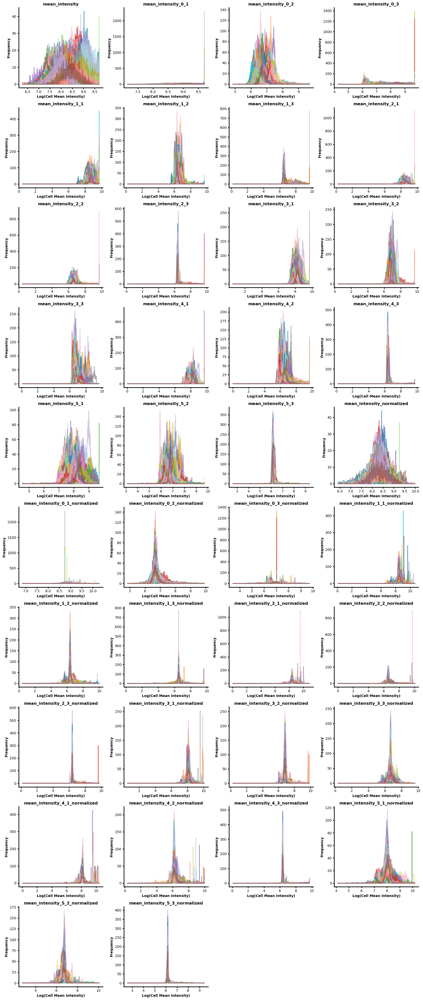

In [8]:
intensity_ranges, histograms, gmm_models = process_sample_distributions(
    feature_input       = adata,
    num_bins            = 1024,
    plots_per_row       = 4,
    dpi                 = 100,
    xlims               = None,
    ylims               = None,
    output_figure_path  = "feature_histogram_distributions.svg",
    verbose=True
)


-------------------- Processing marker 'mean_intensity' --------------------
☑️ No reference provided → will select by proximity
☑️ No landmarks → automatic alignment to mean, selecting 'TMA9_13' by histogram proximity 

✨ Computed shifts: [-38, 143, -85, -29, -175, -39, -99, -169, -85, -124, -8, -42, -169, 54, 49, -23, -133, -32, -88, 19, 183, 41, -101, 16, -15, 233, 114, 110, -33, -65, 283, -53, -7, 9, -39, -59, -118, 40, -5, -57, 146, 93, -47, -1, 19, 83, 90, 67, -50, -2, 31, -121, -95, 31, 205, -25, -170, -3, -81, -5, -10, 174, 61, -122, 0, 166, -79, -98, 6, -80, 102, 150, -90, -55, -131, -213, -230, -11, -53, 76, -65, 32, -31, 73, 47, -64, 12, -119, -194, -75, -21, 65, -49, -99, 160, 207, 2, 80, -23, 76, 74, -149, -143, -122, 11, -196, 147, -3, 0, 177, -138, -239, -174, -19, -75, -32, -119, -174, -59, -14, -106, -53, -77, 46, -124, -47, -7, -96, -31, -62, -194, 85, -13, 92, 17, -12, -87, -1, -34, 35, 123, 78, -141, 85, -105, -171, 42, -53, -14, -123, -142, 13, -107, 39, 50, 109, 

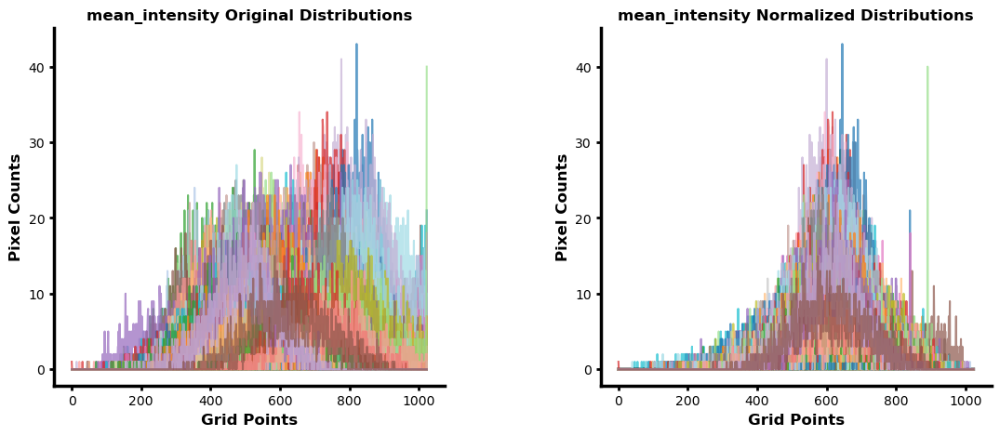


-------------------- Processing marker 'mean_intensity_0_1' --------------------
☑️ No reference provided → will select by proximity
☑️ No landmarks → automatic alignment to mean, selecting 'TMA11_78' by histogram proximity 

✨ Computed shifts: [-65, 146, -161, 110, 74, -69, 97, 117, 103, -29, 21, 115, 171, 39, 237, 100, 55, -120, 122, 77, -32, 31, 83, -191, 223, 207, 191, 160, 214, -151, 93, 223, -7, 1, -31, 81, -63, -70, 168, -9, 203, 131, 37, 122, 36, -145, -162, -9, -157, -76, 82, 348, -37, 139, -23, 111, -232, -31, -29, -53, -14, 280, 25, -63, 26, 128, 7, 51, 260, 309, 146, 46, 95, -26, 105, 21, 102, 1, 4, 161, -172, -192, 135, 241, 16, -145, -61, -52, -96, -141, 36, -48, 72, 237, 223, 112, -28, -39, 84, 138, 260, 164, 81, -180, -23, -178, 31, -140, -53, 385, 95, 61, 58, -124, 122, -129, 46, 76, 193, 64, -15, -48, 119, 111, 41, 147, -10, 113, 62, 53, 12, 85, -12, 117, -83, -12, 385, 114, 85, 37, 49, 55, -120, -37, -46, 6, 38, -37, 385, -250, -233, 74, -61, 106, -114, 280, 221, 65

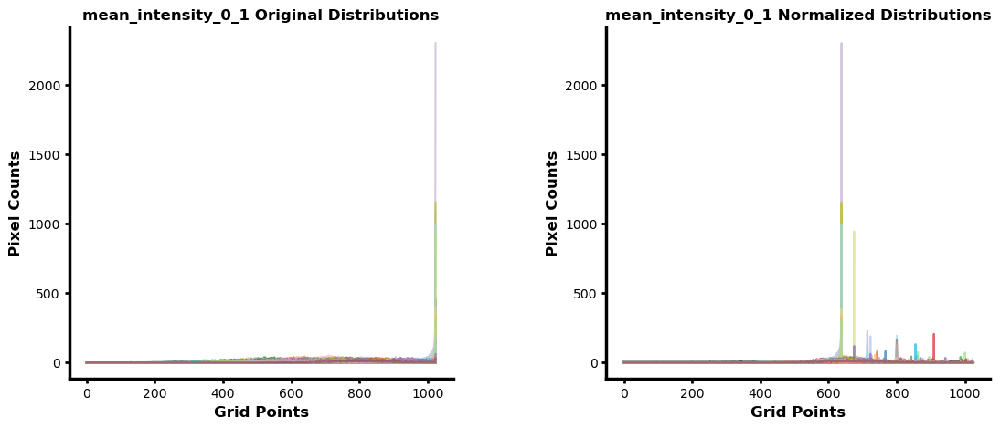


-------------------- Processing marker 'mean_intensity_0_2' --------------------
☑️ No reference provided → will select by proximity
☑️ No landmarks → automatic alignment to mean, selecting 'TMA11_87' by histogram proximity 

✨ Computed shifts: [121, 26, -86, 57, -8, -49, 18, 46, -2, -37, 3, 4, 48, -18, 61, -1, -7, 84, 19, 8, 95, -18, 37, 21, 89, 19, 30, 27, 46, 6, -10, 134, -27, 130, -37, 11, 42, 23, -29, -57, 36, -5, 67, 8, 91, -53, 63, -41, -53, -44, -6, 102, -15, -6, -45, 75, -104, 42, 19, 117, -21, 62, 3, -52, -14, 1, -24, -7, 95, 118, 41, 0, 7, 44, 35, -12, 37, -36, 73, 110, 54, -109, 51, 65, -32, 6, 12, 65, 87, 78, -34, 31, -21, 105, 51, 5, 82, -47, -20, 35, 83, 32, 46, 5, -36, 73, -23, 68, 122, 151, 16, 12, -12, -58, 24, 66, -17, 29, 70, 75, -42, -56, 2, 8, -23, 38, -42, 14, -4, 0, 78, 4, 96, -7, 46, 33, 97, 125, -22, -26, -20, -14, 110, -60, -40, -17, 15, -33, 276, 51, 0, 18, -56, 93, -75, 91, 77, 72, 100, -88, 4, -16, 32, 87, 131, 86, -55, 79, 84, 87, 2, -5, -73, 52, 56, 86,

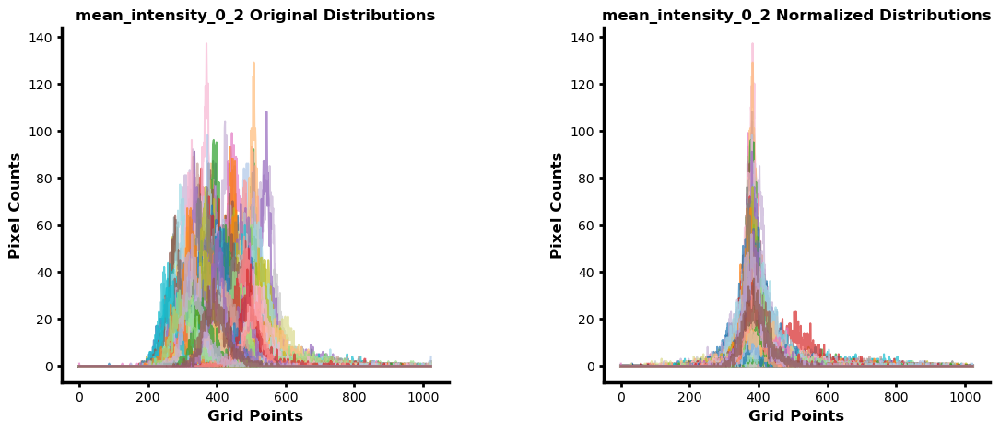


-------------------- Processing marker 'mean_intensity_0_3' --------------------
☑️ No reference provided → will select by proximity
☑️ No landmarks → automatic alignment to mean, selecting 'TMA0_24' by histogram proximity 

✨ Computed shifts: [23, -6, 41, 123, 356, 4, 218, 251, 307, 47, 503, 333, 87, 322, 434, 229, 237, 7, 503, 156, -81, 298, 430, -44, 317, -20, 451, 319, 184, 29, 3, 26, 170, -68, 29, 23, -3, 52, 62, 503, 384, 405, -76, 407, 44, 503, 13, -10, 335, 407, 24, 168, 394, 34, -4, 115, 106, 23, 148, -68, 1, 6, 422, 13, 213, 394, 275, 250, 224, 56, 503, 481, 344, -50, 276, 279, 237, 389, -13, 153, -3, -13, 307, 95, 64, -11, 51, 19, -71, 200, 155, 11, -15, 193, 407, 0, 244, 253, -8, 338, 141, 58, 333, -6, 114, -63, 192, 63, -71, 162, 64, 409, 388, 434, 125, 4, 236, 255, 117, -45, 425, 188, 260, 167, 265, 73, -5, 123, 66, 204, -17, 373, 96, 41, -42, 103, 351, 14, -24, 13, 514, 5, -12, 250, 241, 428, 407, 140, 224, 9, -22, 232, 8, 185, 144, 407, 117, 111, -10, 64, -43, 503, 93,

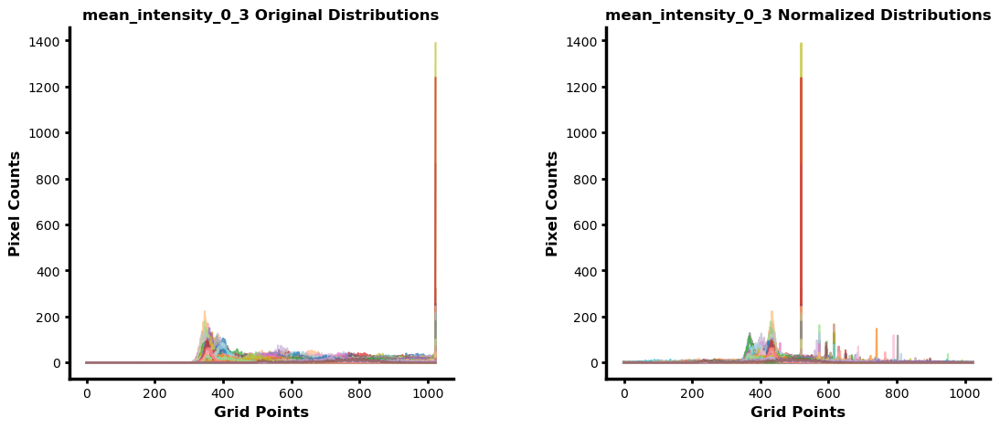


-------------------- Processing marker 'mean_intensity_1_1' --------------------
☑️ No reference provided → will select by proximity
☑️ No landmarks → automatic alignment to mean, selecting 'TMA14_89' by histogram proximity 

✨ Computed shifts: [5, 27, -36, 0, 8, -14, 9, 80, 17, -16, -57, 23, 38, -12, 52, 44, -3, -1, 18, 26, -16, -26, 68, -42, 67, 30, 54, 35, 45, -45, 24, 54, 13, -11, -45, 20, -26, -29, 21, -10, 22, 32, 7, 13, -16, -90, -28, 3, -60, -58, 61, 43, -38, 28, -5, 19, -41, -3, -16, -20, 15, 60, -31, -9, 40, 14, 4, 7, 62, 92, 25, -17, 14, -11, 49, 4, 59, -41, -7, 36, -38, -48, 78, 56, -5, -51, -25, -20, -14, -50, -4, -22, 32, 71, 50, 32, -18, -6, -17, 35, 89, 26, 58, -30, 5, -38, 10, -42, -5, 85, 8, 26, 14, -71, 35, -32, 10, 54, 62, -22, 0, 0, 14, 28, 4, 25, 4, 22, 12, 71, 4, 25, -7, 32, -24, -22, 61, 24, 28, 7, -17, 26, -23, -6, -11, -42, -44, -14, 92, -48, -46, 44, -18, 28, -23, 47, 72, 16, 9, -7, -42, 2, -18, 53, -22, -22, -11, 85, 62, -8, -29, 41, -92, -27, -20, 1, 18, 2

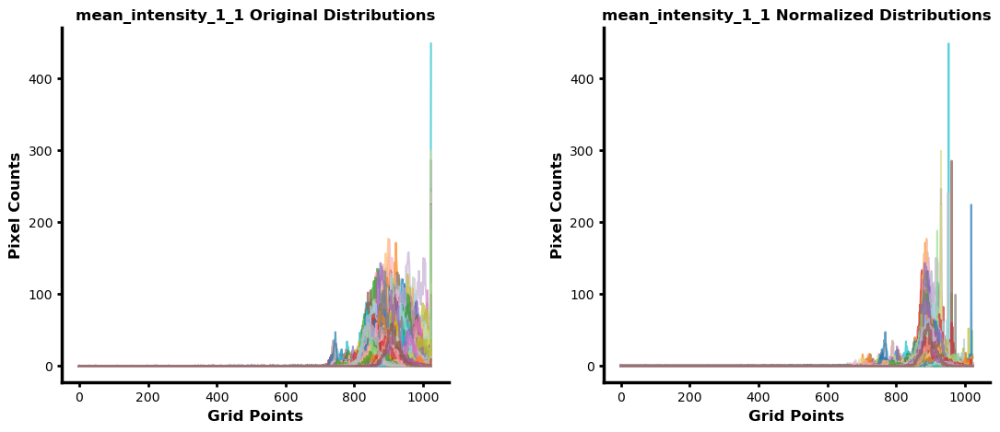


-------------------- Processing marker 'mean_intensity_1_2' --------------------
☑️ No reference provided → will select by proximity
☑️ No landmarks → automatic alignment to mean, selecting 'TMA11_27' by histogram proximity 

✨ Computed shifts: [35, 12, -33, 13, -3, -20, 2, 60, -8, -6, -19, -2, 16, -17, 20, -1, -4, 27, 1, -6, 22, -21, 47, -6, 29, 12, 4, 13, 13, -9, 1, 45, -11, 32, -18, 7, 3, 1, 0, -21, 7, -7, 13, 1, 16, -38, 13, -16, -33, -29, -1, 17, -22, 3, -17, 21, -35, 1, 0, 24, -2, 27, -18, -25, 23, -1, -21, -3, 36, 52, 19, -19, -8, 5, 27, -5, 49, -32, 19, 32, 5, -36, 58, 13, -5, -9, -2, 10, 18, 8, -20, -1, 2, 78, 27, 6, 23, -15, -7, 23, 75, 3, 50, 2, -16, 8, -10, 13, 27, 55, -1, -2, -5, -37, 0, 18, -6, 45, 21, 13, -19, -18, -1, -1, -14, 11, -9, -1, -13, 60, 22, 3, 24, -1, 11, 11, 35, 45, -8, -9, -21, -2, 23, -21, -20, -24, -20, -13, 121, 7, -15, 48, -23, 27, -22, 24, 63, 22, 26, -14, -11, -10, -2, 28, 31, 16, -5, 81, 32, 23, -18, 21, -39, 11, 8, 28, 11, 22, 52, 8, -5, -36, 8, -3

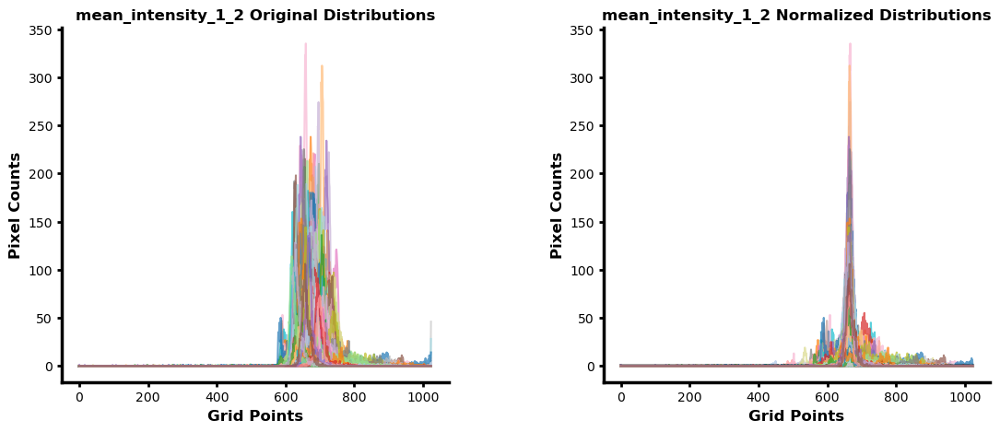


-------------------- Processing marker 'mean_intensity_1_3' --------------------
☑️ No reference provided → will select by proximity
☑️ No landmarks → automatic alignment to mean, selecting 'TMA0_31' by histogram proximity 

✨ Computed shifts: [8, 3, -2, -1, -9, -3, 4, 80, -6, 1, -2, -1, -7, -3, 7, -1, -8, 7, 1, 5, 1, -1, 174, 2, -1, 3, -3, 20, 122, -2, -3, 11, -2, 3, -5, 13, 9, 0, 5, -8, -3, -6, 2, 12, -2, 0, 0, -1, -10, -9, -4, -1, -3, 2, -7, 0, -6, -2, -4, 2, 12, 13, -6, 2, 102, 5, 0, -3, 6, 15, 2, -2, -9, 0, 10, -5, 99, -6, 6, -1, 6, -8, 154, -3, 6, -1, -4, 6, -5, -2, -8, -1, 7, 78, 3, 0, 1, -5, -6, 4, 44, -2, 142, 0, -1, 4, -2, 3, 4, 11, -1, -2, -8, -6, -5, 3, -1, 150, -3, -1, 0, 0, -7, 5, -6, 5, 2, -3, -4, 90, -3, -5, 5, -4, 1, -4, 2, 16, 4, 7, -1, 11, 7, -8, -9, -7, -6, -3, 32, 8, -1, 70, -7, 2, -3, 9, 29, 7, 5, 3, -2, -8, -1, 14, -3, 2, -12, 72, -2, -5, -2, 1, -8, 3, 4, 1, 70, 2, 46, 23, -6, -3, -1, -5, 5, -4, 14, -5, -8, 343, -5, -7, 49, -6, -7, -11, -7, -1, -4, -10, -4, 1, 0

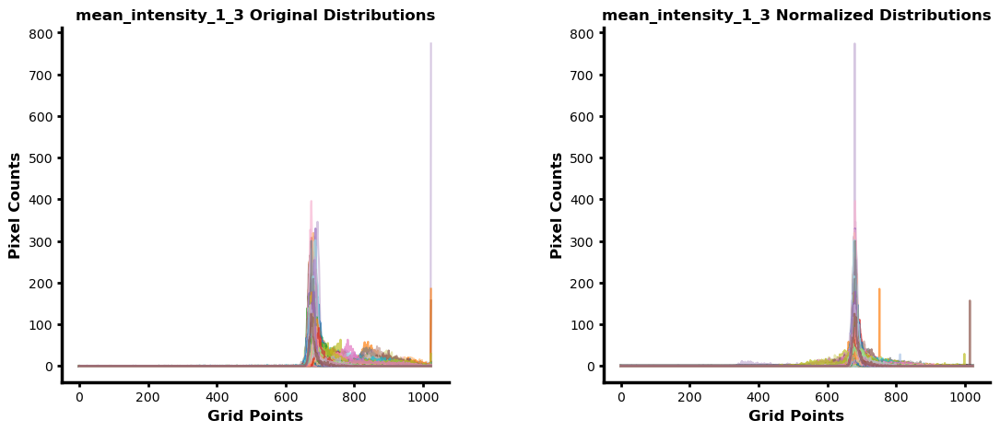


-------------------- Processing marker 'mean_intensity_2_1' --------------------
☑️ No reference provided → will select by proximity
☑️ No landmarks → automatic alignment to mean, selecting 'TMA6_37' by histogram proximity 

✨ Computed shifts: [-13, 30, 25, 12, 18, -19, 32, 33, 10, -8, -41, 11, 39, -1, 55, 31, 10, -33, 24, 22, -16, -24, 28, -34, 58, 42, 46, 44, 35, -16, 24, 37, 10, -22, -8, 13, 12, -2, 0, -12, 34, 32, 5, 13, -14, -83, -30, -8, -61, 10, 9, 36, -41, 18, 6, 25, -39, 7, -15, -42, 9, 61, -30, -16, 12, 19, 5, 5, 66, 85, 18, -19, 22, -4, 25, 0, 20, -40, -4, 27, -43, -47, 35, 62, -3, -37, -7, -17, -33, -45, 4, -5, 22, 56, 49, 25, -8, -11, 7, 28, 65, 36, 10, -30, 6, -49, 1, -42, -24, 97, 34, 26, 13, -66, 25, -33, 6, 29, 52, 14, -13, -6, 17, 30, 6, 17, -5, 32, 16, 34, -4, 20, -12, 19, -14, -13, 65, 21, 28, -2, -17, 24, -44, 2, -31, -37, -37, 0, 142, -50, -49, 25, -11, 18, -17, 49, 61, 14, -12, -10, -32, 0, -27, 49, -35, -17, -7, 57, 62, -21, -20, 5, -69, -35, -16, 10, 6, 37, 35

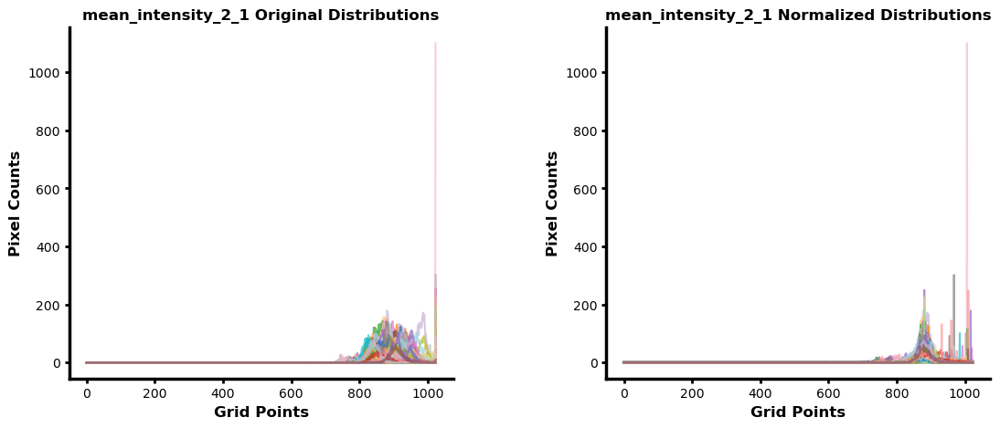


-------------------- Processing marker 'mean_intensity_2_2' --------------------
☑️ No reference provided → will select by proximity
☑️ No landmarks → automatic alignment to mean, selecting 'TMA6_77' by histogram proximity 

✨ Computed shifts: [15, 1, -2, 11, -8, -23, 9, 9, -16, -24, -19, -6, 8, 0, 27, -3, -1, 5, 4, -1, 4, -17, 7, -2, 26, 14, 18, 23, 11, 5, 9, 35, 2, 6, -12, -14, 23, 13, -18, -22, 6, 10, 12, -7, 28, -44, 8, -30, -36, 11, -8, 2, -23, -5, -13, 21, -38, 18, -3, -7, -13, 22, -16, 5, -7, 4, -8, -9, 26, 35, 6, -1, 8, 9, 3, -11, 0, -19, 8, 38, -12, -46, 11, 17, -18, -13, 17, 1, 2, 10, -13, 11, -11, 25, 20, 6, 25, -10, -11, 8, 26, 8, -1, 3, 0, -12, -11, 16, 4, 42, 3, 4, -3, -38, 7, 14, -8, 4, 27, 18, -24, 1, -4, 6, -21, -8, -24, 8, 18, 14, 18, 3, 22, 4, 8, 1, 23, 34, -8, -18, 26, 14, -1, -8, -36, -16, -15, -25, 109, -5, -15, 5, -30, 30, -13, 25, 32, 31, 5, -21, -12, 0, -13, 23, 0, 28, -21, 23, 27, -1, -23, -24, -42, 8, -1, 8, 12, 18, 9, 7, -4, -25, 6, -17, -32, -9, 66, -8, 9,

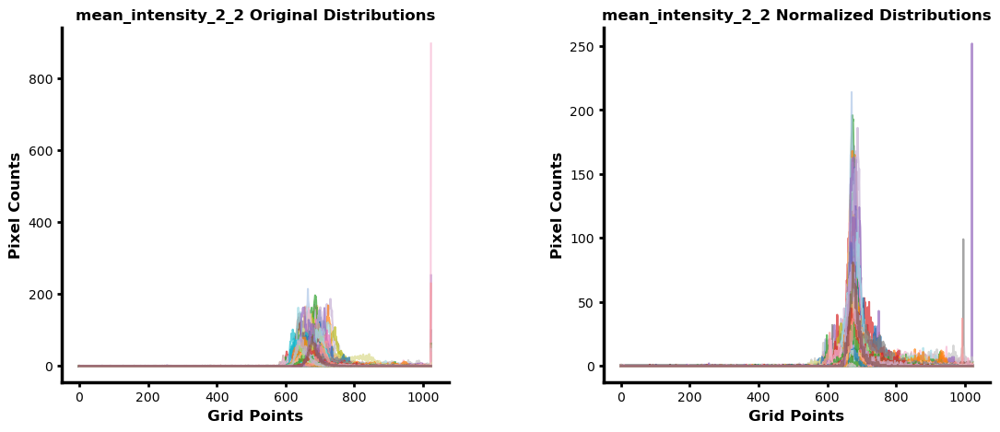


-------------------- Processing marker 'mean_intensity_2_3' --------------------
☑️ No reference provided → will select by proximity
☑️ No landmarks → automatic alignment to mean, selecting 'TMA6_9' by histogram proximity 

✨ Computed shifts: [5, -2, -2, 5, -4, -2, -2, 0, -6, -5, 0, -2, 0, 3, -1, -3, -5, 2, -3, -2, 3, 1, 1, 2, 3, -1, 0, -1, 0, 7, -1, 10, -2, 5, -4, -2, 8, 7, -1, -7, 0, -3, 8, -4, 3, -1, 3, -6, -1, 6, -3, 6, 0, -3, -3, 7, -10, 6, 2, 2, -3, -1, 1, -4, -2, -1, -3, -4, 4, 8, -3, 2, 0, 5, -1, -4, 1, 1, 3, 3, 0, -8, 2, 1, -4, 2, 8, 4, 3, 0, -6, 6, -3, 6, 1, -3, 4, -7, -5, -2, 4, 0, -1, 3, -2, 2, -4, 0, 4, 7, -3, -2, -2, -3, -1, 2, -3, 0, 1, 6, -8, -5, -3, 1, -5, -4, -3, -1, -2, 0, 3, -3, 4, -6, 5, 5, 2, 8, -3, -4, 2, -1, 3, -6, -8, 1, 3, -7, 28, 1, 1, -1, -6, 3, -6, 2, 5, 9, 3, -6, 2, -6, 4, 0, 2, 3, -3, 4, 4, 2, 2, -6, -2, 2, 3, 5, -3, 2, 0, 3, -5, -10, -2, -5, -5, -3, 16, 2, 2, 7, 2, -1, 0, -3, -1, -8, -1, -6, -1, -6, -3, 1, 4, 2, -3, -2, -5, -1, 1, -6, -4, 8, 4, -7, 3, 3

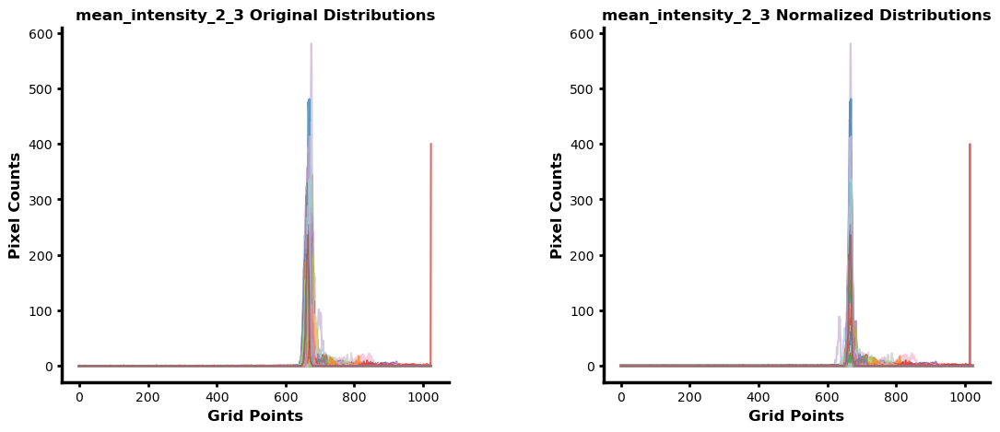


-------------------- Processing marker 'mean_intensity_3_1' --------------------
☑️ No reference provided → will select by proximity
☑️ No landmarks → automatic alignment to mean, selecting 'TMA14_88' by histogram proximity 

✨ Computed shifts: [-20, 22, -38, 4, 1, -18, 28, 17, 6, -13, -35, 5, 32, -13, 34, 32, 1, -40, -3, 21, -16, -24, 4, -41, 41, 36, 37, 17, 29, -10, 28, 42, 3, -33, -22, 12, -17, -7, -3, -21, 32, 16, -2, 1, -20, -60, -31, -6, -53, -49, 6, 10, -32, 10, 2, 20, -44, 4, -25, -51, 4, 57, -28, -10, -1, 8, 0, -9, 68, 69, -2, -7, 11, -9, 7, 0, 12, -42, -8, 23, -44, -39, 22, 55, -3, -34, -11, -14, -39, -36, 5, 4, 16, 28, 23, 18, -7, -15, -3, 12, 42, 22, -2, -40, -2, -54, 19, -38, -26, 84, 26, 15, -3, -63, 17, -34, 1, 0, 45, 9, -43, -11, 6, 34, 2, 0, 2, 24, 16, 27, 95, 10, 61, 11, -16, -13, 49, 19, 25, -4, -7, 17, -47, 8, -38, -32, -39, -3, 139, -43, -43, 13, -16, 9, -24, 31, 39, 10, -24, -12, -17, -3, -27, 35, -47, -8, 6, 35, 54, -40, -16, -22, -61, -22, -15, -2, -7, 1, 20, -

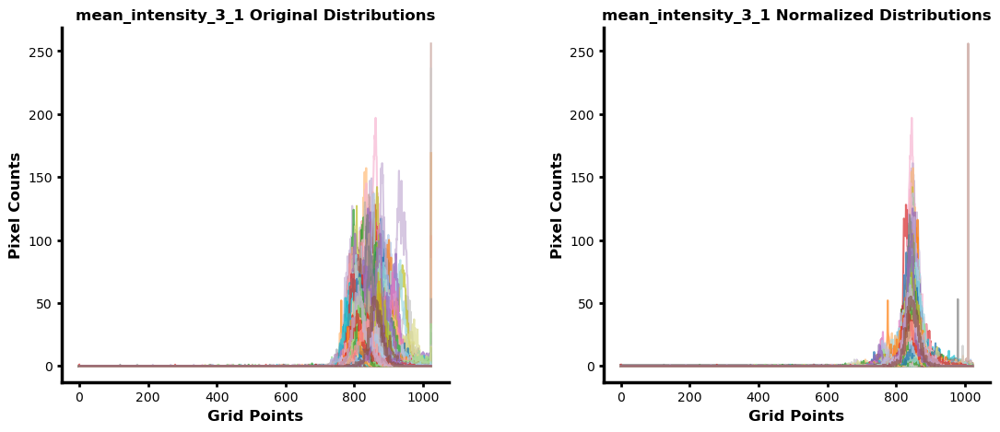


-------------------- Processing marker 'mean_intensity_3_2' --------------------
☑️ No reference provided → will select by proximity
☑️ No landmarks → automatic alignment to mean, selecting 'TMA14_88' by histogram proximity 

✨ Computed shifts: [8, -5, -26, 11, -8, -28, 94, 1, 21, -40, -3, 8, 18, 16, 17, 9, -3, -17, -1, 21, 9, 4, -6, -15, 16, 25, 25, 11, 12, -4, 42, 29, -8, -3, -7, -26, -8, 14, -32, -15, 27, 15, 14, 0, 17, -42, 5, -23, -18, -22, 16, 9, -2, 10, 17, 24, -31, 9, -7, -21, -17, 13, 10, -13, -12, 30, -5, -5, 26, 29, 1, 34, 27, -1, -12, -11, -10, -22, 4, 18, -10, -34, 7, 30, -11, -19, 0, 3, -10, -2, 0, 21, -11, 7, 22, 20, 22, -1, -4, 9, 32, 22, -6, -19, 4, -23, 26, -3, 6, 78, -1, 1, -2, -29, 4, 3, -2, -15, 24, 15, -25, -15, -15, 28, 11, -4, -30, 35, 12, 4, 62, 9, 42, 16, 6, 11, 26, 39, -7, -14, 43, 16, -15, 19, -16, -2, 27, -2, 93, -1, -25, -5, -20, 7, -11, 23, 27, 19, -8, 4, 1, 17, -14, 36, -11, 14, -6, 14, 25, -11, -5, -28, -35, 8, 7, 14, 9, 4, 10, 19, 13, -12, 14, -11, -4

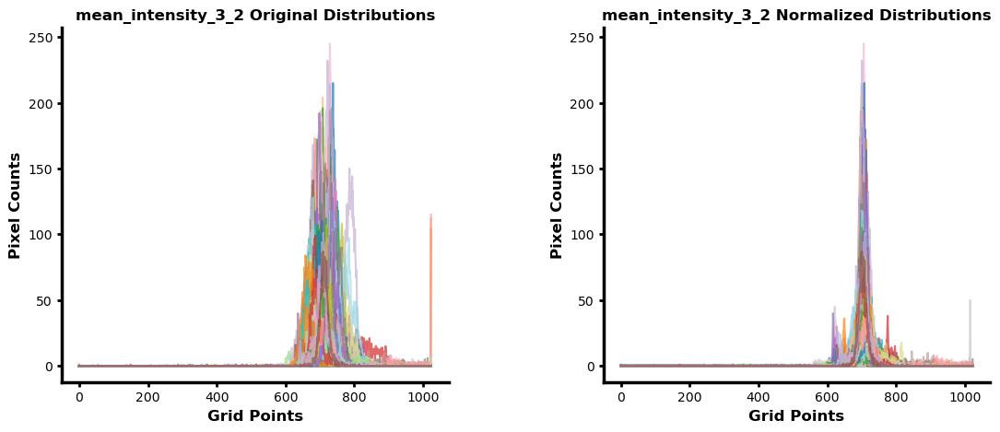


-------------------- Processing marker 'mean_intensity_3_3' --------------------
☑️ No reference provided → will select by proximity
☑️ No landmarks → automatic alignment to mean, selecting 'TMA10_47' by histogram proximity 

✨ Computed shifts: [-16, -32, -11, 5, 31, -9, 58, 6, 22, 9, 13, 60, -6, 16, 13, 50, 8, -5, 47, -5, -11, 21, -3, 123, 39, 44, 39, 28, 24, -3, 16, 6, 12, -2, -10, -23, 9, 0, -39, 45, 18, 44, -3, -21, 51, -12, 67, -18, -8, -6, -3, 13, 12, -9, -22, -6, 10, -11, -2, 10, -33, -26, 50, 7, 21, 98, -1, 12, 1, -6, -12, 166, 68, -1, 5, -26, -10, -6, 22, 83, -4, 13, 90, -17, 2, -22, 153, 10, -17, -21, 8, -5, -21, 10, -12, -7, 22, 59, 67, -13, 24, -1, -23, 2, 7, -12, 57, 4, -1, 52, -29, -2, 83, -9, -3, 36, 14, -20, -5, -5, 48, 7, 3, 17, 31, -20, -41, 8, 26, 22, 26, 78, 62, 6, 7, -15, 96, 15, -11, -6, 114, 4, 16, 98, 13, 71, -6, -2, 50, -20, -18, 8, -7, 51, -5, 24, 19, -3, -7, -8, -7, 43, -16, 36, 8, 22, 31, 18, 48, -21, 38, -17, -14, 59, 9, -1, 58, -16, 12, 17, 44, 32, 12, -1

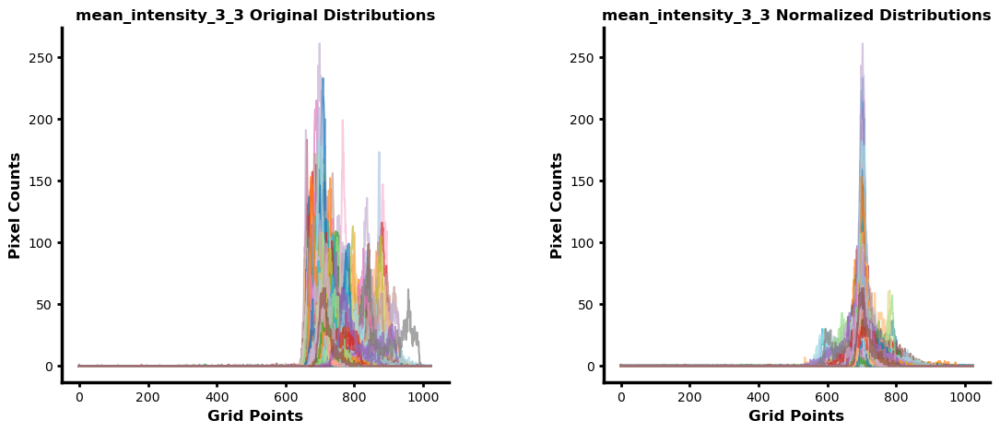


-------------------- Processing marker 'mean_intensity_4_1' --------------------
☑️ No reference provided → will select by proximity
☑️ No landmarks → automatic alignment to mean, selecting 'TMA14_88' by histogram proximity 

✨ Computed shifts: [-35, 23, -34, 3, 20, -17, 25, 6, 20, -7, 12, 21, 20, -15, 31, 30, -8, -61, -8, 20, -22, -37, -10, -51, 25, 27, 14, 22, 28, -24, 23, 24, 1, -44, -26, 6, -23, -22, -5, -22, 23, 6, -26, -5, -21, -77, -41, -8, -69, -66, -3, 20, -35, 4, -6, 12, -47, 5, -37, -63, -5, 52, -45, -22, -12, 4, -3, 8, 39, 55, -2, -6, 22, -23, -4, 0, 6, -43, -20, -5, -53, -32, 14, 46, -6, -38, -20, -23, -47, -58, -13, 5, 12, 9, 18, 18, -17, -16, -14, 2, 43, 31, -14, -43, -8, -67, 16, -54, -41, 82, 22, 17, 1, -74, -2, -39, -1, -6, 25, -10, -10, -15, 13, 29, 17, 4, -5, 30, 14, 6, -17, 14, -39, 9, -16, -5, 43, 9, 21, -4, 2, 2, -67, -1, -29, -39, -28, -11, 134, -48, -56, 0, -6, -15, -26, 30, 33, -2, -39, -14, -45, -8, -22, 35, -64, -32, -3, 24, 40, -39, -15, -27, -74, -47, -17

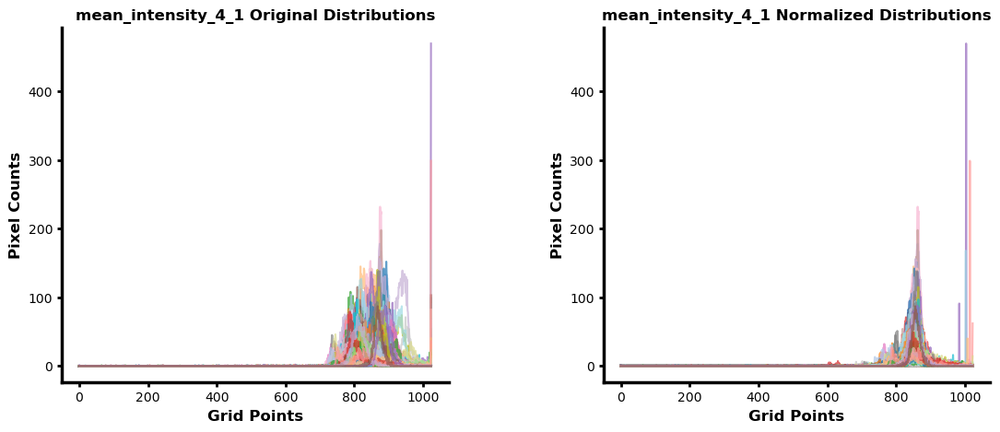


-------------------- Processing marker 'mean_intensity_4_2' --------------------
☑️ No reference provided → will select by proximity
☑️ No landmarks → automatic alignment to mean, selecting 'TMA0_67' by histogram proximity 

✨ Computed shifts: [-10, 27, -13, 5, 109, 3, 38, -4, 104, -34, 147, 97, -8, 28, 15, 1, -20, -32, -8, 55, -2, 25, -4, -29, -4, 30, 7, 26, 119, -16, 22, 10, 33, -24, -6, -4, -14, 14, -20, 86, 3, 7, 5, 3, 12, -16, -17, -12, -18, -3, 14, 40, 61, 6, -10, 15, -7, -1, -23, -34, -3, 61, -7, 29, -18, 17, 40, 90, 6, 11, -11, 56, 96, -1, -28, 38, -13, 36, 4, -6, -21, 0, 12, 46, 49, -26, -17, -7, -18, -38, 0, 5, 44, -12, 0, 8, 8, 10, 12, -5, 21, 80, -7, -31, 29, -21, 52, -21, -21, 61, 41, 41, 61, -13, -21, 6, 58, -8, 5, 10, 92, 15, 81, 57, 115, -11, -14, 69, 54, 2, 20, 47, -11, 18, -10, -4, 16, 20, 13, 17, 60, 58, -35, 20, 62, 43, 74, -9, 60, -27, -42, 2, -2, -14, 6, 5, 17, 11, -21, 25, -4, -5, -31, 15, -32, -11, 91, -8, 9, -9, 24, -39, -5, 2, -5, -8, 121, -10, -3, 14, 18, 3,

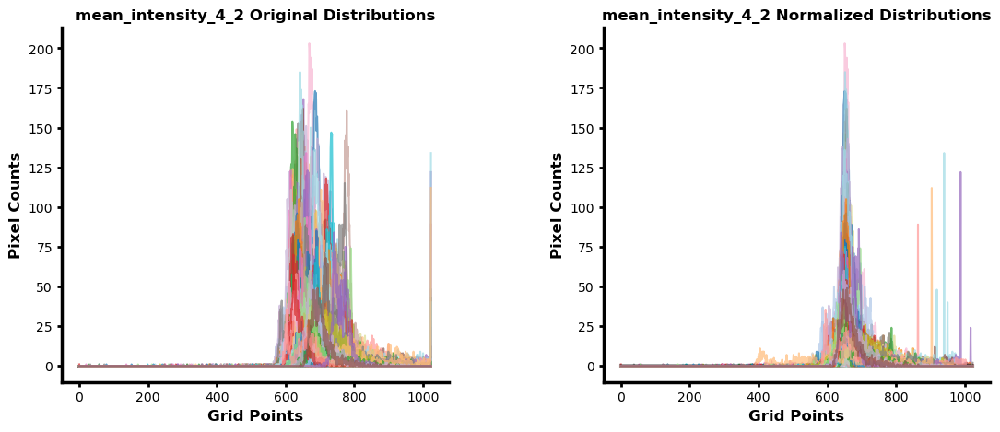


-------------------- Processing marker 'mean_intensity_4_3' --------------------
☑️ No reference provided → will select by proximity
☑️ No landmarks → automatic alignment to mean, selecting 'TMA5_73' by histogram proximity 

✨ Computed shifts: [3, 0, -4, 3, 24, -1, 10, 0, 16, -3, 9, 17, -4, 4, 1, -2, -5, 4, -3, 11, 5, 3, -1, 2, -3, 0, -3, 0, 1, 6, 0, 7, 4, 3, -3, -2, 6, 5, 1, 9, -4, -4, 4, -2, 5, 2, 3, -1, 2, 0, -4, 6, 3, -2, -3, 5, -5, 5, 2, 2, 0, 0, 5, 4, -3, 3, 7, 22, -3, 0, -2, 6, 19, 3, -2, 8, -1, 3, 4, 5, 2, 5, 1, 9, -2, 3, 3, 6, 2, 4, -4, 6, -1, -1, -3, -1, 6, -4, -5, -3, 1, 18, 1, 2, 4, 1, 8, 3, 3, 4, 9, 10, 15, 2, -3, 2, 11, -1, -2, 4, 13, 2, 10, 13, 17, -1, 0, 14, 10, 1, 5, 8, 4, -3, 5, 4, -1, 5, -1, -1, 8, 0, 3, -3, 10, 3, 3, -2, 10, 3, 2, 1, -2, 4, -3, -1, 1, 6, 3, -4, 1, 0, 4, -1, 3, 5, 22, 0, -1, 4, 4, -3, 6, 4, 3, 4, 15, -4, -1, 4, -4, -5, -3, 6, -2, 1, 3, 1, -2, 5, 5, 4, -2, 7, -4, -5, 4, -1, 11, 13, 9, 3, 5, 2, 1, -2, 4, 4, -1, 12, -2, 4, 0, 4, 4, 2, -1, -6, 1, 1, -6,

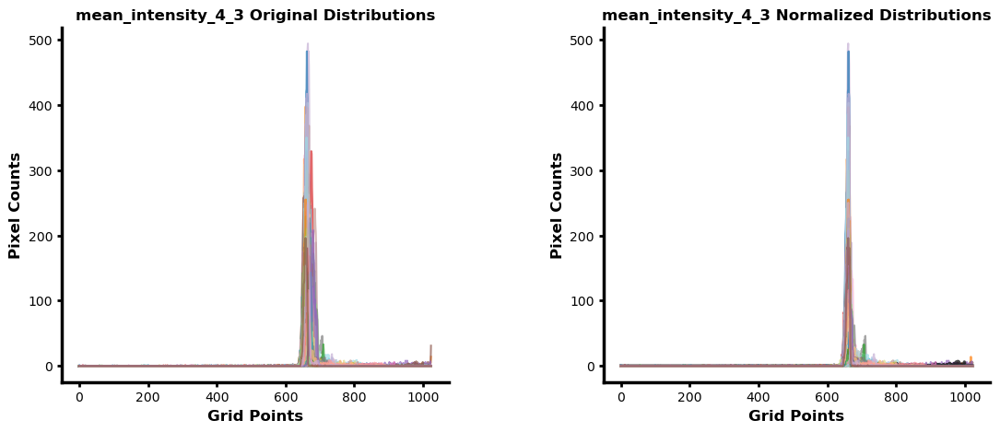


-------------------- Processing marker 'mean_intensity_5_1' --------------------
☑️ No reference provided → will select by proximity
☑️ No landmarks → automatic alignment to mean, selecting 'TMA5_34' by histogram proximity 

✨ Computed shifts: [-64, 78, -33, -1, 11, -9, 58, 20, -5, 0, -35, 79, 61, -30, 69, 95, 33, -83, -14, 62, -89, -21, -10, -100, 75, 69, 166, 54, 113, -40, 64, 46, 28, -78, -35, 37, -21, -18, -6, -43, 43, 107, -5, 16, 1, -120, 3, -10, -96, -98, 3, 2, -33, 13, 17, 18, -83, -3, -38, -114, 6, 127, -48, -19, 13, 79, 30, -33, 102, 97, 11, 54, 30, -12, 2, 32, 26, -64, -7, 63, -64, -51, 36, 102, 27, -73, -1, -22, -93, -44, 11, -3, 12, 36, 27, 45, 25, -82, -33, 11, 100, 52, -2, -67, 26, -129, 149, -40, -81, 194, 62, 47, -3, -130, 38, -30, 6, 15, 100, 13, -18, 13, -15, 68, -7, -2, 6, 46, 48, 20, 25, 19, -32, -2, -14, -27, 37, 43, 27, 17, 172, 25, -130, 82, -97, -11, -86, -24, 228, -67, -66, 17, 10, 69, -97, 62, 93, 5, -149, -13, -46, 31, -65, 54, -114, -7, 331, 34, 98, -81, -

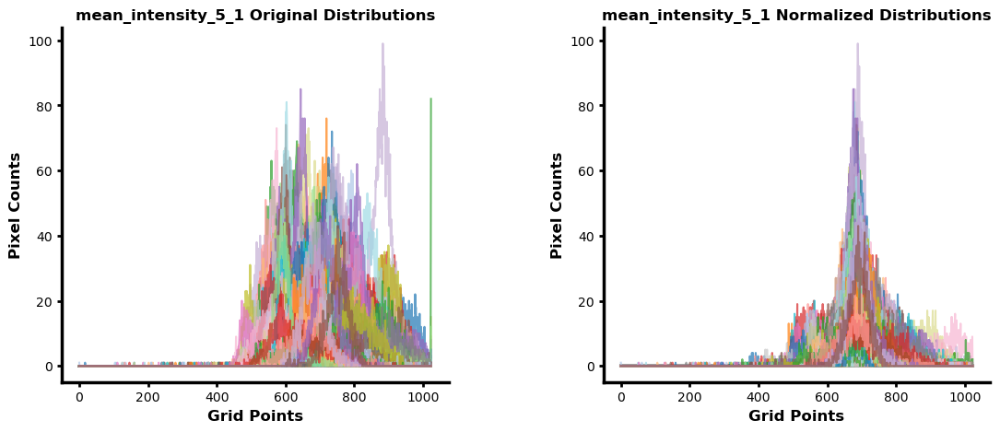


-------------------- Processing marker 'mean_intensity_5_2' --------------------
☑️ No reference provided → will select by proximity
☑️ No landmarks → automatic alignment to mean, selecting 'TMA6_31' by histogram proximity 

✨ Computed shifts: [-22, 20, -56, 2, -32, 14, 59, 14, -12, -55, -19, -14, 90, 6, -1, 29, 143, -67, -53, 60, -51, -34, -27, -27, 109, 64, 141, -1, 35, -11, 58, 39, 30, -42, -19, -50, 16, -4, -45, -63, 22, 123, 10, -31, 7, -89, 16, 2, -64, -79, 11, -15, -38, 27, 39, 13, -63, -8, -29, -73, -12, 59, -65, -24, -15, -4, 27, -44, 87, 30, -28, 18, -23, 25, -48, 18, -16, -57, -5, -15, -31, -44, -4, 74, 10, -50, -36, 43, -53, -48, -23, 26, -23, 13, 16, 65, 18, -21, -9, -22, 59, -17, -14, 21, 35, -90, 33, -40, -41, 114, 45, 52, -55, -59, 87, 16, -50, -16, 149, 44, -35, 42, -61, 60, -41, -37, -45, -3, 44, 0, 8, -14, -31, 22, 14, -8, -35, 41, -27, 0, 47, 43, -79, 28, -97, -29, -65, -31, 176, -33, 13, 8, 24, -32, -113, 6, 49, -3, -94, 11, -22, -20, -59, 6, -77, -25, 270, 27, 89

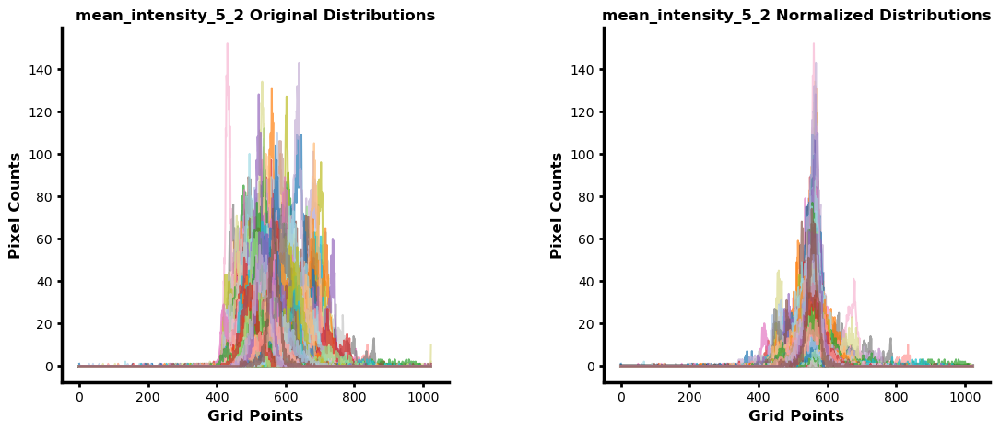


-------------------- Processing marker 'mean_intensity_5_3' --------------------
☑️ No reference provided → will select by proximity
☑️ No landmarks → automatic alignment to mean, selecting 'TMA11_5' by histogram proximity 

✨ Computed shifts: [3, -2, -8, 7, -7, 5, 9, 4, -9, -5, 6, -9, 20, 3, -8, 4, 26, 2, -8, 8, 3, 0, -1, 2, 23, 1, 23, -8, 4, 15, -2, 11, 5, 2, -7, -5, 7, 6, -2, -13, -7, 20, 5, -10, 8, 0, 5, 5, -2, -2, -8, 4, 0, -6, -3, 6, -11, 7, 5, 2, 1, 6, 1, -3, -3, -4, 3, -9, 19, 5, -9, 2, -8, 5, -6, 2, -2, -1, 5, 5, 2, -7, 0, 9, 3, 4, 4, 8, 3, 4, -9, 11, -2, 1, -6, -2, 7, -11, -9, -9, 6, -9, 1, 6, 3, -1, 3, 3, 2, 0, 5, 6, -10, -2, 18, 4, -9, 1, 24, 6, -12, 7, -9, 9, -11, -11, -7, -7, 5, 0, 9, -11, 5, -10, 9, 7, -3, 9, -3, 3, 5, -2, 1, -6, -12, 1, -2, -10, 37, 3, 5, 0, 2, 4, -11, -5, 6, 9, 1, -8, 4, -9, 8, -8, 1, 4, 220, 3, 19, 4, 0, 0, -3, 5, 8, 5, -8, -6, -4, 7, -9, -10, -9, 3, -6, 7, 26, 5, -3, 7, 2, 0, -4, -9, 29, -10, 1, 5, 7, -12, 5, 0, 5, 4, -3, -7, 0, 0, -5, -14, 27, 6, 1

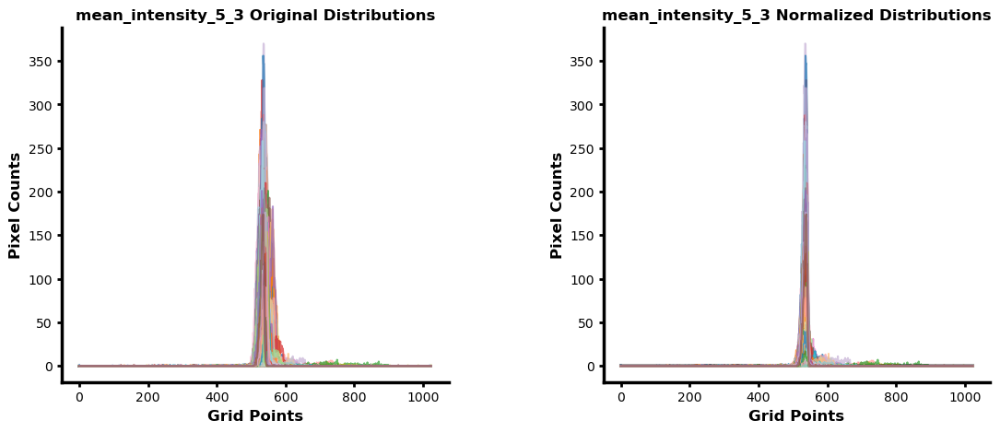


-------------------- Processing marker 'mean_intensity_normalized' --------------------
☑️ No reference provided → will select by proximity
☑️ No landmarks → automatic alignment to mean, selecting 'TMA9_72' by histogram proximity 

✨ Computed shifts: [31, -24, -17, -12, 28, 39, -3, -1, 14, -11, -21, -4, -2, -4, -29, -24, -6, -30, -2, 9, 12, 3, -20, -22, -16, -21, 27, -31, -27, 27, -5, -5, -31, -22, -20, -30, 8, 4, 4, -1, 17, -6, -14, -4, -21, -23, -2, -5, 46, -4, -29, 2, -21, 5, -1, 0, -17, -2, 3, -5, -15, 8, -14, -21, -29, -19, -4, 4, 0, -30, -4, -21, -13, -16, -4, -38, -19, -31, 1, 12, -23, -10, 15, 30, -15, -25, -33, -5, 0, 16, -39, 20, -5, 14, -18, -22, 25, 5, -8, -5, -33, 28, -15, 1, -12, -15, 11, 4, 1, -27, -27, 9, 11, 1, -18, -8, 0, 11, 23, 1, 14, 26, 29, 14, -3, -11, -23, -4, -17, 7, 25, -7, -9, -1, -37, -4, 20, -13, -19, -14, 11, 2, 7, 11, 15, -26, -41, -8, 20, -12, 4, 1, -26, -1, -15, 21, -17, -35, -2, -4, -9, -5, 5, -12, 2, -15, -22, -13, -35, -16, -1, 20, 26, -11, 5, -18, 

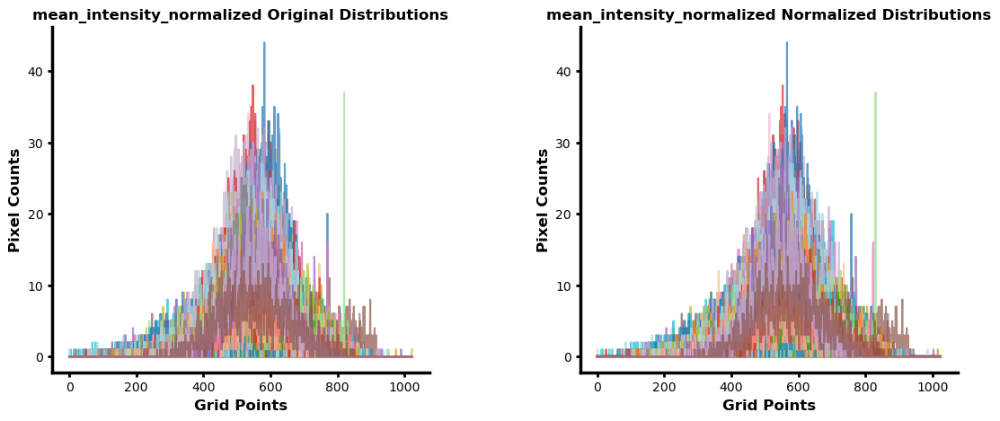


-------------------- Processing marker 'mean_intensity_0_1_normalized' --------------------
☑️ No reference provided → will select by proximity
☑️ No landmarks → automatic alignment to mean, selecting 'TMA1_0' by histogram proximity 

✨ Computed shifts: [3, -6, 4, 5, 4, 10, 18, 3, -3, 24, 14, 6, 7, -2, 18, 12, 2, 9, 11, -5, -9, -4, 2, -1, 12, 2, 4, 3, -15, 27, -4, -4, 11, -33, -15, 5, 16, 11, 116, -7, 9, -2, -3, -11, -22, 28, 10, -1, 12, 0, 10, -17, -9, -10, -5, -7, 11, 11, -13, -14, 1, 0, 2, 8, -10, -6, -9, -2, 6, 12, 4, 11, 0, 1, 7, 0, 1, -2, 0, -17, 5, 7, -6, 10, 6, 4, -27, 2, 2, -4, 5, -9, -2, 22, -18, -3, 8, 9, -7, 0, 2, 10, -25, 20, 6, -2, -9, -4, 0, -20, 14, 8, 8, 0, -3, -2, -2, -2, 10, 3, 16, -9, -7, -12, -3, 4, 0, -1, 6, -8, 10, 7, 3, -10, 7, 0, -45, 0, -8, 10, 3, 6, -1, 5, -5, -2, -6, 7, -20, 4, 8, 7, 4, 5, -10, 33, 18, 13, -6, -2, 0, 8, 26, 0, 14, -9, -45, 21, -3, 0, -1, 11, 30, 4, -1, 3, 0, -2, -8, -4, 9, 18, 9, -17, -20, 19, -20, -12, 4, 8, -7, -5, -10, -7, 2, -11, -5, 11

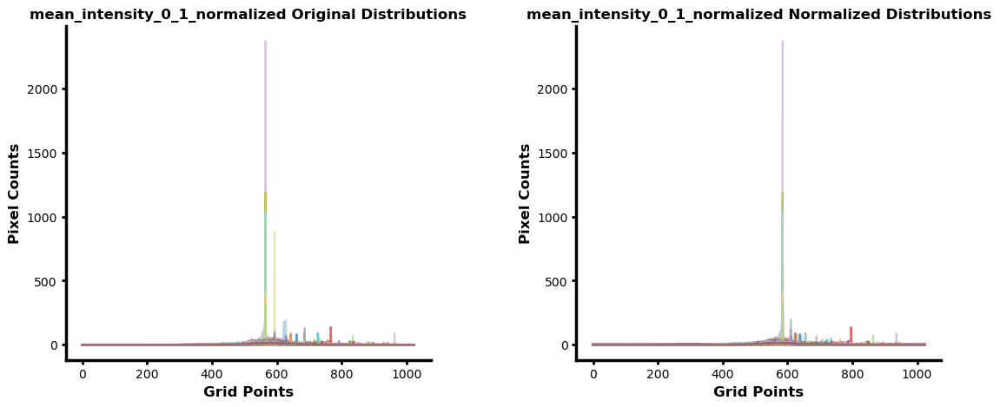


-------------------- Processing marker 'mean_intensity_0_2_normalized' --------------------
☑️ No reference provided → will select by proximity
☑️ No landmarks → automatic alignment to mean, selecting 'TMA7_88' by histogram proximity 

✨ Computed shifts: [-4, -1, -2, 7, 13, -8, 1, -2, -8, 11, 4, 2, 0, 3, 7, -1, 3, -1, 5, -10, 10, 1, 0, -4, -5, 25, -5, 0, 2, -1, 3, 1, -4, -4, -2, -5, 2, 2, 0, -1, 15, 0, -3, 11, -13, -4, 2, 2, -1, 0, -5, -3, -6, 11, -4, -5, -2, -4, 0, -3, -2, -4, 4, 9, 0, -3, -2, 3, 3, 13, 11, -2, -2, 8, 0, -2, 1, -2, 8, 1, -5, 7, 0, 0, 3, 7, -5, -4, -10, -10, 3, 1, 9, 13, 3, 7, 0, -2, -1, -4, 9, 0, -4, 4, -4, 4, -5, 1, -2, 6, 0, -4, -5, 2, 0, 4, 1, 2, -1, -4, 7, -1, -1, 3, 3, -2, -1, 4, 3, 20, -1, 0, -6, -1, 1, 7, 23, -4, 8, 6, 0, -4, -1, -1, -2, 0, -8, -5, 7, -6, 6, 3, -5, -2, 3, 14, 4, 6, 2, 6, -6, -9, 22, 12, -8, -5, -34, 12, 8, -2, 10, 0, -3, 9, 2, 13, -1, -1, -5, -4, -7, -6, 7, -1, 3, 8, 2, 5, 5, 1, -1, 0, 3, -3, -4, 2, 0, 1, 2, 3, -3, 8, -1, 4, 2, 13, 4, 4, 3, -4

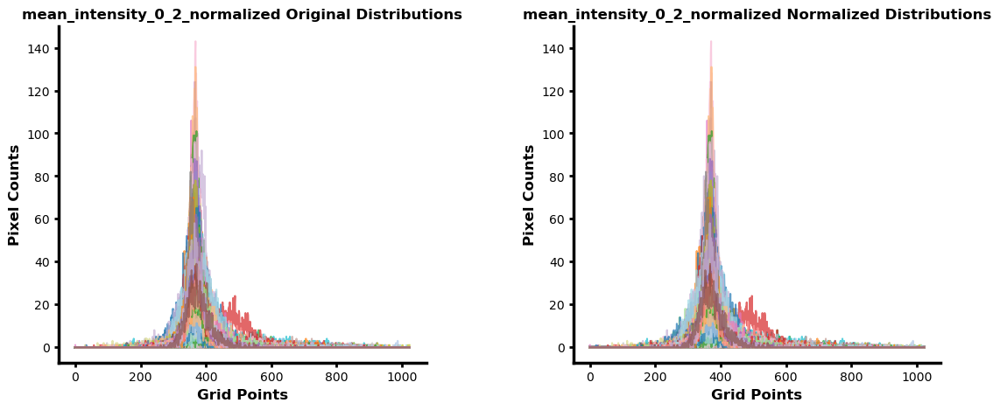


-------------------- Processing marker 'mean_intensity_0_3_normalized' --------------------
☑️ No reference provided → will select by proximity
☑️ No landmarks → automatic alignment to mean, selecting 'TMA1_0' by histogram proximity 

✨ Computed shifts: [-34, -23, 18, -13, 104, 44, -1, 31, -5, 22, 35, 64, 13, -7, 66, -6, 3, -12, 6, -1, 21, 38, 23, 7, 60, -7, 19, 94, 3, 11, -9, -13, 68, 25, -23, 7, -21, -11, 25, 54, 95, 4, 20, 118, -23, 94, 11, -22, 49, 43, 1, 68, 82, 11, -18, 51, -15, -16, 13, 21, -24, 17, 41, -11, 44, 54, 99, 30, 65, 17, 69, 3, 23, 3, 32, 119, 8, 38, -13, 3, -8, -9, 55, -26, 47, 13, 6, 2, 18, -40, 100, -6, 42, 23, 66, -8, 33, -4, 0, 131, -10, -19, 16, -22, -17, 21, 103, -2, 20, -10, 65, 16, 33, -5, 19, -32, 31, 76, 16, 3, -13, 88, -6, -2, 21, 2, 11, -9, -15, 36, -23, 56, 16, -28, 2, -13, 18, -15, -2, 12, 14, -26, -23, -10, 10, -2, 152, -1, -24, 16, -15, -6, -19, -4, 3, 58, 27, 0, -23, -4, 15, 41, -3, 24, 18, -11, 33, 22, 19, 1, 35, -9, 19, -25, -23, -22, 96, 96, 13, 

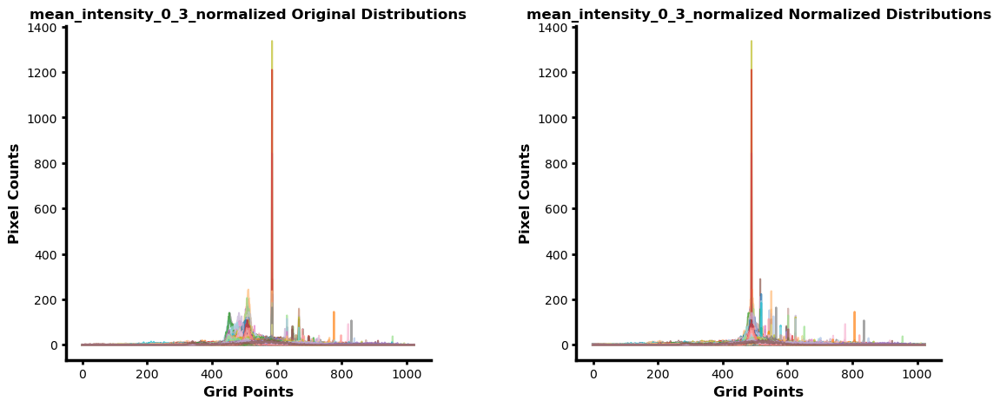


-------------------- Processing marker 'mean_intensity_1_1_normalized' --------------------
☑️ No reference provided → will select by proximity
☑️ No landmarks → automatic alignment to mean, selecting 'TMA7_56' by histogram proximity 

✨ Computed shifts: [-5, 5, -2, 18, 3, -1, 22, 2, -4, 13, 25, -5, 13, 2, -3, -6, 19, -5, 0, -3, 5, 11, -5, 2, -1, 18, -3, 2, 0, 11, 7, -6, -3, -1, 17, 3, 7, 5, 0, -2, 9, 1, -3, 1, -4, 20, -4, -1, 3, 11, -26, 7, -2, 8, 7, 2, 0, -2, 1, -2, -1, 3, 7, -3, 3, 4, -4, -1, 17, 7, 1, 0, -1, 1, 1, -1, 10, 7, 5, -4, -3, 4, -1, 7, 14, 9, 0, 4, -3, 2, -1, 0, 3, 27, -3, 0, 4, -3, 31, -1, 20, 4, 2, 1, -2, -3, 3, 0, -6, 15, 19, -6, -3, 7, 0, 4, -4, 5, 0, 30, -6, -2, 9, 5, -3, -1, -1, -2, 3, 13, -4, -5, 3, -1, 0, 12, 14, 6, 0, -1, -3, 2, -6, -3, -6, 3, 14, 7, 32, -5, -4, 24, 6, -3, -2, 7, 27, -2, -5, 2, 2, 2, 12, 3, -1, 0, 39, 20, 13, 0, 13, 3, 24, -2, 6, 19, 0, 3, -1, -1, 6, -4, -4, 6, -1, 19, 32, 12, 13, 3, -3, 22, 2, -5, 5, -5, 2, 1, -1, -2, -6, 12, 3, 1, 1, 2, 9, 9, 

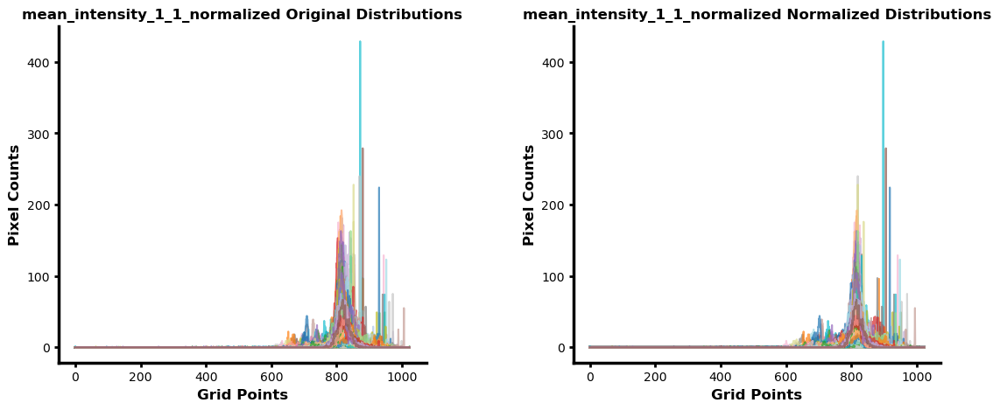


-------------------- Processing marker 'mean_intensity_1_2_normalized' --------------------
☑️ No reference provided → will select by proximity
☑️ No landmarks → automatic alignment to mean, selecting 'TMA13_47' by histogram proximity 

✨ Computed shifts: [1, -2, 0, 2, 2, -1, 2, 0, 0, 0, 0, -1, -1, 1, 1, 1, -3, -2, 1, -2, 1, -2, 1, 1, -1, 1, 2, 0, 0, 0, 0, -2, -1, -1, 2, 0, 0, -3, -6, 1, -1, 1, -1, 0, 1, 1, 1, -1, -1, -2, -10, -2, -3, -2, -2, -3, 1, -2, -1, -1, -1, -5, -1, 1, -1, -1, 0, -3, 1, -3, 1, 0, 2, 2, 0, 1, 3, 1, 0, 1, -1, -3, 0, 2, -2, -1, -3, 1, 0, -3, 1, 1, -1, 0, 0, -1, -5, -1, 1, -1, -1, 1, 1, -5, 2, 0, 2, -1, 0, 1, -2, -1, 0, 0, -1, 1, 1, 1, -2, 3, 2, 1, -1, 1, 0, 0, 1, -1, 1, 0, -1, -3, 1, -3, -1, 0, 12, -2, 2, 0, 1, 1, 2, 1, 0, -1, -8, -1, 2, 2, 0, 1, 1, 1, -1, -3, 1, -1, 1, -1, 1, -1, 6, 0, 0, 1, 7, -1, -3, -3, -1, 0, 2, 0, 1, -1, -1, -1, 0, 0, -1, 1, 1, 1, -1, 1, 1, 2, -1, -2, 0, 1, 2, 1, -1, -1, -3, 1, 0, 1, -1, -1, 0, 1, -1, 0, -3, 0, -1, 1, -4, -1, -1, 2, 1, 0, 0,

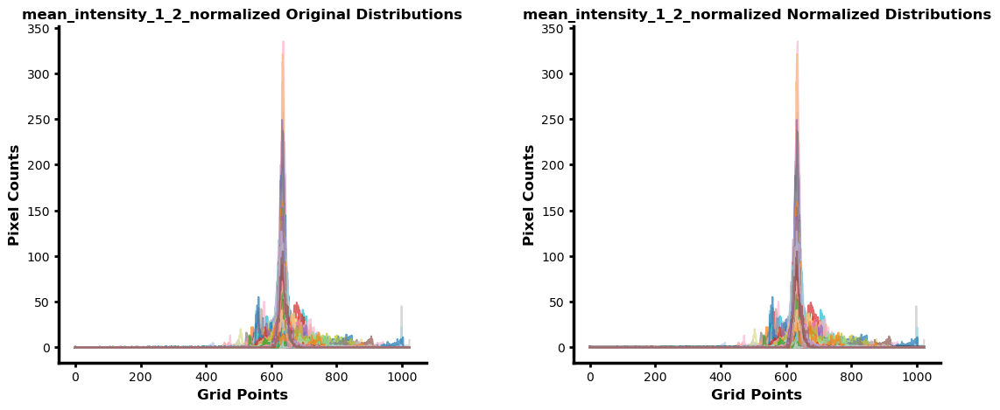


-------------------- Processing marker 'mean_intensity_1_3_normalized' --------------------
☑️ No reference provided → will select by proximity
☑️ No landmarks → automatic alignment to mean, selecting 'TMA6_78' by histogram proximity 

✨ Computed shifts: [-1, 0, -1, 0, 1, 0, 1, 1, -1, 0, 2, -1, 0, 1, -1, 0, 0, -1, 0, 0, -1, 0, 18, 0, -1, 1, -1, -1, -2, 0, 0, 0, 0, 2, -1, 0, 0, 0, -1, 0, 0, -1, -1, -1, -1, 1, 0, 1, 1, 1, 2, 0, 0, -1, 0, 0, 0, 0, 1, 0, -1, 0, 0, 1, -1, 1, 0, 0, -1, 0, 0, 0, 0, 0, 0, 1, -4, 0, 0, 0, 0, 0, 2, 1, 0, -1, 0, 0, 0, 0, 0, 1, 0, -2, 0, 0, 0, -1, 0, 0, 0, 0, -2, 3, 1, 0, 0, 1, 0, 0, 1, 0, -1, 1, 0, -2, -1, -1, 0, 0, 0, -2, -1, -1, 1, 1, 0, 0, 1, 2, 0, 0, 1, -2, 0, 0, 0, 1, 0, -1, 0, 0, 0, 0, 0, 0, 1, 0, 3, 1, 0, 1, 0, 0, 0, 2, 1, 2, -1, 0, 0, 0, -1, 1, 0, 0, 0, -2, 1, 0, -1, 0, 1, 0, 0, 0, -2, 0, 2, 1, 2, -1, 1, 0, 0, 4, 1, 0, 0, -3, 0, 0, -3, 0, 0, 1, 1, 1, 0, 0, 0, 0, -1, 2, 0, 0, -1, 0, 1, 1, -1, 1, -3, 0, 0, 2, 0, 0, 0, 0, -2, -2, 1, 1, 0, -1, 0, 0, 0, 0, 1,

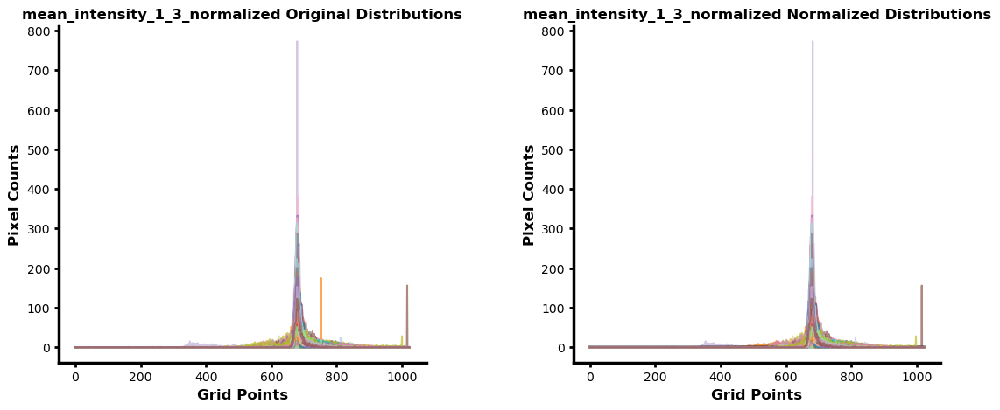


-------------------- Processing marker 'mean_intensity_2_1_normalized' --------------------
☑️ No reference provided → will select by proximity
☑️ No landmarks → automatic alignment to mean, selecting 'TMA8_38' by histogram proximity 

✨ Computed shifts: [0, 0, 4, 6, 0, 3, 3, 5, -1, 6, 0, 0, 3, 2, 1, 1, 2, -2, -3, -1, 5, 2, 0, -3, 0, 5, 0, -1, 1, 1, 2, 4, 2, 0, 1, 2, 2, 0, -2, -4, 4, -2, 1, 0, 0, 0, 0, 2, 1, 12, 1, -2, 0, 3, 0, -1, 0, -2, 2, 4, 1, 3, -1, 6, 4, -3, 0, -2, 0, -3, 0, 0, 0, 3, 0, 3, 10, 0, 1, 0, 1, 3, 3, 2, 1, 0, 3, 2, 5, -1, -2, 3, 1, 5, -4, 0, -2, 2, -1, 6, 2, 1, 1, 2, 2, 0, -1, 4, 2, 2, 0, 1, 1, 2, -1, 1, 0, 0, 4, 2, 0, 0, 0, 3, 0, -1, 6, -2, 1, 0, -4, -4, -3, -1, -1, 6, 16, 2, -3, 5, 4, 0, 0, -4, -2, -1, 7, -3, 2, 0, 3, 0, -2, -2, 6, 5, 5, -1, 1, 0, -1, -1, 6, 0, -1, 0, 15, 6, 0, 0, -3, 0, -3, 2, 2, 7, -3, 4, 3, 1, 0, 0, 5, 0, 1, 4, 0, 2, 3, 0, 2, 0, -3, -3, 2, 0, 4, 3, 0, 0, -4, -2, 2, 1, 3, 0, 4, 2, 3, 0, 1, 0, -2, 0, 1, 0, 0, 3, 0, 0, 5, 0, 2, 2, 1, 1, -1, 4, 2, 4,

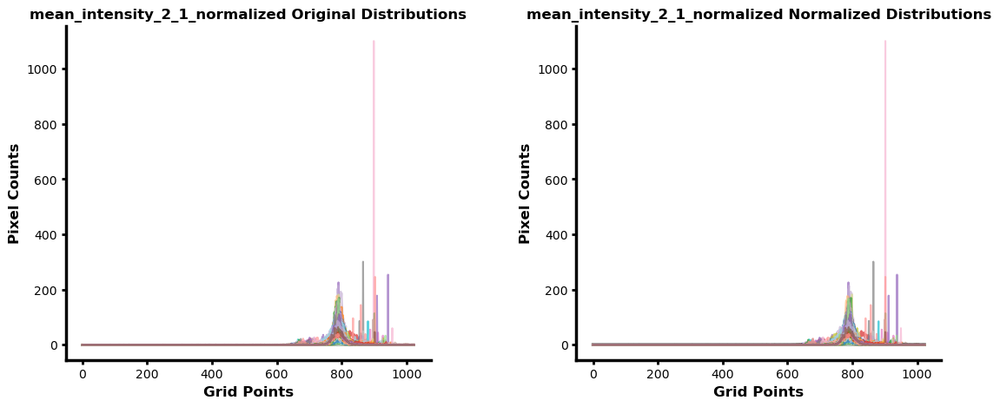


-------------------- Processing marker 'mean_intensity_2_2_normalized' --------------------
☑️ No reference provided → will select by proximity
☑️ No landmarks → automatic alignment to mean, selecting 'TMA6_65' by histogram proximity 

✨ Computed shifts: [-4, 1, 10, 6, 6, 1, 0, 1, -2, 0, 3, -1, 1, -2, -1, 3, -3, -2, -1, -1, 5, 3, 1, -2, -2, 6, 1, 3, 6, -2, 1, 1, 0, -1, 0, 5, 0, 3, -2, -1, 2, -3, -1, 0, -3, 0, 1, -2, -2, 6, -2, -1, -1, 2, -1, -2, -3, -2, 0, -1, -1, 2, 0, 1, 0, 0, 0, 0, 4, 5, 1, -1, -3, 0, -2, -2, 5, -5, 3, -1, -4, -2, 3, 1, 0, 1, 1, 0, 0, -1, 0, 1, 0, 6, 3, 3, 2, -2, -1, -2, 4, -2, 6, -5, 2, -2, 7, -2, -4, 7, 3, 3, -3, -3, -2, -2, -1, 3, 1, 2, -3, 1, 0, -1, 3, 2, 3, -2, -3, 3, 0, -6, 1, 1, -1, 6, -8, -3, -1, 1, 1, -2, -2, -2, -3, -1, 5, 5, 2, -1, -1, 1, -1, -2, 0, -1, 1, -4, -2, -3, -1, -3, 4, -1, -2, -3, 11, 7, 2, 0, 1, 5, 0, 1, 0, 6, 1, -1, 3, -1, -1, -1, 3, 2, 3, 5, 6, 1, 1, -2, 0, -4, -2, -1, 0, -2, 1, 0, -2, -2, 3, -1, 4, -4, -3, 0, 3, 2, 0, -2, -3, 0, 5, -1, -5, 

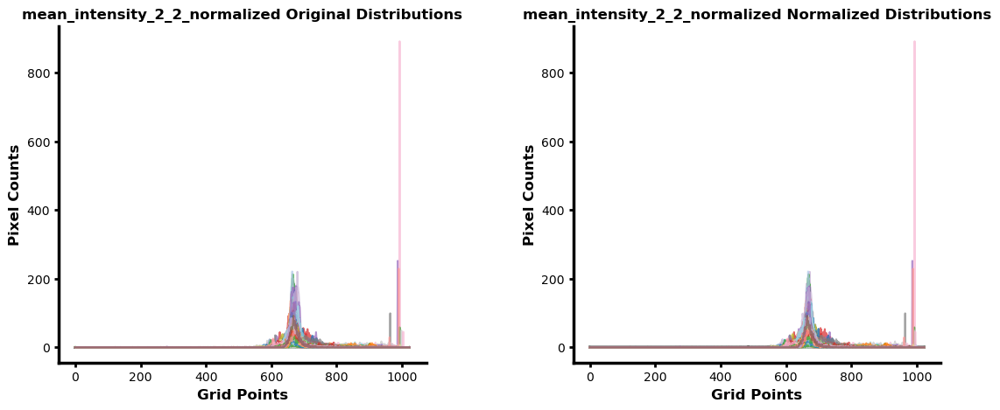


-------------------- Processing marker 'mean_intensity_2_3_normalized' --------------------
☑️ No reference provided → will select by proximity
☑️ No landmarks → automatic alignment to mean, selecting 'TMA12_47' by histogram proximity 

✨ Computed shifts: [0, 0, 1, 0, 1, -1, 1, 1, 1, 0, 0, -1, 0, 0, 0, 0, 0, 1, 0, 0, 0, 1, 0, 0, -1, 0, 0, 0, -1, -1, 0, -1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, -2, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, -1, 1, 0, 0, 0, 0, -1, 0, 0, -1, 0, 0, 0, 0, 0, -1, 0, 0, 0, -1, 0, 0, 0, 2, 1, 0, 0, -1, 0, 0, 0, 0, 0, -1, 0, -1, 0, 0, -1, 0, 0, 0, 1, 0, 1, 0, 0, 0, -1, 0, 1, 1, 1, 0, 0, 0, 0, -1, 1, 0, 1, -1, 1, 0, 0, 1, 0, 0, -1, 0, 0, 0, 0, 0, 0, -1, -1, 0, 0, 0, 0, 0, -1, 0, 0, 0, 0, 0, 0, 0, 0, -1, 0, 1, 1, 0, 0, 1, 0, 0, 0, 0, 0, 0, -1, -1, 1, 1, 0, -1, 0, -2, 1, 0, 0, 0, 1, 0, 0, 1, 0, 0, -1, 0, 0, 0, 0, 1, 0, 0, 0, -1, 0, -1, 0, 1, -1, -1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 1, -1, 1, 0, 0, -1, 0, 0, 0, 1, 0, 0, 1, 0, 0, 0, 0, -1, 1, 1, 0, 0, 0

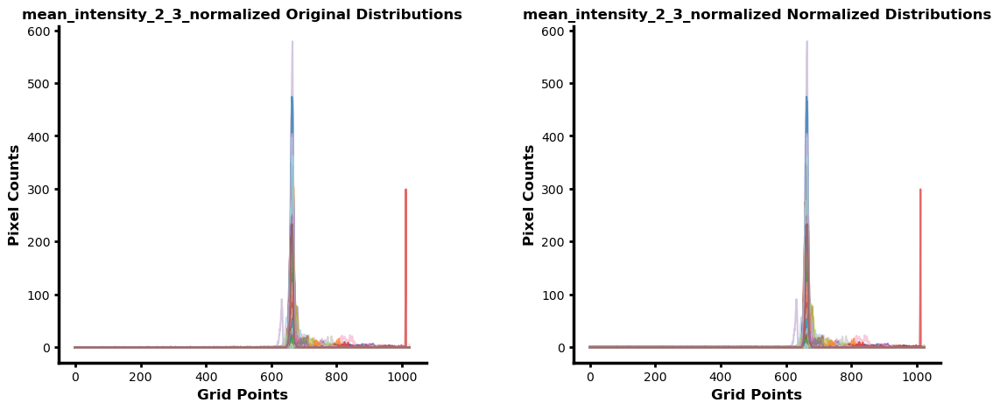


-------------------- Processing marker 'mean_intensity_3_1_normalized' --------------------
☑️ No reference provided → will select by proximity
☑️ No landmarks → automatic alignment to mean, selecting 'TMA2_81' by histogram proximity 

✨ Computed shifts: [3, 2, 1, 9, 4, 1, 14, 5, 4, 6, 1, 3, 1, 15, 4, 2, 3, -2, 0, 3, 6, 6, 1, 6, 4, 3, -2, -1, 2, -1, 0, -4, 0, 4, 0, 4, -4, 3, -4, -4, -1, 6, -3, 1, 1, -4, -1, 3, 1, 0, -1, 7, 0, 3, 2, -2, 4, -3, 5, 2, 3, -2, 1, -2, 1, -1, 3, 1, 4, 3, 6, -1, 7, -6, 0, 3, 0, 4, 0, 2, 3, -1, 2, 1, 1, 4, -5, -4, -1, -1, -1, 2, 4, 9, 2, 0, -2, 4, 2, -1, 8, 1, 2, 2, 5, -1, -1, 2, -1, 5, -4, 0, 0, 4, -2, 1, -2, 5, -2, -3, 19, 2, -1, -1, 2, 6, 4, 2, 1, -2, 14, 2, -23, -1, 1, 2, 2, 0, 4, 6, 1, -4, -3, 0, 3, 1, -2, -3, 9, -1, 2, -3, 1, 3, 3, 9, 5, -2, 3, 4, -1, -1, -10, 4, -1, -3, 5, 7, 0, 5, -1, 9, -4, 4, 4, 11, 3, 2, 0, 0, 3, 2, 7, 7, -1, 0, -1, -3, 2, 0, 4, 3, 0, -1, 1, 1, 3, -1, -1, 2, 1, 3, -6, 2, -2, 1, 3, -3, 2, 3, 1, 1, 1, 0, 0, -1, 2, 7, -4, 4, 1, 1, 8, 0

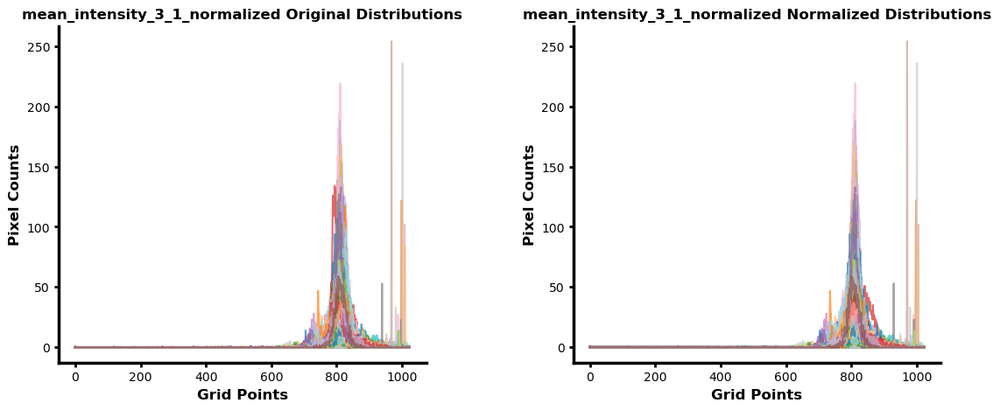


-------------------- Processing marker 'mean_intensity_3_2_normalized' --------------------
☑️ No reference provided → will select by proximity
☑️ No landmarks → automatic alignment to mean, selecting 'TMA7_21' by histogram proximity 

✨ Computed shifts: [4, 0, -1, 5, 4, 9, 21, -1, -3, -4, 4, -1, -3, 7, 2, 0, 2, 1, -2, -6, 8, 1, -6, 1, 2, 6, 1, 2, 2, 0, -1, 0, 4, 4, 0, -5, 1, 0, -5, -5, 3, 0, -4, 3, -4, 2, -5, 4, -3, -2, -3, 4, -2, 4, -4, -1, 2, -2, -1, 0, -1, -1, -1, -1, 2, 2, -1, 1, -1, -1, 0, 0, -3, 1, -2, 0, 0, 8, -2, 5, -2, 3, 1, -1, -1, 1, -1, -1, -3, -6, 2, 0, -2, 2, 4, 2, 4, -3, -2, -1, 2, -1, -1, 0, 1, -2, -2, 1, -1, 6, 0, 1, -4, 5, -3, -1, -3, 3, 1, -5, 1, 4, 1, -5, -3, 3, 0, -2, 1, 3, 14, 1, -7, -3, 1, 3, -4, -1, 1, 2, 1, -1, -3, 1, -2, 4, 5, -3, 6, -4, -3, 3, -1, 4, 1, 1, 4, -2, -1, 0, 3, 2, -3, 4, -4, -5, 4, 0, 0, 2, 3, 6, 8, 1, 0, 0, 0, 1, -4, -6, -3, 2, 2, 3, -3, 5, 0, 1, 4, 4, 4, -3, -1, -1, 0, -1, -2, 2, -2, -2, -3, -1, -1, 1, -1, 2, 5, -1, 0, -8, -1, 1, 3, 1, -2, 4, 

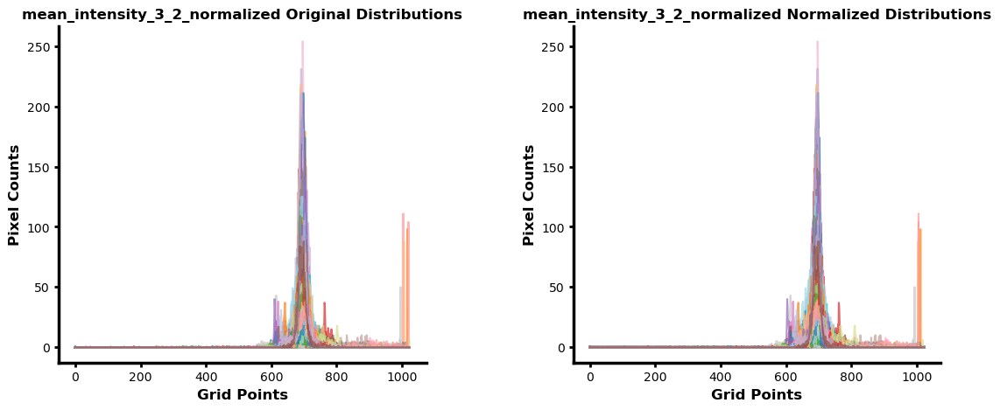


-------------------- Processing marker 'mean_intensity_3_3_normalized' --------------------
☑️ No reference provided → will select by proximity
☑️ No landmarks → automatic alignment to mean, selecting 'TMA9_58' by histogram proximity 

✨ Computed shifts: [0, 0, -3, 1, -1, -5, -4, -4, 0, -1, 0, 0, 0, -2, 0, -8, -4, 0, 6, 0, 0, 3, 0, 11, -2, 5, 1, 0, -1, 1, -1, 1, 1, 2, 0, -1, 1, 0, 2, 1, -2, -5, 0, 1, 1, 0, 3, 1, 1, -1, 0, -5, 1, 0, 1, 1, 6, 1, 0, -1, 0, 1, -1, 1, 1, -1, 1, 0, 0, -1, 0, 1, -2, 1, -1, 2, 0, 0, 0, 1, 1, 0, 1, 1, -1, 1, 2, 0, -1, 1, 1, 2, 1, -2, 1, -2, 0, -2, 4, 2, -3, -1, 1, 0, 0, 1, -2, 1, 0, -1, 0, 1, -2, 1, 1, -1, 0, -1, -1, 0, 1, 0, 2, -2, 1, 1, 1, 0, 1, -2, 0, 9, -1, -6, 3, 1, -1, 1, 0, 1, 87, 0, 1, -11, 0, 5, -1, 0, -1, -1, 1, 0, 1, -2, -1, 0, 1, 1, -1, -1, 0, 8, 0, 1, 0, 0, -3, -1, 1, 1, 21, 0, -1, 10, 1, 0, 1, -2, 1, 2, 1, -1, 0, 0, 2, 0, 0, 1, -3, 1, -1, -2, 1, 0, -1, 0, 1, 1, -2, -2, 0, 3, 1, -2, 0, 4, -1, 1, 1, 1, -1, 1, 1, 1, 2, -2, 0, 1, 0, 1, 1, 0, 0, 0, 0,

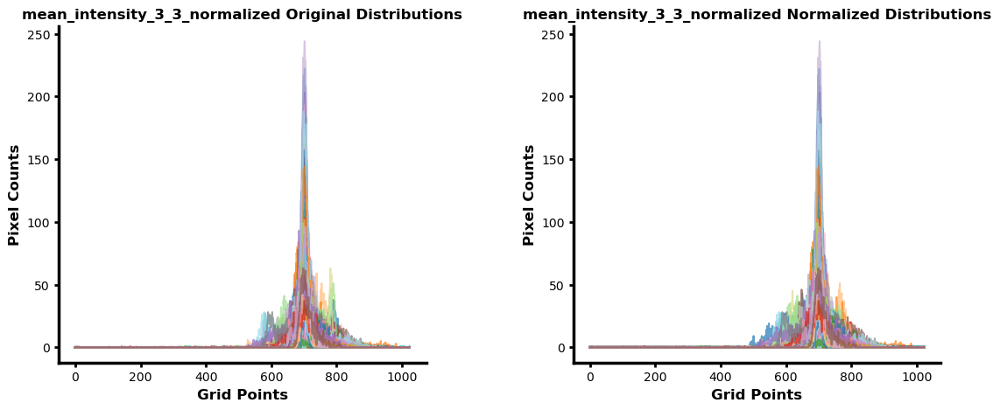


-------------------- Processing marker 'mean_intensity_4_1_normalized' --------------------
☑️ No reference provided → will select by proximity
☑️ No landmarks → automatic alignment to mean, selecting 'TMA9_15' by histogram proximity 

✨ Computed shifts: [0, -4, -5, -6, -5, -6, -1, 1, -1, -5, -3, -1, -5, 2, -4, -2, -5, 2, -4, 1, -3, -1, -4, -5, -1, 2, 2, -2, 0, -3, -5, -11, -5, -3, -2, -2, -3, -4, -6, 0, -4, -2, 0, -2, -9, -7, -8, -4, 2, -6, -1, -5, -3, -8, -3, -5, -1, -7, 1, -4, 0, -3, 16, 0, -5, 0, 1, -3, -3, -1, 0, 2, 0, -4, -3, 2, -1, -8, -6, 0, 3, -5, 0, 0, -5, -4, -11, -4, -2, -5, 0, -6, -5, 6, 2, -5, -7, -4, -1, 0, -6, 5, 2, -5, 2, -3, -1, -2, -4, 0, 2, 2, -1, -5, -6, -3, -2, 0, 2, 0, 3, -1, 0, 1, -1, -3, 0, -4, 0, 0, -6, -1, -4, -3, -2, -5, -5, -7, -6, -2, -6, 0, -5, 0, 4, -1, -5, -3, -7, -3, 1, 1, -9, -2, 0, 0, 2, -7, -3, -1, 0, -3, -15, -6, -3, -2, 0, 3, 2, 0, -3, 7, 0, -3, -5, -1, 3, -5, 1, -7, -7, 3, 1, 0, 0, -1, 2, 0, -1, -1, 0, 3, 1, 4, -7, -2, -8, -1, 0, 0, -5, -4, -6, 

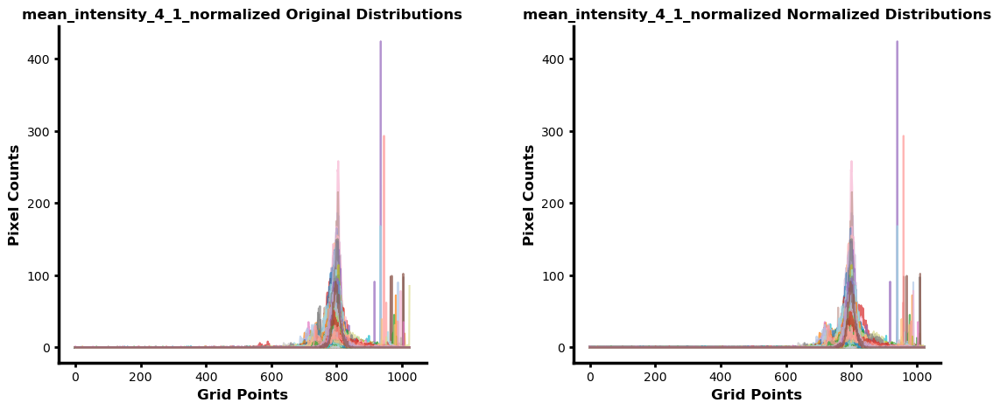


-------------------- Processing marker 'mean_intensity_4_2_normalized' --------------------
☑️ No reference provided → will select by proximity
☑️ No landmarks → automatic alignment to mean, selecting 'TMA7_91' by histogram proximity 

✨ Computed shifts: [-3, 4, 0, 1, 0, -1, 0, -4, 0, 1, -5, 1, 1, 0, 3, 1, 6, 0, 0, 2, 0, 2, 2, 4, 0, 1, 2, -1, 9, 2, 2, 0, 8, 2, 2, 0, 2, 0, 0, -1, 5, 0, -2, 1, 1, -4, 3, 2, 1, 2, 1, 3, 1, 0, 1, 1, 2, -1, 5, 1, -1, 2, -4, 5, 1, 1, 1, 4, 0, 5, 2, 0, 2, 0, -3, 1, 2, 3, 1, 3, 0, 1, 1, 1, 4, 3, 1, 1, 1, 1, 0, 3, 3, -1, 0, 2, 1, 0, 0, 0, 0, 2, 0, -1, 3, 4, 1, -4, 1, 0, 1, -2, 0, 2, 0, -1, 0, -3, 0, 2, 1, 3, 0, 2, 2, 0, 5, -2, 2, 0, -3, 0, 0, 0, 2, 4, 4, 0, 14, -4, 16, 1, 1, 1, 0, 1, 4, 0, 6, 1, 2, -2, 5, 5, -1, 3, 1, 1, 0, -2, 1, -3, 7, 4, 1, -1, 1, 0, -1, 0, 0, 2, 1, 0, 0, 3, 0, -2, -2, -4, 3, 2, 1, -2, -1, 1, -1, 1, 2, 0, 0, 1, 0, 2, 1, 1, 3, 5, 1, 3, 2, 0, 0, 0, 1, -1, 0, 27, 2, 0, 42, 1, 1, 1, 0, 0, 0, 2, 0, 1, 3, 3, 3, 5, 0, -1, 2, 1, 1, 1, 1, 2, 5, -1, 0

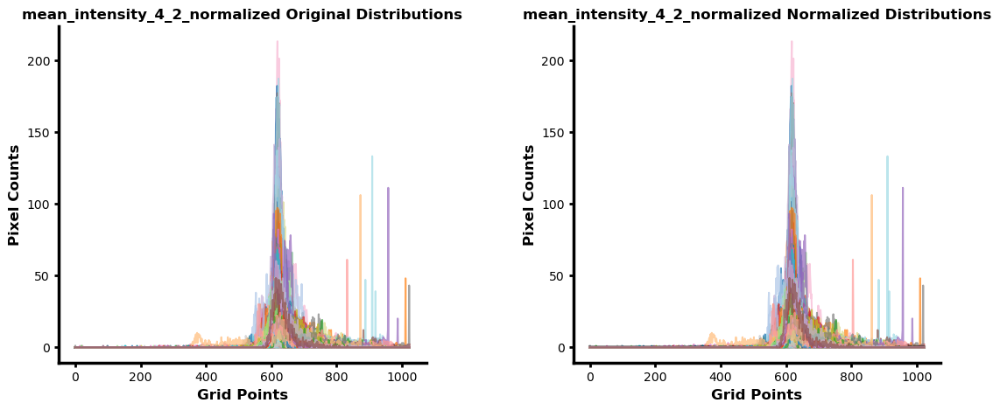


-------------------- Processing marker 'mean_intensity_4_3_normalized' --------------------
☑️ No reference provided → will select by proximity
☑️ No landmarks → automatic alignment to mean, selecting 'TMA6_54' by histogram proximity 

✨ Computed shifts: [0, 0, 0, 0, -1, -1, 0, 0, 1, 0, 1, -1, 0, 0, -1, -1, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, -1, -1, 0, -1, 0, 0, 0, 0, 0, 1, -1, -1, -1, 2, 0, 0, 0, -1, 0, 0, 0, 0, 0, 0, 0, 1, 0, -1, 0, 0, 0, 0, 0, 0, -1, 0, 0, -1, 0, 0, 0, -1, 1, 0, 0, 1, 0, 0, -1, 1, 0, 0, 0, 0, 0, 0, -1, 0, 0, 0, -1, -1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, -1, -1, 0, 0, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 1, 1, 0, -1, 0, -1, 0, 1, 0, 0, -1, -1, 0, 0, -1, 0, 1, 0, 0, 0, 0, 1, 0, 0, -1, -1, 0, 0, 0, 0, 0, 1, -1, 1, 0, 0, 0, 0, 0, 0, 0, -1, -1, 0, 0, 1, 0, -1, 0, 0, -1, -1, 0, 0, 0, 0, 0, -2, -1, 1, 0, -1, 0, 0, 0, 0, 0, -1, 0, -1, -1, 0, 0, 0, 0, 0, 0, 0, -1, 0, -1, 0, 0, 0, 2, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, -1, 1, 0, -1, 2, 1, 0, 0, 0, 0, -1, 0, 1, 1, 0, 0, 0

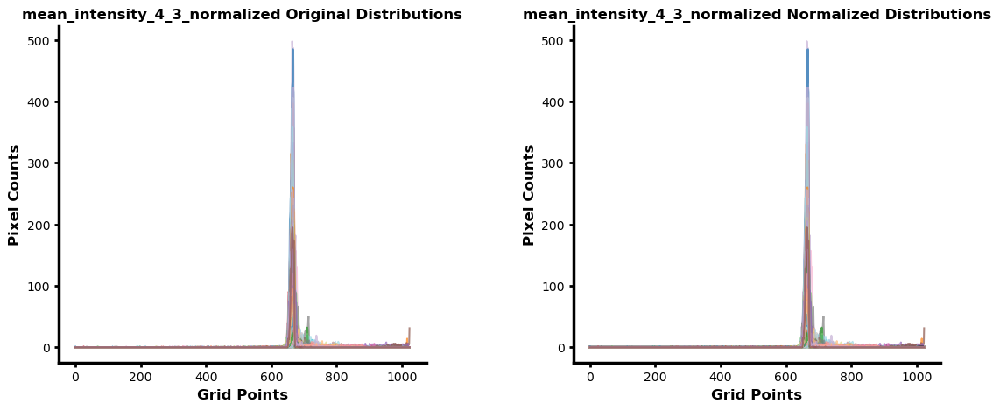


-------------------- Processing marker 'mean_intensity_5_1_normalized' --------------------
☑️ No reference provided → will select by proximity
☑️ No landmarks → automatic alignment to mean, selecting 'TMA13_95' by histogram proximity 

✨ Computed shifts: [8, 2, -4, 26, 4, 11, 13, 10, 5, 14, 11, 7, 4, 20, 3, 37, 10, -9, 5, 0, 9, 20, 3, 14, 18, 9, 15, -1, 12, 2, 11, -2, 7, 5, 2, 6, 0, 4, 2, -3, 4, 5, -3, 0, 3, 1, 7, -2, 2, 3, 11, 18, 10, 10, -8, 2, -7, -6, 1, 7, 6, 9, -17, -3, -1, -15, 5, 21, 10, 7, 6, -9, 3, 8, 2, 0, -7, 11, 6, 2, -6, 6, -2, 1, -7, 2, -19, 2, 0, -4, 1, 12, 10, -1, 6, 5, 0, -9, 9, -4, -2, 7, -2, 12, 2, -7, 28, 0, 5, 2, 3, 10, 2, 1, -6, 2, 8, 2, 5, 0, 7, 5, 9, 1, -3, 12, -8, 7, 2, 2, -4, -2, 9, -4, 6, 0, 1, 0, -2, 11, 55, -2, 2, -22, 6, 1, -1, 2, 15, 3, 1, 14, 8, 24, -7, 17, 3, -1, -22, -1, 1, 7, 3, 3, -4, -3, 2, 16, 7, 3, -8, 36, -4, -4, 16, 12, 1, 26, 10, 7, 20, 3, 1, 16, 4, 15, 14, 1, 8, -2, 12, 24, 0, -2, 3, 3, -2, 10, 6, 3, -1, 4, 3, 16, -3, 1, 10, -6, -9, -5, 6, -

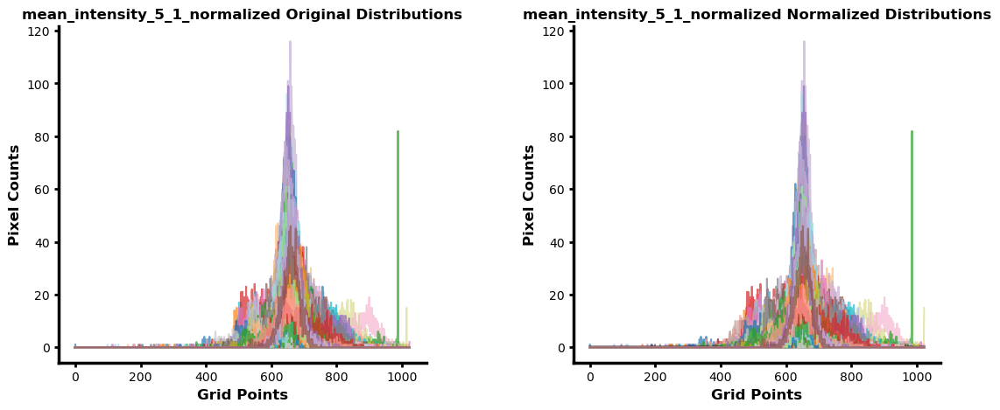


-------------------- Processing marker 'mean_intensity_5_2_normalized' --------------------
☑️ No reference provided → will select by proximity
☑️ No landmarks → automatic alignment to mean, selecting 'TMA5_14' by histogram proximity 

✨ Computed shifts: [1, -1, 0, -6, -3, -3, 0, 1, 1, 0, -8, -3, 4, 3, 1, 4, 10, -1, 1, 2, -2, -7, 5, -14, 0, -2, -2, 1, 1, -3, -6, 0, 2, -3, 2, -6, 2, 3, 4, 0, 1, -1, 3, -1, -1, -12, -1, 0, -3, 1, 1, -3, 2, -5, -1, -2, -4, -1, -2, -1, -3, 5, -35, 5, 0, 3, -3, 0, -2, 2, -3, 3, -4, 1, -1, 1, -1, -6, -4, -1, -1, -6, -3, 1, -2, -3, 6, 3, -3, 3, 1, -7, -8, -3, 0, -7, -7, 6, -6, 5, -1, -2, 4, 3, -6, -3, 0, 0, -4, 5, 0, 3, -1, -7, -7, -1, 0, 6, -1, 1, -2, 2, 1, 3, -3, 0, -1, 3, 2, 5, -2, -5, 2, 1, 1, 0, -4, 5, -15, -4, 1, -2, -3, -2, 3, 0, 0, -1, -1, 6, -12, 3, -3, 2, 2, -7, -6, -3, -23, -3, 4, 3, 0, 3, 0, 2, -35, -1, -13, 0, 1, 1, -8, -1, -7, -1, 0, 3, -4, -2, -6, -1, 0, 3, 4, -2, -1, -1, 3, -5, 0, 2, 0, 0, 1, 6, -4, -2, 2, -4, 2, 0, -4, 2, 0, 1, -4, -2, -6, 3,

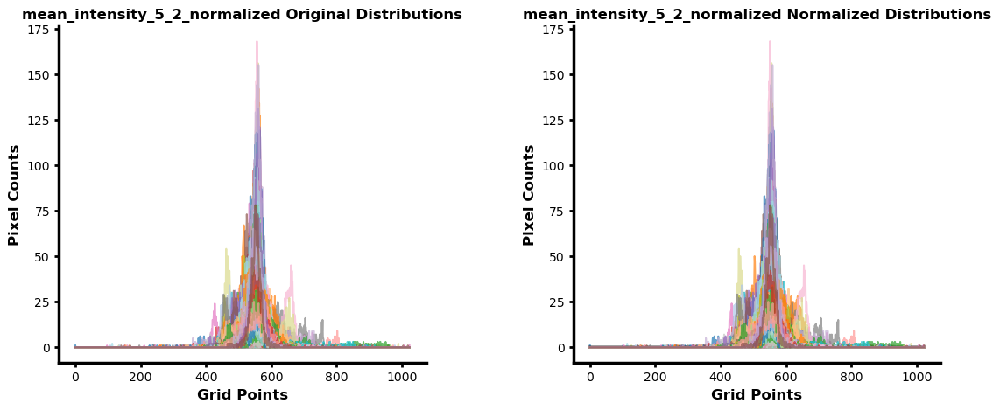


-------------------- Processing marker 'mean_intensity_5_3_normalized' --------------------
☑️ No reference provided → will select by proximity
☑️ No landmarks → automatic alignment to mean, selecting 'TMA6_9' by histogram proximity 

✨ Computed shifts: [0, 1, 0, -1, -1, -3, -1, 0, 0, -3, -2, 0, 0, -1, -1, -1, 0, 0, -1, -1, -1, 1, 0, 0, -2, -1, 0, -1, 0, -2, -1, -2, 0, -1, -1, -2, 0, 1, 0, -1, 0, 0, 0, 0, -2, -1, -1, 0, 0, -1, -1, -2, 0, -2, -1, 0, 0, -1, 0, -2, -1, -3, 0, 0, -1, -2, 0, -1, -1, -3, 0, -1, 0, 0, 0, 1, 1, 0, 0, -1, -1, 1, -1, 0, 0, -1, 0, 0, 0, 0, -1, -1, 0, 1, -1, -1, 1, 0, -2, 0, -1, -1, 0, 0, -1, -1, -1, 0, 0, -1, 0, 0, 0, 0, -2, 0, 0, 0, -1, 0, 0, 0, -2, -1, 0, 0, 0, 0, 0, 2, -2, 1, 0, 0, 1, -1, -3, 0, 0, -1, -1, 0, 0, 0, -1, 0, 0, -1, 0, 0, -1, 0, 0, 0, -1, -1, -3, -1, 0, 0, 0, 0, 0, -1, -1, 0, -8, -1, -3, 0, 0, -1, 0, -2, 0, 0, -2, -2, 0, -1, -1, -1, 0, -1, 0, 0, 0, 0, -2, -2, 0, 0, -2, -1, -1, -1, -1, 0, -1, -1, 0, -1, 0, -3, -1, 0, 0, 1, 0, -1, -3, 0, -2, 0, 0, 

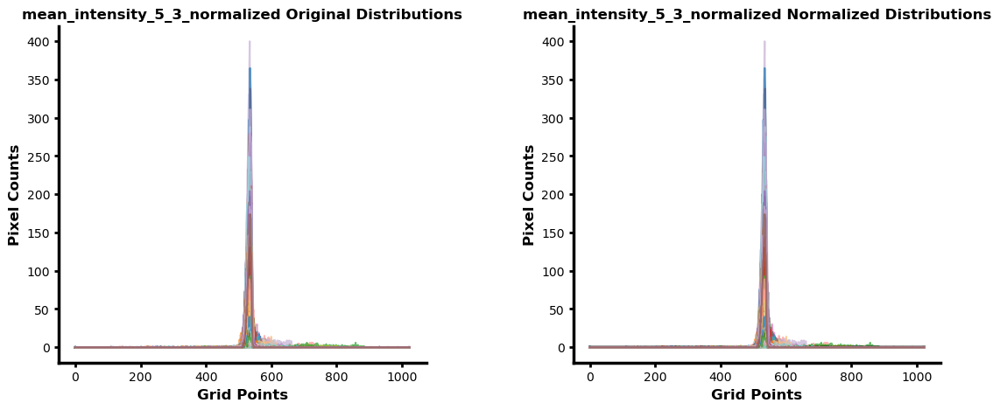

In [9]:
shifts_map, chosen_references, implied_landmarks_map = automatic_registration(
    histogram_data      = histograms,
    all_markers         = adata.var['marker_name'].tolist(),
    selected_markers    = adata.var['marker_name'].tolist(),
    sample_ids          = adata.obs['sample_id'].unique().tolist(),
    reference_samples   = None,
    landmark_map        = None,
    num_bins            = 1024,
    dpi                 = 100,
    x_limits            = None
)

In [10]:
landmark_refinement(
    histogram_data        = histograms,
    gmm_models            = gmm_models,
    markers               = None,
    sample_ids            = None,
    data_source           = adata,
    num_bins              = 1024,
    dpi                   = 100,
    x_limits              = None,
    group_size            = 4,
    implied_landmarks_map = implied_landmarks_map,
    verbose               = True,          
    output_directory  = "landmark_picking"
)

HTML files:   0%|                                       | 0/268 [00:00<?, ?it/s]

Processing samples TMA9_15 to TMA14_75
  Marker: mean_intensity
  Marker: mean_intensity_0_1
  Marker: mean_intensity_0_2
  Marker: mean_intensity_0_3
  Marker: mean_intensity_1_1
  Marker: mean_intensity_1_2
  Marker: mean_intensity_1_3
  Marker: mean_intensity_2_1
  Marker: mean_intensity_2_2
  Marker: mean_intensity_2_3
  Marker: mean_intensity_3_1
  Marker: mean_intensity_3_2
  Marker: mean_intensity_3_3
  Marker: mean_intensity_4_1
  Marker: mean_intensity_4_2
  Marker: mean_intensity_4_3
  Marker: mean_intensity_5_1
  Marker: mean_intensity_5_2
  Marker: mean_intensity_5_3
  Marker: mean_intensity_normalized
  Marker: mean_intensity_0_1_normalized
  Marker: mean_intensity_0_2_normalized
  Marker: mean_intensity_0_3_normalized
  Marker: mean_intensity_1_1_normalized
  Marker: mean_intensity_1_2_normalized
  Marker: mean_intensity_1_3_normalized
  Marker: mean_intensity_2_1_normalized
  Marker: mean_intensity_2_2_normalized
  Marker: mean_intensity_2_3_normalized
  Marker: mean_int

HTML files:   0%|                               | 1/268 [00:04<20:06,  4.52s/it]

  Marker: mean_intensity_5_3_normalized
Processing samples TMA3_68 to TMA7_14
  Marker: mean_intensity
  Marker: mean_intensity_0_1
  Marker: mean_intensity_0_2
  Marker: mean_intensity_0_3
  Marker: mean_intensity_1_1
  Marker: mean_intensity_1_2
  Marker: mean_intensity_1_3
  Marker: mean_intensity_2_1
  Marker: mean_intensity_2_2
  Marker: mean_intensity_2_3
  Marker: mean_intensity_3_1
  Marker: mean_intensity_3_2
  Marker: mean_intensity_3_3
  Marker: mean_intensity_4_1
  Marker: mean_intensity_4_2
  Marker: mean_intensity_4_3
  Marker: mean_intensity_5_1
  Marker: mean_intensity_5_2
  Marker: mean_intensity_5_3
  Marker: mean_intensity_normalized
  Marker: mean_intensity_0_1_normalized
  Marker: mean_intensity_0_2_normalized
  Marker: mean_intensity_0_3_normalized
  Marker: mean_intensity_1_1_normalized
  Marker: mean_intensity_1_2_normalized
  Marker: mean_intensity_1_3_normalized
  Marker: mean_intensity_2_1_normalized
  Marker: mean_intensity_2_2_normalized
  Marker: mean_inte

HTML files:   1%|▏                              | 2/268 [00:06<14:39,  3.30s/it]

...

HTML files: 100%|████████████████████████████▉| 267/268 [11:13<00:02,  2.52s/it]

  Marker: mean_intensity_5_2_normalized
  Marker: mean_intensity_5_3_normalized
Processing samples TMA3_21 to TMA10_35
  Marker: mean_intensity
  Marker: mean_intensity_0_1
  Marker: mean_intensity_0_2
  Marker: mean_intensity_0_3
  Marker: mean_intensity_1_1
  Marker: mean_intensity_1_2
  Marker: mean_intensity_1_3
  Marker: mean_intensity_2_1
  Marker: mean_intensity_2_2
  Marker: mean_intensity_2_3
  Marker: mean_intensity_3_1
  Marker: mean_intensity_3_2
  Marker: mean_intensity_3_3
  Marker: mean_intensity_4_1
  Marker: mean_intensity_4_2
  Marker: mean_intensity_4_3
  Marker: mean_intensity_5_1
  Marker: mean_intensity_5_2
  Marker: mean_intensity_5_3
  Marker: mean_intensity_normalized
  Marker: mean_intensity_0_1_normalized
  Marker: mean_intensity_0_2_normalized
  Marker: mean_intensity_0_3_normalized
  Marker: mean_intensity_1_1_normalized
  Marker: mean_intensity_1_2_normalized
  Marker: mean_intensity_1_3_normalized
  Marker: mean_intensity_2_1_normalized
  Marker: mean_int

HTML files: 100%|█████████████████████████████| 268/268 [11:15<00:00,  2.52s/it]

  Marker: mean_intensity_5_3_normalized


✅  All HTML files and landmark_annotations.csv saved to 'landmark_picking' folder


In [11]:
landmark_df = pd.read_csv("./UniFORM/landmark_picking/landmark_annotations_filled.csv", index_col=0)
sample_names = [col.replace("_landmark", "") for col in landmark_df.columns]
landmark = {}

for marker in landmark_df.index:
    row = landmark_df.loc[marker]
    if row.isna().all() or all(v == '' for v in row):
        landmark[marker] = None
    else:
        row_values = []
        for col in landmark_df.columns:
            value = landmark_df.loc[marker, col]
            if pd.isna(value) or value == '':
                row_values.append(None)
            else:
                row_values.append(int(value))  # Ensure integers
        landmark[marker] = row_values


-------------------- Processing marker 'mean_intensity' --------------------
☑️ No reference provided → will select by proximity
☑️ No landmarks → automatic alignment to mean, selecting 'TMA9_13' by histogram proximity 

✨ Computed shifts: [-38, 143, -85, -29, -175, -39, -99, -169, -85, -124, -8, -42, -169, 54, 49, -23, -133, -32, -88, 19, 183, 41, -101, 16, -15, 233, 114, 110, -33, -65, 283, -53, -7, 9, -39, -59, -118, 40, -5, -57, 146, 93, -47, -1, 19, 83, 90, 67, -50, -2, 31, -121, -95, 31, 205, -25, -170, -3, -81, -5, -10, 174, 61, -122, 0, 166, -79, -98, 6, -80, 102, 150, -90, -55, -131, -213, -230, -11, -53, 76, -65, 32, -31, 73, 47, -64, 12, -119, -194, -75, -21, 65, -49, -99, 160, 207, 2, 80, -23, 76, 74, -149, -143, -122, 11, -196, 147, -3, 0, 177, -138, -239, -174, -19, -75, -32, -119, -174, -59, -14, -106, -53, -77, 46, -124, -47, -7, -96, -31, -62, -194, 85, -13, 92, 17, -12, -87, -1, -34, 35, 123, 78, -141, 85, -105, -171, 42, -53, -14, -123, -142, 13, -107, 39, 50, 109, 

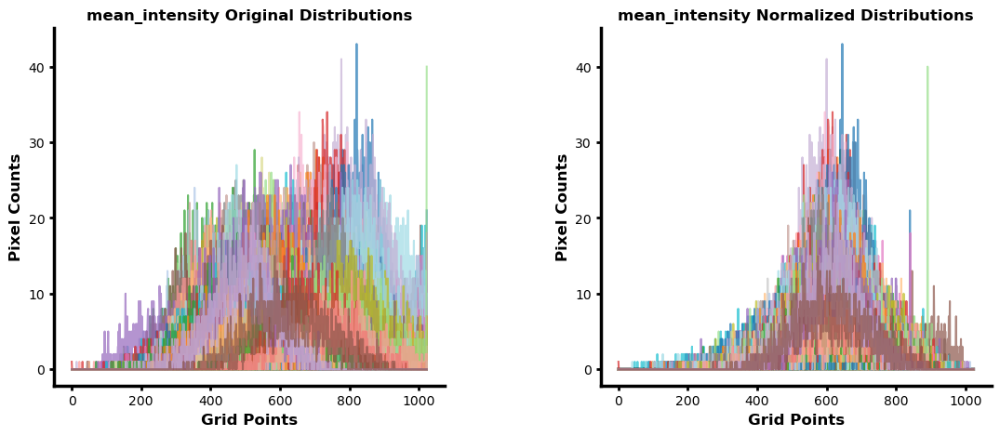


-------------------- Processing marker 'mean_intensity_0_1' --------------------
☑️ No reference provided → will select by proximity
☑️ No landmarks → automatic alignment to mean, selecting 'TMA11_78' by histogram proximity 

✨ Computed shifts: [-65, 146, -161, 110, 74, -69, 97, 117, 103, -29, 21, 115, 171, 39, 237, 100, 55, -120, 122, 77, -32, 31, 83, -191, 223, 207, 191, 160, 214, -151, 93, 223, -7, 1, -31, 81, -63, -70, 168, -9, 203, 131, 37, 122, 36, -145, -162, -9, -157, -76, 82, 348, -37, 139, -23, 111, -232, -31, -29, -53, -14, 280, 25, -63, 26, 128, 7, 51, 260, 309, 146, 46, 95, -26, 105, 21, 102, 1, 4, 161, -172, -192, 135, 241, 16, -145, -61, -52, -96, -141, 36, -48, 72, 237, 223, 112, -28, -39, 84, 138, 260, 164, 81, -180, -23, -178, 31, -140, -53, 385, 95, 61, 58, -124, 122, -129, 46, 76, 193, 64, -15, -48, 119, 111, 41, 147, -10, 113, 62, 53, 12, 85, -12, 117, -83, -12, 385, 114, 85, 37, 49, 55, -120, -37, -46, 6, 38, -37, 385, -250, -233, 74, -61, 106, -114, 280, 221, 65

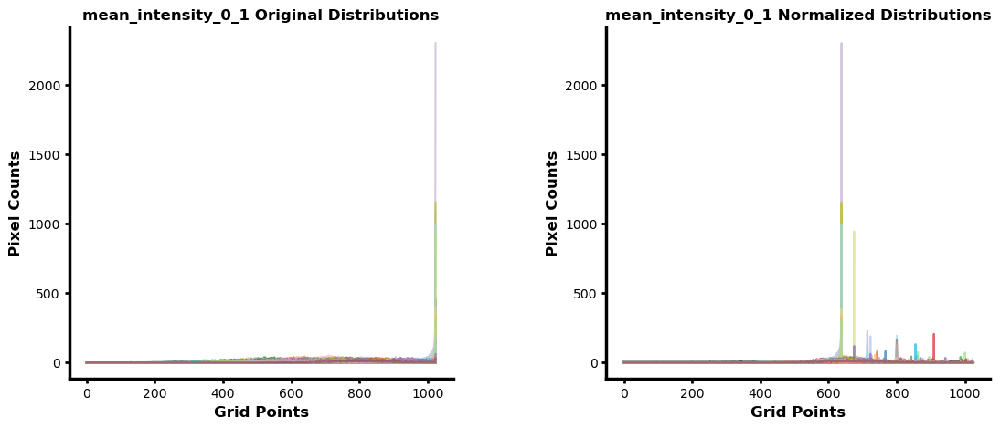


-------------------- Processing marker 'mean_intensity_0_2' --------------------
☑️ No reference provided → will select by proximity
☑️ No landmarks → automatic alignment to mean, selecting 'TMA11_87' by histogram proximity 

✨ Computed shifts: [121, 26, -86, 57, -8, -49, 18, 46, -2, -37, 3, 4, 48, -18, 61, -1, -7, 84, 19, 8, 95, -18, 37, 21, 89, 19, 30, 27, 46, 6, -10, 134, -27, 130, -37, 11, 42, 23, -29, -57, 36, -5, 67, 8, 91, -53, 63, -41, -53, -44, -6, 102, -15, -6, -45, 75, -104, 42, 19, 117, -21, 62, 3, -52, -14, 1, -24, -7, 95, 118, 41, 0, 7, 44, 35, -12, 37, -36, 73, 110, 54, -109, 51, 65, -32, 6, 12, 65, 87, 78, -34, 31, -21, 105, 51, 5, 82, -47, -20, 35, 83, 32, 46, 5, -36, 73, -23, 68, 122, 151, 16, 12, -12, -58, 24, 66, -17, 29, 70, 75, -42, -56, 2, 8, -23, 38, -42, 14, -4, 0, 78, 4, 96, -7, 46, 33, 97, 125, -22, -26, -20, -14, 110, -60, -40, -17, 15, -33, 276, 51, 0, 18, -56, 93, -75, 91, 77, 72, 100, -88, 4, -16, 32, 87, 131, 86, -55, 79, 84, 87, 2, -5, -73, 52, 56, 86,

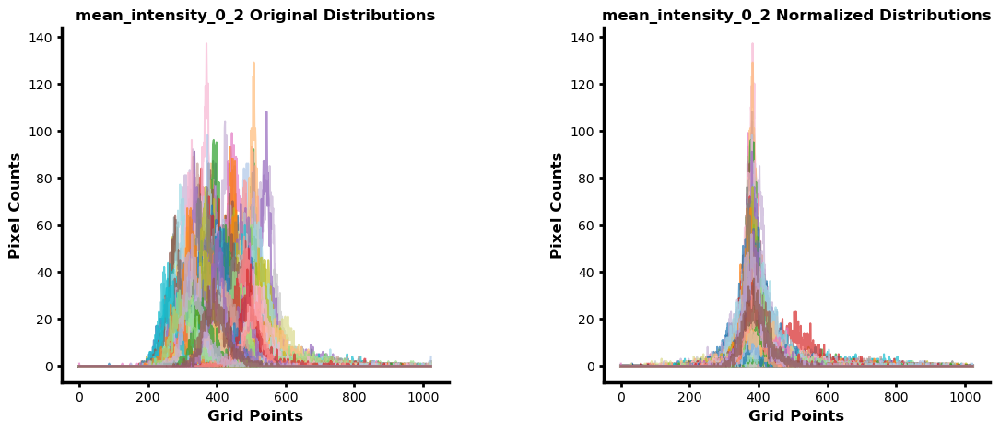


-------------------- Processing marker 'mean_intensity_0_3' --------------------
☑️ No reference provided → will select by proximity
☑️ No landmarks → automatic alignment to mean, selecting 'TMA0_24' by histogram proximity 

✨ Computed shifts: [23, -6, 41, 123, 356, 4, 218, 251, 307, 47, 503, 333, 87, 322, 434, 229, 237, 7, 503, 156, -81, 298, 430, -44, 317, -20, 451, 319, 184, 29, 3, 26, 170, -68, 29, 23, -3, 52, 62, 503, 384, 405, -76, 407, 44, 503, 13, -10, 335, 407, 24, 168, 394, 34, -4, 115, 106, 23, 148, -68, 1, 6, 422, 13, 213, 394, 275, 250, 224, 56, 503, 481, 344, -50, 276, 279, 237, 389, -13, 153, -3, -13, 307, 95, 64, -11, 51, 19, -71, 200, 155, 11, -15, 193, 407, 0, 244, 253, -8, 338, 141, 58, 333, -6, 114, -63, 192, 63, -71, 162, 64, 409, 388, 434, 125, 4, 236, 255, 117, -45, 425, 188, 260, 167, 265, 73, -5, 123, 66, 204, -17, 373, 96, 41, -42, 103, 351, 14, -24, 13, 514, 5, -12, 250, 241, 428, 407, 140, 224, 9, -22, 232, 8, 185, 144, 407, 117, 111, -10, 64, -43, 503, 93,

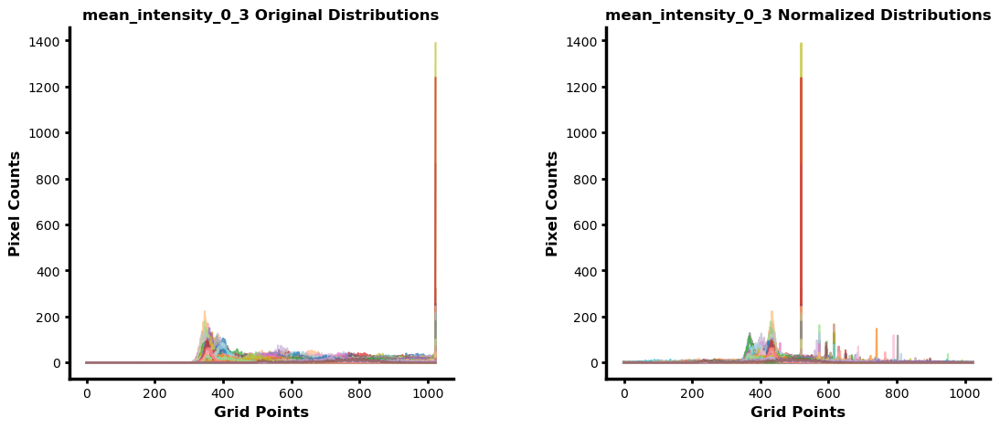


-------------------- Processing marker 'mean_intensity_1_1' --------------------
☑️ No reference provided → will select by proximity
☑️ No landmarks → automatic alignment to mean, selecting 'TMA14_89' by histogram proximity 

✨ Computed shifts: [5, 27, -36, 0, 8, -14, 9, 80, 17, -16, -57, 23, 38, -12, 52, 44, -3, -1, 18, 26, -16, -26, 68, -42, 67, 30, 54, 35, 45, -45, 24, 54, 13, -11, -45, 20, -26, -29, 21, -10, 22, 32, 7, 13, -16, -90, -28, 3, -60, -58, 61, 43, -38, 28, -5, 19, -41, -3, -16, -20, 15, 60, -31, -9, 40, 14, 4, 7, 62, 92, 25, -17, 14, -11, 49, 4, 59, -41, -7, 36, -38, -48, 78, 56, -5, -51, -25, -20, -14, -50, -4, -22, 32, 71, 50, 32, -18, -6, -17, 35, 89, 26, 58, -30, 5, -38, 10, -42, -5, 85, 8, 26, 14, -71, 35, -32, 10, 54, 62, -22, 0, 0, 14, 28, 4, 25, 4, 22, 12, 71, 4, 25, -7, 32, -24, -22, 61, 24, 28, 7, -17, 26, -23, -6, -11, -42, -44, -14, 92, -48, -46, 44, -18, 28, -23, 47, 72, 16, 9, -7, -42, 2, -18, 53, -22, -22, -11, 85, 62, -8, -29, 41, -92, -27, -20, 1, 18, 2

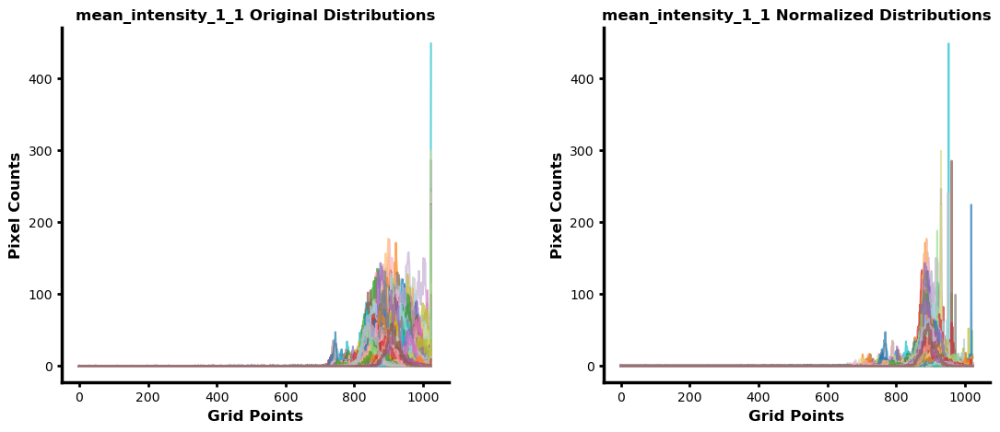


-------------------- Processing marker 'mean_intensity_1_2' --------------------
☑️ No reference provided → will select by proximity
☑️ No landmarks → automatic alignment to mean, selecting 'TMA11_27' by histogram proximity 

✨ Computed shifts: [35, 12, -33, 13, -3, -20, 2, 60, -8, -6, -19, -2, 16, -17, 20, -1, -4, 27, 1, -6, 22, -21, 47, -6, 29, 12, 4, 13, 13, -9, 1, 45, -11, 32, -18, 7, 3, 1, 0, -21, 7, -7, 13, 1, 16, -38, 13, -16, -33, -29, -1, 17, -22, 3, -17, 21, -35, 1, 0, 24, -2, 27, -18, -25, 23, -1, -21, -3, 36, 52, 19, -19, -8, 5, 27, -5, 49, -32, 19, 32, 5, -36, 58, 13, -5, -9, -2, 10, 18, 8, -20, -1, 2, 78, 27, 6, 23, -15, -7, 23, 75, 3, 50, 2, -16, 8, -10, 13, 27, 55, -1, -2, -5, -37, 0, 18, -6, 45, 21, 13, -19, -18, -1, -1, -14, 11, -9, -1, -13, 60, 22, 3, 24, -1, 11, 11, 35, 45, -8, -9, -21, -2, 23, -21, -20, -24, -20, -13, 121, 7, -15, 48, -23, 27, -22, 24, 63, 22, 26, -14, -11, -10, -2, 28, 31, 16, -5, 81, 32, 23, -18, 21, -39, 11, 8, 28, 11, 22, 52, 8, -5, -36, 8, -3

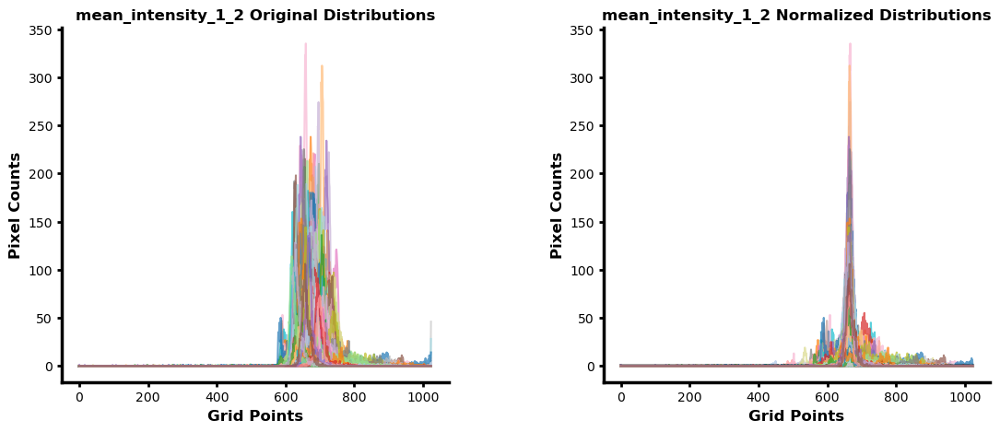


-------------------- Processing marker 'mean_intensity_1_3' --------------------
☑️ No reference provided → will select by proximity
☑️ No landmarks → automatic alignment to mean, selecting 'TMA0_31' by histogram proximity 

✨ Computed shifts: [8, 3, -2, -1, -9, -3, 4, 80, -6, 1, -2, -1, -7, -3, 7, -1, -8, 7, 1, 5, 1, -1, 174, 2, -1, 3, -3, 20, 122, -2, -3, 11, -2, 3, -5, 13, 9, 0, 5, -8, -3, -6, 2, 12, -2, 0, 0, -1, -10, -9, -4, -1, -3, 2, -7, 0, -6, -2, -4, 2, 12, 13, -6, 2, 102, 5, 0, -3, 6, 15, 2, -2, -9, 0, 10, -5, 99, -6, 6, -1, 6, -8, 154, -3, 6, -1, -4, 6, -5, -2, -8, -1, 7, 78, 3, 0, 1, -5, -6, 4, 44, -2, 142, 0, -1, 4, -2, 3, 4, 11, -1, -2, -8, -6, -5, 3, -1, 150, -3, -1, 0, 0, -7, 5, -6, 5, 2, -3, -4, 90, -3, -5, 5, -4, 1, -4, 2, 16, 4, 7, -1, 11, 7, -8, -9, -7, -6, -3, 32, 8, -1, 70, -7, 2, -3, 9, 29, 7, 5, 3, -2, -8, -1, 14, -3, 2, -12, 72, -2, -5, -2, 1, -8, 3, 4, 1, 70, 2, 46, 23, -6, -3, -1, -5, 5, -4, 14, -5, -8, 343, -5, -7, 49, -6, -7, -11, -7, -1, -4, -10, -4, 1, 0

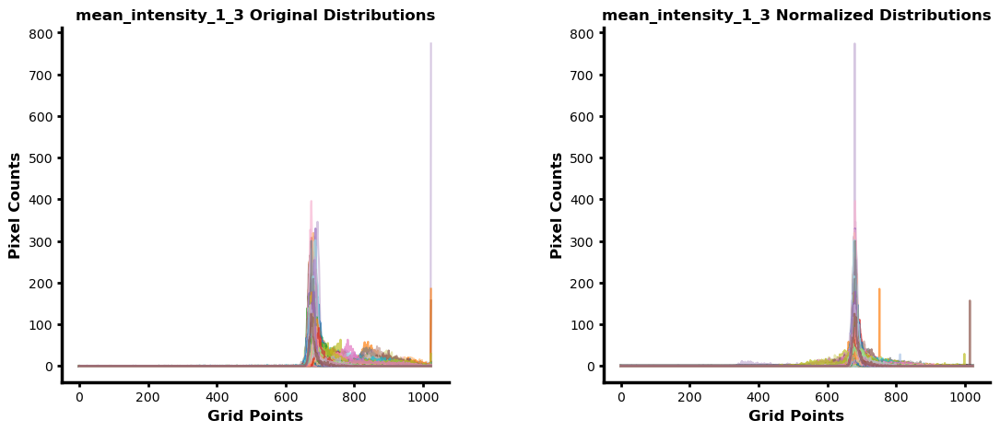


-------------------- Processing marker 'mean_intensity_2_1' --------------------
☑️ No reference provided → will select by proximity
☑️ No landmarks → automatic alignment to mean, selecting 'TMA6_37' by histogram proximity 

✨ Computed shifts: [-13, 30, 25, 12, 18, -19, 32, 33, 10, -8, -41, 11, 39, -1, 55, 31, 10, -33, 24, 22, -16, -24, 28, -34, 58, 42, 46, 44, 35, -16, 24, 37, 10, -22, -8, 13, 12, -2, 0, -12, 34, 32, 5, 13, -14, -83, -30, -8, -61, 10, 9, 36, -41, 18, 6, 25, -39, 7, -15, -42, 9, 61, -30, -16, 12, 19, 5, 5, 66, 85, 18, -19, 22, -4, 25, 0, 20, -40, -4, 27, -43, -47, 35, 62, -3, -37, -7, -17, -33, -45, 4, -5, 22, 56, 49, 25, -8, -11, 7, 28, 65, 36, 10, -30, 6, -49, 1, -42, -24, 97, 34, 26, 13, -66, 25, -33, 6, 29, 52, 14, -13, -6, 17, 30, 6, 17, -5, 32, 16, 34, -4, 20, -12, 19, -14, -13, 65, 21, 28, -2, -17, 24, -44, 2, -31, -37, -37, 0, 142, -50, -49, 25, -11, 18, -17, 49, 61, 14, -12, -10, -32, 0, -27, 49, -35, -17, -7, 57, 62, -21, -20, 5, -69, -35, -16, 10, 6, 37, 35

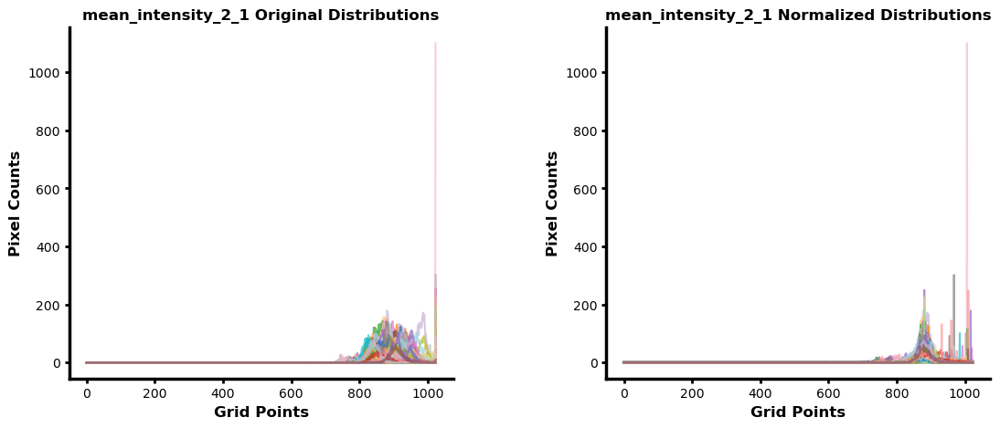


-------------------- Processing marker 'mean_intensity_2_2' --------------------
☑️ No reference provided → will select by proximity
☑️ No landmarks → automatic alignment to mean, selecting 'TMA6_77' by histogram proximity 

✨ Computed shifts: [15, 1, -2, 11, -8, -23, 9, 9, -16, -24, -19, -6, 8, 0, 27, -3, -1, 5, 4, -1, 4, -17, 7, -2, 26, 14, 18, 23, 11, 5, 9, 35, 2, 6, -12, -14, 23, 13, -18, -22, 6, 10, 12, -7, 28, -44, 8, -30, -36, 11, -8, 2, -23, -5, -13, 21, -38, 18, -3, -7, -13, 22, -16, 5, -7, 4, -8, -9, 26, 35, 6, -1, 8, 9, 3, -11, 0, -19, 8, 38, -12, -46, 11, 17, -18, -13, 17, 1, 2, 10, -13, 11, -11, 25, 20, 6, 25, -10, -11, 8, 26, 8, -1, 3, 0, -12, -11, 16, 4, 42, 3, 4, -3, -38, 7, 14, -8, 4, 27, 18, -24, 1, -4, 6, -21, -8, -24, 8, 18, 14, 18, 3, 22, 4, 8, 1, 23, 34, -8, -18, 26, 14, -1, -8, -36, -16, -15, -25, 109, -5, -15, 5, -30, 30, -13, 25, 32, 31, 5, -21, -12, 0, -13, 23, 0, 28, -21, 23, 27, -1, -23, -24, -42, 8, -1, 8, 12, 18, 9, 7, -4, -25, 6, -17, -32, -9, 66, -8, 9,

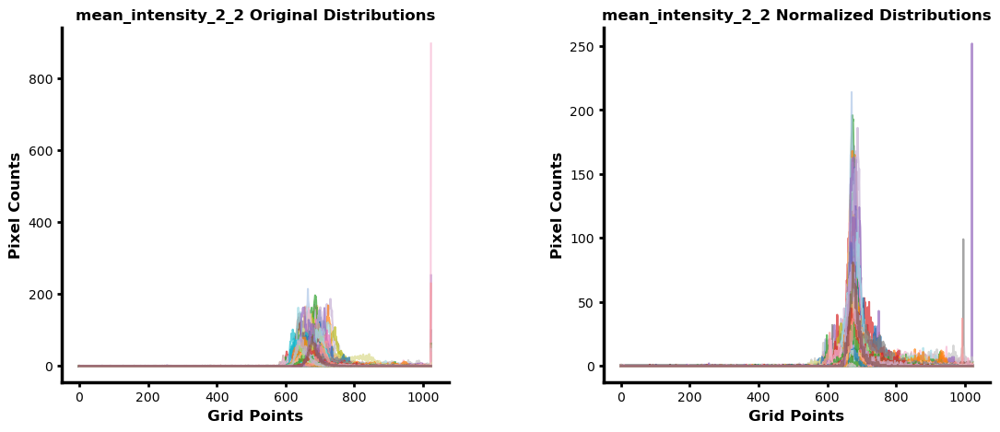


-------------------- Processing marker 'mean_intensity_2_3' --------------------
☑️ No reference provided → will select by proximity
☑️ No landmarks → automatic alignment to mean, selecting 'TMA6_9' by histogram proximity 

✨ Computed shifts: [5, -2, -2, 5, -4, -2, -2, 0, -6, -5, 0, -2, 0, 3, -1, -3, -5, 2, -3, -2, 3, 1, 1, 2, 3, -1, 0, -1, 0, 7, -1, 10, -2, 5, -4, -2, 8, 7, -1, -7, 0, -3, 8, -4, 3, -1, 3, -6, -1, 6, -3, 6, 0, -3, -3, 7, -10, 6, 2, 2, -3, -1, 1, -4, -2, -1, -3, -4, 4, 8, -3, 2, 0, 5, -1, -4, 1, 1, 3, 3, 0, -8, 2, 1, -4, 2, 8, 4, 3, 0, -6, 6, -3, 6, 1, -3, 4, -7, -5, -2, 4, 0, -1, 3, -2, 2, -4, 0, 4, 7, -3, -2, -2, -3, -1, 2, -3, 0, 1, 6, -8, -5, -3, 1, -5, -4, -3, -1, -2, 0, 3, -3, 4, -6, 5, 5, 2, 8, -3, -4, 2, -1, 3, -6, -8, 1, 3, -7, 28, 1, 1, -1, -6, 3, -6, 2, 5, 9, 3, -6, 2, -6, 4, 0, 2, 3, -3, 4, 4, 2, 2, -6, -2, 2, 3, 5, -3, 2, 0, 3, -5, -10, -2, -5, -5, -3, 16, 2, 2, 7, 2, -1, 0, -3, -1, -8, -1, -6, -1, -6, -3, 1, 4, 2, -3, -2, -5, -1, 1, -6, -4, 8, 4, -7, 3, 3

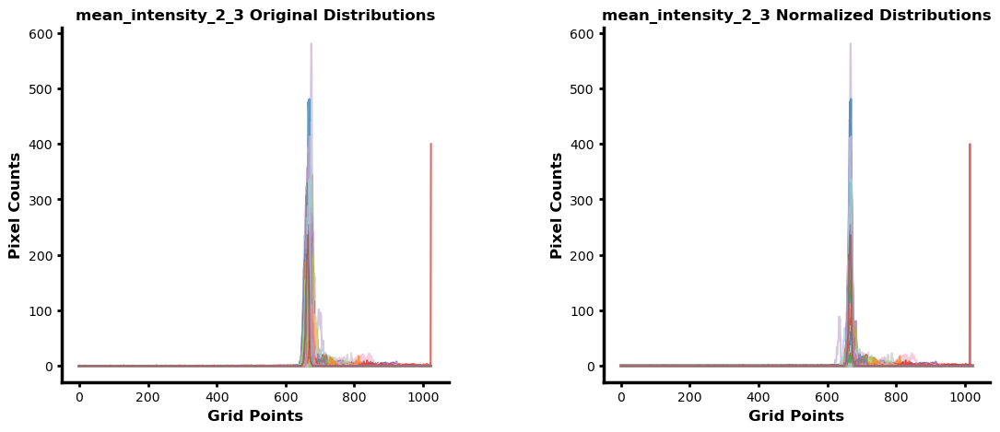


-------------------- Processing marker 'mean_intensity_3_1' --------------------
☑️ No reference provided → will select by proximity
☑️ No landmarks → automatic alignment to mean, selecting 'TMA14_88' by histogram proximity 

✨ Computed shifts: [-20, 22, -38, 4, 1, -18, 28, 17, 6, -13, -35, 5, 32, -13, 34, 32, 1, -40, -3, 21, -16, -24, 4, -41, 41, 36, 37, 17, 29, -10, 28, 42, 3, -33, -22, 12, -17, -7, -3, -21, 32, 16, -2, 1, -20, -60, -31, -6, -53, -49, 6, 10, -32, 10, 2, 20, -44, 4, -25, -51, 4, 57, -28, -10, -1, 8, 0, -9, 68, 69, -2, -7, 11, -9, 7, 0, 12, -42, -8, 23, -44, -39, 22, 55, -3, -34, -11, -14, -39, -36, 5, 4, 16, 28, 23, 18, -7, -15, -3, 12, 42, 22, -2, -40, -2, -54, 19, -38, -26, 84, 26, 15, -3, -63, 17, -34, 1, 0, 45, 9, -43, -11, 6, 34, 2, 0, 2, 24, 16, 27, 95, 10, 61, 11, -16, -13, 49, 19, 25, -4, -7, 17, -47, 8, -38, -32, -39, -3, 139, -43, -43, 13, -16, 9, -24, 31, 39, 10, -24, -12, -17, -3, -27, 35, -47, -8, 6, 35, 54, -40, -16, -22, -61, -22, -15, -2, -7, 1, 20, -

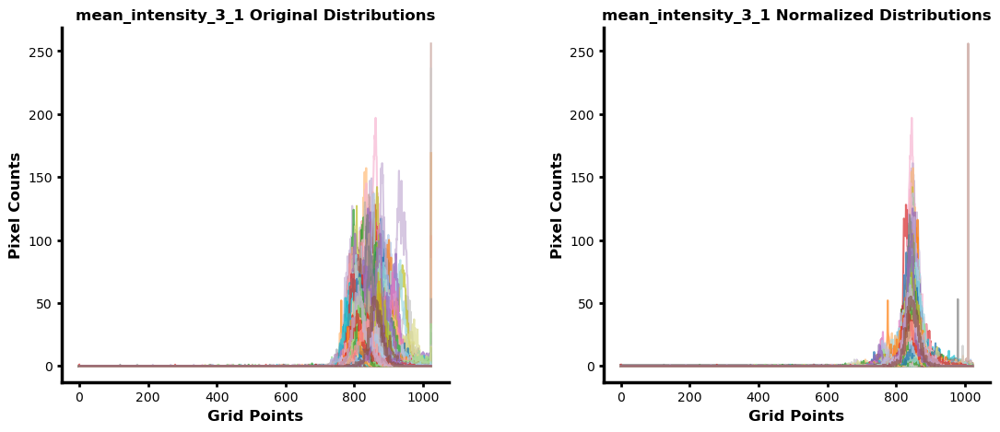


-------------------- Processing marker 'mean_intensity_3_2' --------------------
☑️ No reference provided → will select by proximity
☑️ No landmarks → automatic alignment to mean, selecting 'TMA14_88' by histogram proximity 

✨ Computed shifts: [8, -5, -26, 11, -8, -28, 94, 1, 21, -40, -3, 8, 18, 16, 17, 9, -3, -17, -1, 21, 9, 4, -6, -15, 16, 25, 25, 11, 12, -4, 42, 29, -8, -3, -7, -26, -8, 14, -32, -15, 27, 15, 14, 0, 17, -42, 5, -23, -18, -22, 16, 9, -2, 10, 17, 24, -31, 9, -7, -21, -17, 13, 10, -13, -12, 30, -5, -5, 26, 29, 1, 34, 27, -1, -12, -11, -10, -22, 4, 18, -10, -34, 7, 30, -11, -19, 0, 3, -10, -2, 0, 21, -11, 7, 22, 20, 22, -1, -4, 9, 32, 22, -6, -19, 4, -23, 26, -3, 6, 78, -1, 1, -2, -29, 4, 3, -2, -15, 24, 15, -25, -15, -15, 28, 11, -4, -30, 35, 12, 4, 62, 9, 42, 16, 6, 11, 26, 39, -7, -14, 43, 16, -15, 19, -16, -2, 27, -2, 93, -1, -25, -5, -20, 7, -11, 23, 27, 19, -8, 4, 1, 17, -14, 36, -11, 14, -6, 14, 25, -11, -5, -28, -35, 8, 7, 14, 9, 4, 10, 19, 13, -12, 14, -11, -4

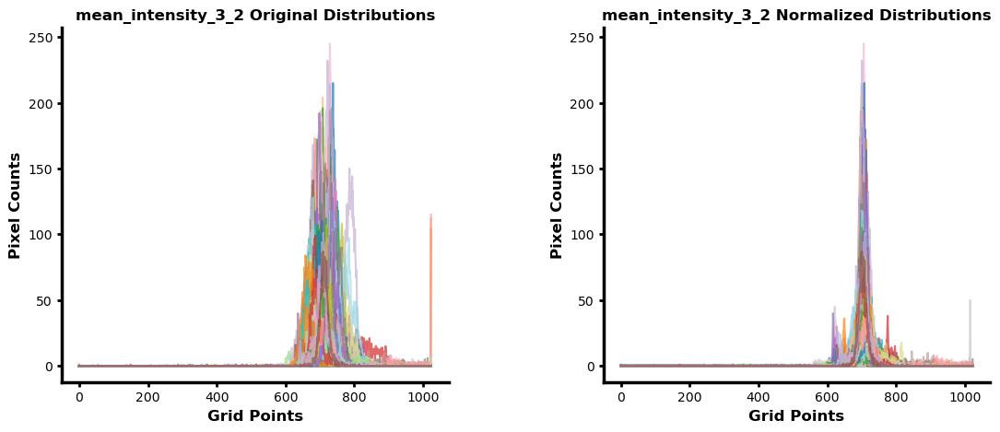


-------------------- Processing marker 'mean_intensity_3_3' --------------------
☑️ No reference provided → will select by proximity
☑️ No landmarks → automatic alignment to mean, selecting 'TMA10_47' by histogram proximity 

✨ Computed shifts: [-16, -32, -11, 5, 31, -9, 58, 6, 22, 9, 13, 60, -6, 16, 13, 50, 8, -5, 47, -5, -11, 21, -3, 123, 39, 44, 39, 28, 24, -3, 16, 6, 12, -2, -10, -23, 9, 0, -39, 45, 18, 44, -3, -21, 51, -12, 67, -18, -8, -6, -3, 13, 12, -9, -22, -6, 10, -11, -2, 10, -33, -26, 50, 7, 21, 98, -1, 12, 1, -6, -12, 166, 68, -1, 5, -26, -10, -6, 22, 83, -4, 13, 90, -17, 2, -22, 153, 10, -17, -21, 8, -5, -21, 10, -12, -7, 22, 59, 67, -13, 24, -1, -23, 2, 7, -12, 57, 4, -1, 52, -29, -2, 83, -9, -3, 36, 14, -20, -5, -5, 48, 7, 3, 17, 31, -20, -41, 8, 26, 22, 26, 78, 62, 6, 7, -15, 96, 15, -11, -6, 114, 4, 16, 98, 13, 71, -6, -2, 50, -20, -18, 8, -7, 51, -5, 24, 19, -3, -7, -8, -7, 43, -16, 36, 8, 22, 31, 18, 48, -21, 38, -17, -14, 59, 9, -1, 58, -16, 12, 17, 44, 32, 12, -1

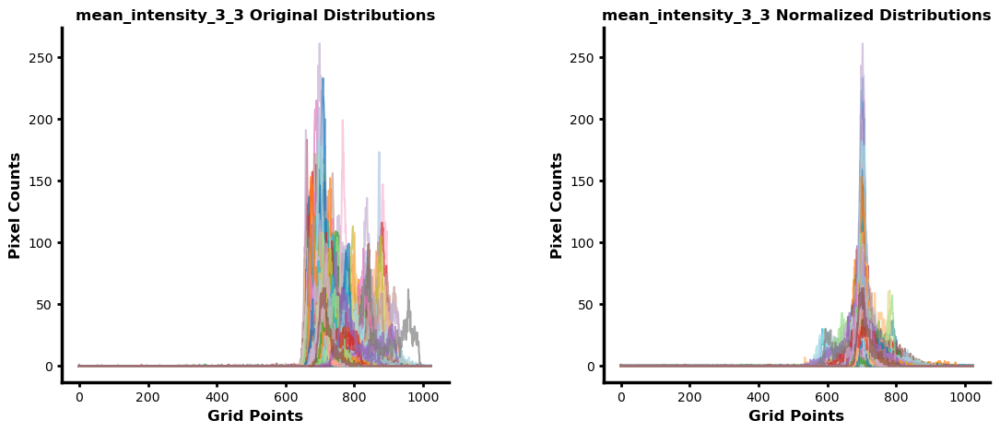


-------------------- Processing marker 'mean_intensity_4_1' --------------------
☑️ No reference provided → will select by proximity
☑️ No landmarks → automatic alignment to mean, selecting 'TMA14_88' by histogram proximity 

✨ Computed shifts: [-35, 23, -34, 3, 20, -17, 25, 6, 20, -7, 12, 21, 20, -15, 31, 30, -8, -61, -8, 20, -22, -37, -10, -51, 25, 27, 14, 22, 28, -24, 23, 24, 1, -44, -26, 6, -23, -22, -5, -22, 23, 6, -26, -5, -21, -77, -41, -8, -69, -66, -3, 20, -35, 4, -6, 12, -47, 5, -37, -63, -5, 52, -45, -22, -12, 4, -3, 8, 39, 55, -2, -6, 22, -23, -4, 0, 6, -43, -20, -5, -53, -32, 14, 46, -6, -38, -20, -23, -47, -58, -13, 5, 12, 9, 18, 18, -17, -16, -14, 2, 43, 31, -14, -43, -8, -67, 16, -54, -41, 82, 22, 17, 1, -74, -2, -39, -1, -6, 25, -10, -10, -15, 13, 29, 17, 4, -5, 30, 14, 6, -17, 14, -39, 9, -16, -5, 43, 9, 21, -4, 2, 2, -67, -1, -29, -39, -28, -11, 134, -48, -56, 0, -6, -15, -26, 30, 33, -2, -39, -14, -45, -8, -22, 35, -64, -32, -3, 24, 40, -39, -15, -27, -74, -47, -17

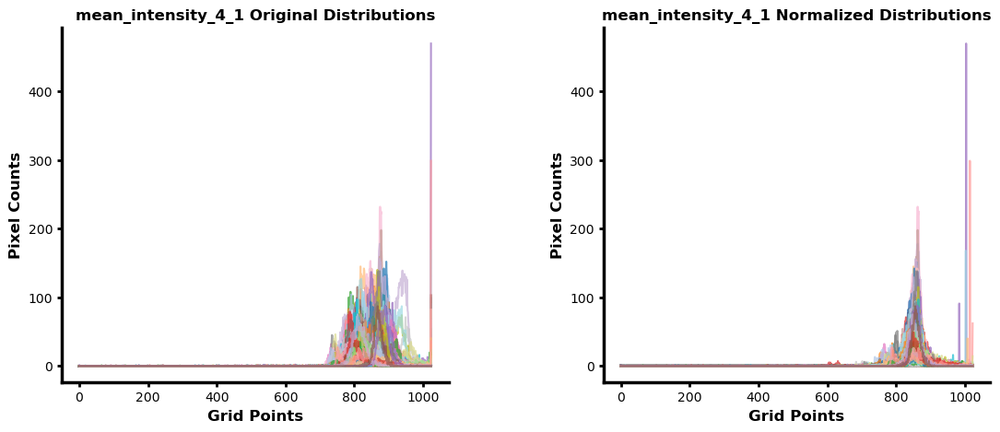


-------------------- Processing marker 'mean_intensity_4_2' --------------------
☑️ No reference provided → will select by proximity
☑️ No landmarks → automatic alignment to mean, selecting 'TMA0_67' by histogram proximity 

✨ Computed shifts: [-10, 27, -13, 5, 109, 3, 38, -4, 104, -34, 147, 97, -8, 28, 15, 1, -20, -32, -8, 55, -2, 25, -4, -29, -4, 30, 7, 26, 119, -16, 22, 10, 33, -24, -6, -4, -14, 14, -20, 86, 3, 7, 5, 3, 12, -16, -17, -12, -18, -3, 14, 40, 61, 6, -10, 15, -7, -1, -23, -34, -3, 61, -7, 29, -18, 17, 40, 90, 6, 11, -11, 56, 96, -1, -28, 38, -13, 36, 4, -6, -21, 0, 12, 46, 49, -26, -17, -7, -18, -38, 0, 5, 44, -12, 0, 8, 8, 10, 12, -5, 21, 80, -7, -31, 29, -21, 52, -21, -21, 61, 41, 41, 61, -13, -21, 6, 58, -8, 5, 10, 92, 15, 81, 57, 115, -11, -14, 69, 54, 2, 20, 47, -11, 18, -10, -4, 16, 20, 13, 17, 60, 58, -35, 20, 62, 43, 74, -9, 60, -27, -42, 2, -2, -14, 6, 5, 17, 11, -21, 25, -4, -5, -31, 15, -32, -11, 91, -8, 9, -9, 24, -39, -5, 2, -5, -8, 121, -10, -3, 14, 18, 3,

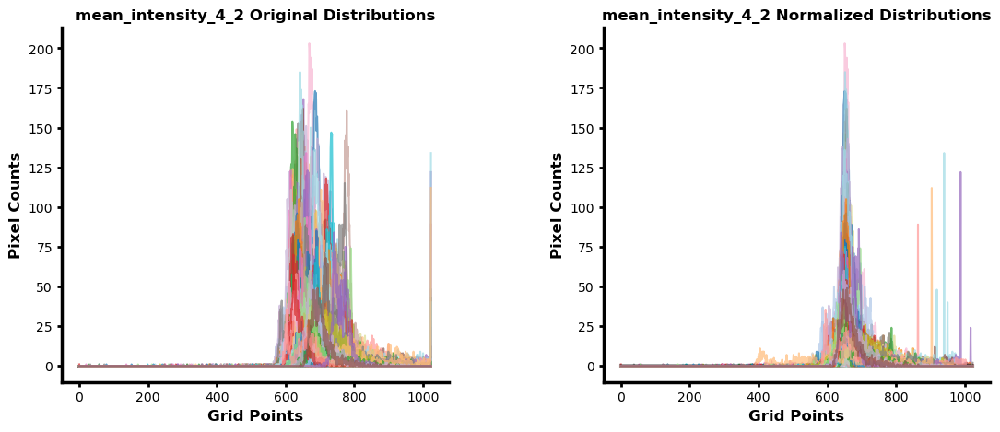


-------------------- Processing marker 'mean_intensity_4_3' --------------------
☑️ No reference provided → will select by proximity
☑️ No landmarks → automatic alignment to mean, selecting 'TMA5_73' by histogram proximity 

✨ Computed shifts: [3, 0, -4, 3, 24, -1, 10, 0, 16, -3, 9, 17, -4, 4, 1, -2, -5, 4, -3, 11, 5, 3, -1, 2, -3, 0, -3, 0, 1, 6, 0, 7, 4, 3, -3, -2, 6, 5, 1, 9, -4, -4, 4, -2, 5, 2, 3, -1, 2, 0, -4, 6, 3, -2, -3, 5, -5, 5, 2, 2, 0, 0, 5, 4, -3, 3, 7, 22, -3, 0, -2, 6, 19, 3, -2, 8, -1, 3, 4, 5, 2, 5, 1, 9, -2, 3, 3, 6, 2, 4, -4, 6, -1, -1, -3, -1, 6, -4, -5, -3, 1, 18, 1, 2, 4, 1, 8, 3, 3, 4, 9, 10, 15, 2, -3, 2, 11, -1, -2, 4, 13, 2, 10, 13, 17, -1, 0, 14, 10, 1, 5, 8, 4, -3, 5, 4, -1, 5, -1, -1, 8, 0, 3, -3, 10, 3, 3, -2, 10, 3, 2, 1, -2, 4, -3, -1, 1, 6, 3, -4, 1, 0, 4, -1, 3, 5, 22, 0, -1, 4, 4, -3, 6, 4, 3, 4, 15, -4, -1, 4, -4, -5, -3, 6, -2, 1, 3, 1, -2, 5, 5, 4, -2, 7, -4, -5, 4, -1, 11, 13, 9, 3, 5, 2, 1, -2, 4, 4, -1, 12, -2, 4, 0, 4, 4, 2, -1, -6, 1, 1, -6,

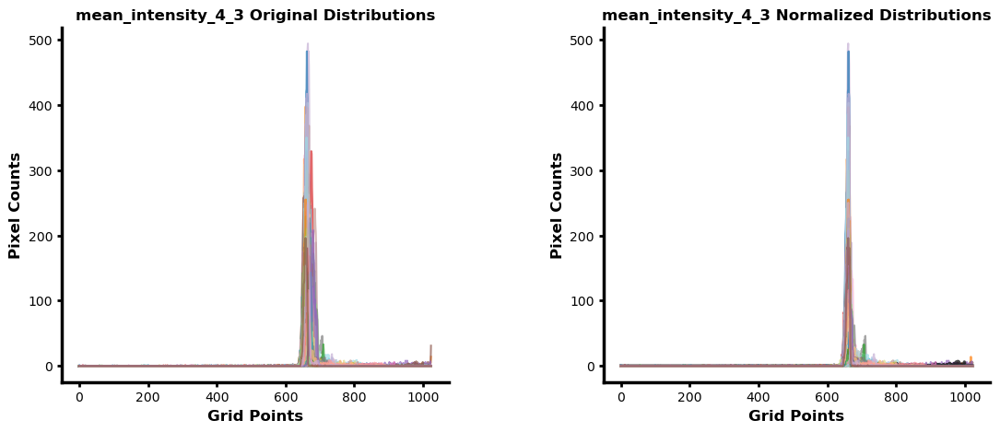


-------------------- Processing marker 'mean_intensity_5_1' --------------------
☑️ No reference provided → will select by proximity
☑️ No landmarks → automatic alignment to mean, selecting 'TMA5_34' by histogram proximity 

✨ Computed shifts: [-64, 78, -33, -1, 11, -9, 58, 20, -5, 0, -35, 79, 61, -30, 69, 95, 33, -83, -14, 62, -89, -21, -10, -100, 75, 69, 166, 54, 113, -40, 64, 46, 28, -78, -35, 37, -21, -18, -6, -43, 43, 107, -5, 16, 1, -120, 3, -10, -96, -98, 3, 2, -33, 13, 17, 18, -83, -3, -38, -114, 6, 127, -48, -19, 13, 79, 30, -33, 102, 97, 11, 54, 30, -12, 2, 32, 26, -64, -7, 63, -64, -51, 36, 102, 27, -73, -1, -22, -93, -44, 11, -3, 12, 36, 27, 45, 25, -82, -33, 11, 100, 52, -2, -67, 26, -129, 149, -40, -81, 194, 62, 47, -3, -130, 38, -30, 6, 15, 100, 13, -18, 13, -15, 68, -7, -2, 6, 46, 48, 20, 25, 19, -32, -2, -14, -27, 37, 43, 27, 17, 172, 25, -130, 82, -97, -11, -86, -24, 228, -67, -66, 17, 10, 69, -97, 62, 93, 5, -149, -13, -46, 31, -65, 54, -114, -7, 331, 34, 98, -81, -

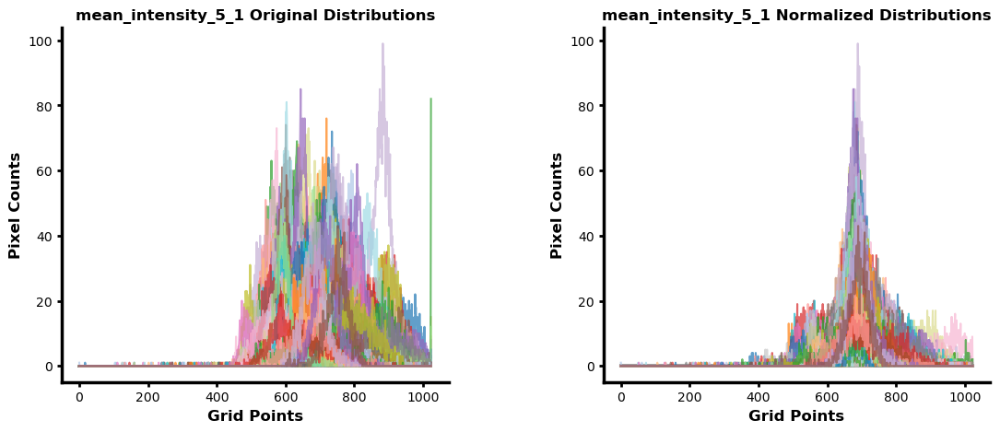


-------------------- Processing marker 'mean_intensity_5_2' --------------------
☑️ No reference provided → will select by proximity
☑️ No landmarks → automatic alignment to mean, selecting 'TMA6_31' by histogram proximity 

✨ Computed shifts: [-22, 20, -56, 2, -32, 14, 59, 14, -12, -55, -19, -14, 90, 6, -1, 29, 143, -67, -53, 60, -51, -34, -27, -27, 109, 64, 141, -1, 35, -11, 58, 39, 30, -42, -19, -50, 16, -4, -45, -63, 22, 123, 10, -31, 7, -89, 16, 2, -64, -79, 11, -15, -38, 27, 39, 13, -63, -8, -29, -73, -12, 59, -65, -24, -15, -4, 27, -44, 87, 30, -28, 18, -23, 25, -48, 18, -16, -57, -5, -15, -31, -44, -4, 74, 10, -50, -36, 43, -53, -48, -23, 26, -23, 13, 16, 65, 18, -21, -9, -22, 59, -17, -14, 21, 35, -90, 33, -40, -41, 114, 45, 52, -55, -59, 87, 16, -50, -16, 149, 44, -35, 42, -61, 60, -41, -37, -45, -3, 44, 0, 8, -14, -31, 22, 14, -8, -35, 41, -27, 0, 47, 43, -79, 28, -97, -29, -65, -31, 176, -33, 13, 8, 24, -32, -113, 6, 49, -3, -94, 11, -22, -20, -59, 6, -77, -25, 270, 27, 89

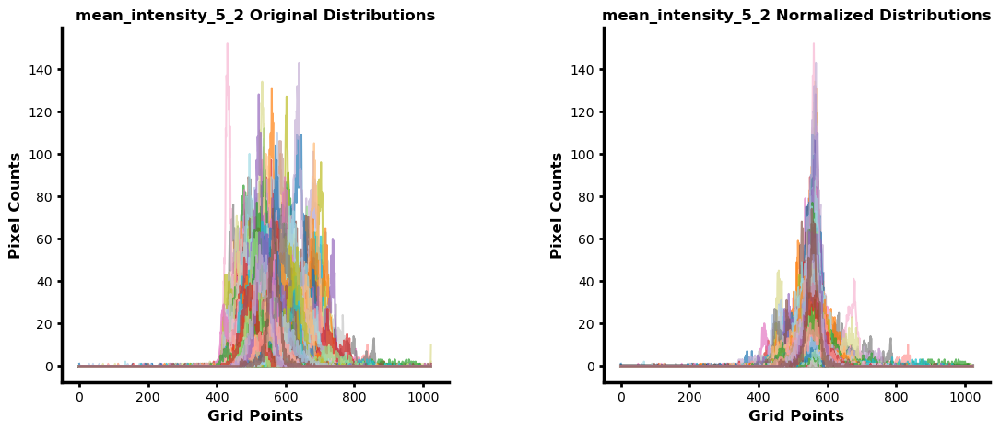


-------------------- Processing marker 'mean_intensity_5_3' --------------------
☑️ No reference provided → will select by proximity
☑️ No landmarks → automatic alignment to mean, selecting 'TMA11_5' by histogram proximity 

✨ Computed shifts: [3, -2, -8, 7, -7, 5, 9, 4, -9, -5, 6, -9, 20, 3, -8, 4, 26, 2, -8, 8, 3, 0, -1, 2, 23, 1, 23, -8, 4, 15, -2, 11, 5, 2, -7, -5, 7, 6, -2, -13, -7, 20, 5, -10, 8, 0, 5, 5, -2, -2, -8, 4, 0, -6, -3, 6, -11, 7, 5, 2, 1, 6, 1, -3, -3, -4, 3, -9, 19, 5, -9, 2, -8, 5, -6, 2, -2, -1, 5, 5, 2, -7, 0, 9, 3, 4, 4, 8, 3, 4, -9, 11, -2, 1, -6, -2, 7, -11, -9, -9, 6, -9, 1, 6, 3, -1, 3, 3, 2, 0, 5, 6, -10, -2, 18, 4, -9, 1, 24, 6, -12, 7, -9, 9, -11, -11, -7, -7, 5, 0, 9, -11, 5, -10, 9, 7, -3, 9, -3, 3, 5, -2, 1, -6, -12, 1, -2, -10, 37, 3, 5, 0, 2, 4, -11, -5, 6, 9, 1, -8, 4, -9, 8, -8, 1, 4, 220, 3, 19, 4, 0, 0, -3, 5, 8, 5, -8, -6, -4, 7, -9, -10, -9, 3, -6, 7, 26, 5, -3, 7, 2, 0, -4, -9, 29, -10, 1, 5, 7, -12, 5, 0, 5, 4, -3, -7, 0, 0, -5, -14, 27, 6, 1

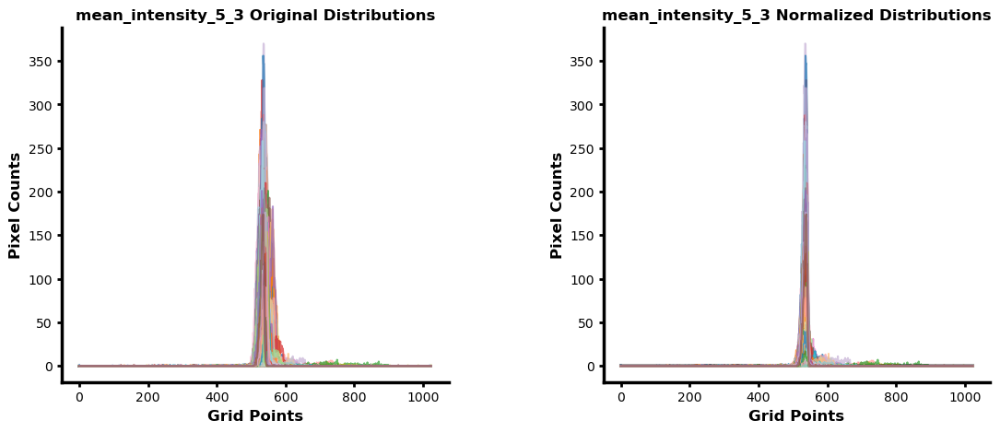


-------------------- Processing marker 'mean_intensity_normalized' --------------------
☑️ No reference provided → will select by proximity
☑️ No landmarks → automatic alignment to mean, selecting 'TMA9_72' by histogram proximity 

✨ Computed shifts: [31, -24, -17, -12, 28, 39, -3, -1, 14, -11, -21, -4, -2, -4, -29, -24, -6, -30, -2, 9, 12, 3, -20, -22, -16, -21, 27, -31, -27, 27, -5, -5, -31, -22, -20, -30, 8, 4, 4, -1, 17, -6, -14, -4, -21, -23, -2, -5, 46, -4, -29, 2, -21, 5, -1, 0, -17, -2, 3, -5, -15, 8, -14, -21, -29, -19, -4, 4, 0, -30, -4, -21, -13, -16, -4, -38, -19, -31, 1, 12, -23, -10, 15, 30, -15, -25, -33, -5, 0, 16, -39, 20, -5, 14, -18, -22, 25, 5, -8, -5, -33, 28, -15, 1, -12, -15, 11, 4, 1, -27, -27, 9, 11, 1, -18, -8, 0, 11, 23, 1, 14, 26, 29, 14, -3, -11, -23, -4, -17, 7, 25, -7, -9, -1, -37, -4, 20, -13, -19, -14, 11, 2, 7, 11, 15, -26, -41, -8, 20, -12, 4, 1, -26, -1, -15, 21, -17, -35, -2, -4, -9, -5, 5, -12, 2, -15, -22, -13, -35, -16, -1, 20, 26, -11, 5, -18, 

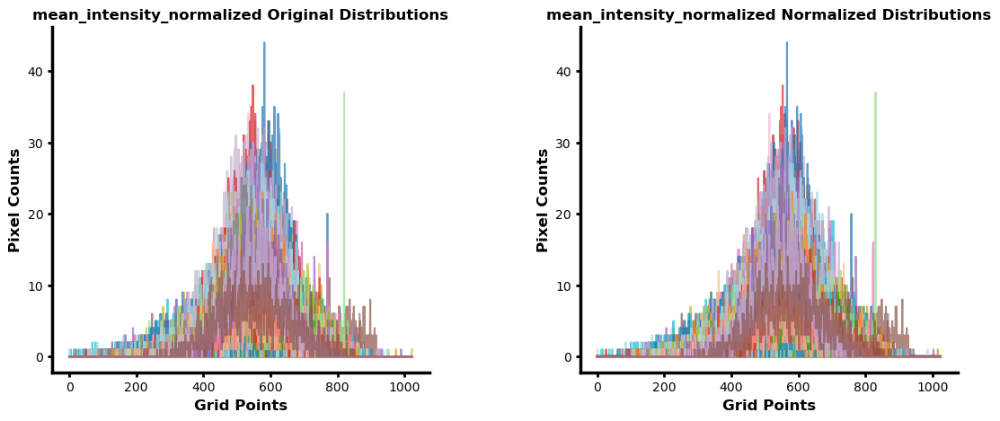


-------------------- Processing marker 'mean_intensity_0_1_normalized' --------------------
☑️ No reference provided → will select by proximity
☑️ No landmarks → automatic alignment to mean, selecting 'TMA1_0' by histogram proximity 

✨ Computed shifts: [3, -6, 4, 5, 4, 10, 18, 3, -3, 24, 14, 6, 7, -2, 18, 12, 2, 9, 11, -5, -9, -4, 2, -1, 12, 2, 4, 3, -15, 27, -4, -4, 11, -33, -15, 5, 16, 11, 116, -7, 9, -2, -3, -11, -22, 28, 10, -1, 12, 0, 10, -17, -9, -10, -5, -7, 11, 11, -13, -14, 1, 0, 2, 8, -10, -6, -9, -2, 6, 12, 4, 11, 0, 1, 7, 0, 1, -2, 0, -17, 5, 7, -6, 10, 6, 4, -27, 2, 2, -4, 5, -9, -2, 22, -18, -3, 8, 9, -7, 0, 2, 10, -25, 20, 6, -2, -9, -4, 0, -20, 14, 8, 8, 0, -3, -2, -2, -2, 10, 3, 16, -9, -7, -12, -3, 4, 0, -1, 6, -8, 10, 7, 3, -10, 7, 0, -45, 0, -8, 10, 3, 6, -1, 5, -5, -2, -6, 7, -20, 4, 8, 7, 4, 5, -10, 33, 18, 13, -6, -2, 0, 8, 26, 0, 14, -9, -45, 21, -3, 0, -1, 11, 30, 4, -1, 3, 0, -2, -8, -4, 9, 18, 9, -17, -20, 19, -20, -12, 4, 8, -7, -5, -10, -7, 2, -11, -5, 11

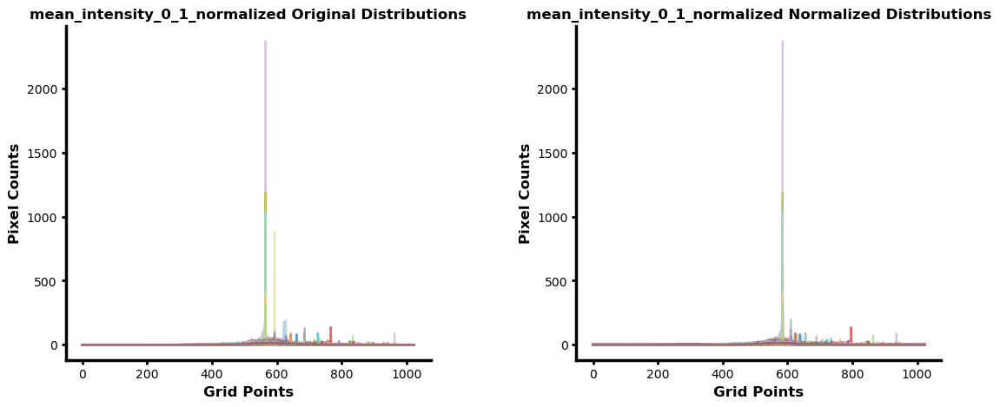


-------------------- Processing marker 'mean_intensity_0_2_normalized' --------------------
☑️ No reference provided → will select by proximity
☑️ No landmarks → automatic alignment to mean, selecting 'TMA7_88' by histogram proximity 

✨ Computed shifts: [-4, -1, -2, 7, 13, -8, 1, -2, -8, 11, 4, 2, 0, 3, 7, -1, 3, -1, 5, -10, 10, 1, 0, -4, -5, 25, -5, 0, 2, -1, 3, 1, -4, -4, -2, -5, 2, 2, 0, -1, 15, 0, -3, 11, -13, -4, 2, 2, -1, 0, -5, -3, -6, 11, -4, -5, -2, -4, 0, -3, -2, -4, 4, 9, 0, -3, -2, 3, 3, 13, 11, -2, -2, 8, 0, -2, 1, -2, 8, 1, -5, 7, 0, 0, 3, 7, -5, -4, -10, -10, 3, 1, 9, 13, 3, 7, 0, -2, -1, -4, 9, 0, -4, 4, -4, 4, -5, 1, -2, 6, 0, -4, -5, 2, 0, 4, 1, 2, -1, -4, 7, -1, -1, 3, 3, -2, -1, 4, 3, 20, -1, 0, -6, -1, 1, 7, 23, -4, 8, 6, 0, -4, -1, -1, -2, 0, -8, -5, 7, -6, 6, 3, -5, -2, 3, 14, 4, 6, 2, 6, -6, -9, 22, 12, -8, -5, -34, 12, 8, -2, 10, 0, -3, 9, 2, 13, -1, -1, -5, -4, -7, -6, 7, -1, 3, 8, 2, 5, 5, 1, -1, 0, 3, -3, -4, 2, 0, 1, 2, 3, -3, 8, -1, 4, 2, 13, 4, 4, 3, -4

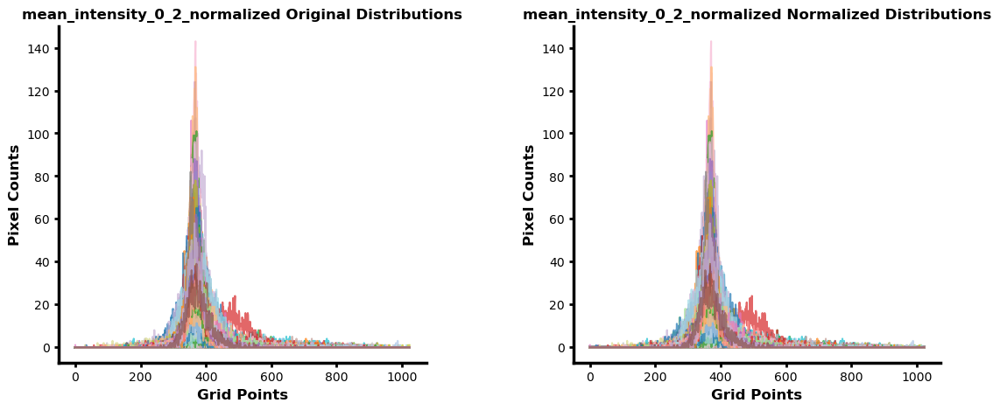


-------------------- Processing marker 'mean_intensity_0_3_normalized' --------------------
☑️ No reference provided → will select by proximity
☑️ No landmarks → automatic alignment to mean, selecting 'TMA1_0' by histogram proximity 

✨ Computed shifts: [-34, -23, 18, -13, 104, 44, -1, 31, -5, 22, 35, 64, 13, -7, 66, -6, 3, -12, 6, -1, 21, 38, 23, 7, 60, -7, 19, 94, 3, 11, -9, -13, 68, 25, -23, 7, -21, -11, 25, 54, 95, 4, 20, 118, -23, 94, 11, -22, 49, 43, 1, 68, 82, 11, -18, 51, -15, -16, 13, 21, -24, 17, 41, -11, 44, 54, 99, 30, 65, 17, 69, 3, 23, 3, 32, 119, 8, 38, -13, 3, -8, -9, 55, -26, 47, 13, 6, 2, 18, -40, 100, -6, 42, 23, 66, -8, 33, -4, 0, 131, -10, -19, 16, -22, -17, 21, 103, -2, 20, -10, 65, 16, 33, -5, 19, -32, 31, 76, 16, 3, -13, 88, -6, -2, 21, 2, 11, -9, -15, 36, -23, 56, 16, -28, 2, -13, 18, -15, -2, 12, 14, -26, -23, -10, 10, -2, 152, -1, -24, 16, -15, -6, -19, -4, 3, 58, 27, 0, -23, -4, 15, 41, -3, 24, 18, -11, 33, 22, 19, 1, 35, -9, 19, -25, -23, -22, 96, 96, 13, 

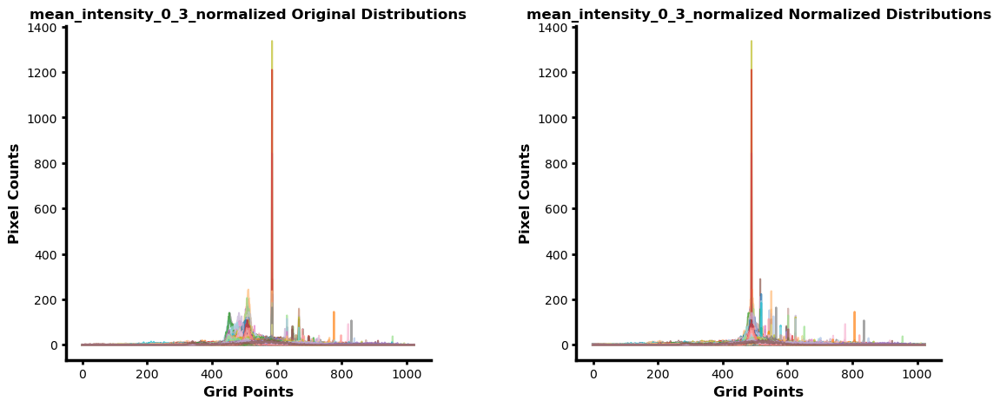


-------------------- Processing marker 'mean_intensity_1_1_normalized' --------------------
☑️ No reference provided → will select by proximity
☑️ No landmarks → automatic alignment to mean, selecting 'TMA7_56' by histogram proximity 

✨ Computed shifts: [-5, 5, -2, 18, 3, -1, 22, 2, -4, 13, 25, -5, 13, 2, -3, -6, 19, -5, 0, -3, 5, 11, -5, 2, -1, 18, -3, 2, 0, 11, 7, -6, -3, -1, 17, 3, 7, 5, 0, -2, 9, 1, -3, 1, -4, 20, -4, -1, 3, 11, -26, 7, -2, 8, 7, 2, 0, -2, 1, -2, -1, 3, 7, -3, 3, 4, -4, -1, 17, 7, 1, 0, -1, 1, 1, -1, 10, 7, 5, -4, -3, 4, -1, 7, 14, 9, 0, 4, -3, 2, -1, 0, 3, 27, -3, 0, 4, -3, 31, -1, 20, 4, 2, 1, -2, -3, 3, 0, -6, 15, 19, -6, -3, 7, 0, 4, -4, 5, 0, 30, -6, -2, 9, 5, -3, -1, -1, -2, 3, 13, -4, -5, 3, -1, 0, 12, 14, 6, 0, -1, -3, 2, -6, -3, -6, 3, 14, 7, 32, -5, -4, 24, 6, -3, -2, 7, 27, -2, -5, 2, 2, 2, 12, 3, -1, 0, 39, 20, 13, 0, 13, 3, 24, -2, 6, 19, 0, 3, -1, -1, 6, -4, -4, 6, -1, 19, 32, 12, 13, 3, -3, 22, 2, -5, 5, -5, 2, 1, -1, -2, -6, 12, 3, 1, 1, 2, 9, 9, 

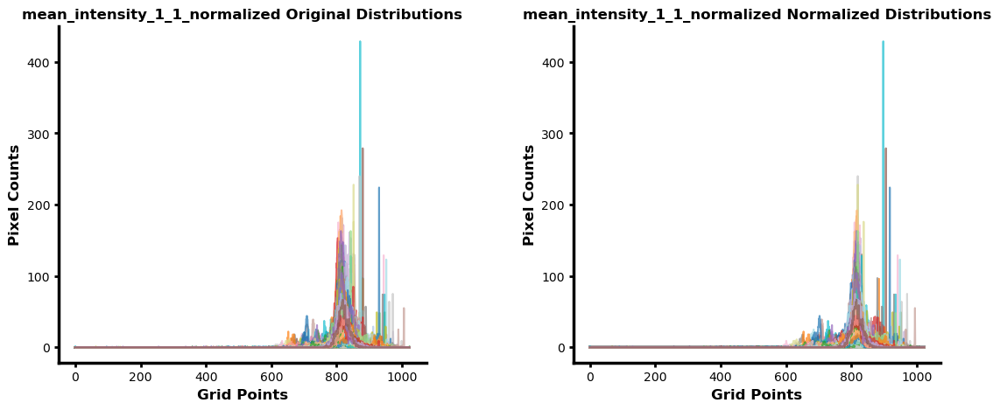


-------------------- Processing marker 'mean_intensity_1_2_normalized' --------------------
☑️ No reference provided → will select by proximity
☑️ No landmarks → automatic alignment to mean, selecting 'TMA13_47' by histogram proximity 

✨ Computed shifts: [1, -2, 0, 2, 2, -1, 2, 0, 0, 0, 0, -1, -1, 1, 1, 1, -3, -2, 1, -2, 1, -2, 1, 1, -1, 1, 2, 0, 0, 0, 0, -2, -1, -1, 2, 0, 0, -3, -6, 1, -1, 1, -1, 0, 1, 1, 1, -1, -1, -2, -10, -2, -3, -2, -2, -3, 1, -2, -1, -1, -1, -5, -1, 1, -1, -1, 0, -3, 1, -3, 1, 0, 2, 2, 0, 1, 3, 1, 0, 1, -1, -3, 0, 2, -2, -1, -3, 1, 0, -3, 1, 1, -1, 0, 0, -1, -5, -1, 1, -1, -1, 1, 1, -5, 2, 0, 2, -1, 0, 1, -2, -1, 0, 0, -1, 1, 1, 1, -2, 3, 2, 1, -1, 1, 0, 0, 1, -1, 1, 0, -1, -3, 1, -3, -1, 0, 12, -2, 2, 0, 1, 1, 2, 1, 0, -1, -8, -1, 2, 2, 0, 1, 1, 1, -1, -3, 1, -1, 1, -1, 1, -1, 6, 0, 0, 1, 7, -1, -3, -3, -1, 0, 2, 0, 1, -1, -1, -1, 0, 0, -1, 1, 1, 1, -1, 1, 1, 2, -1, -2, 0, 1, 2, 1, -1, -1, -3, 1, 0, 1, -1, -1, 0, 1, -1, 0, -3, 0, -1, 1, -4, -1, -1, 2, 1, 0, 0,

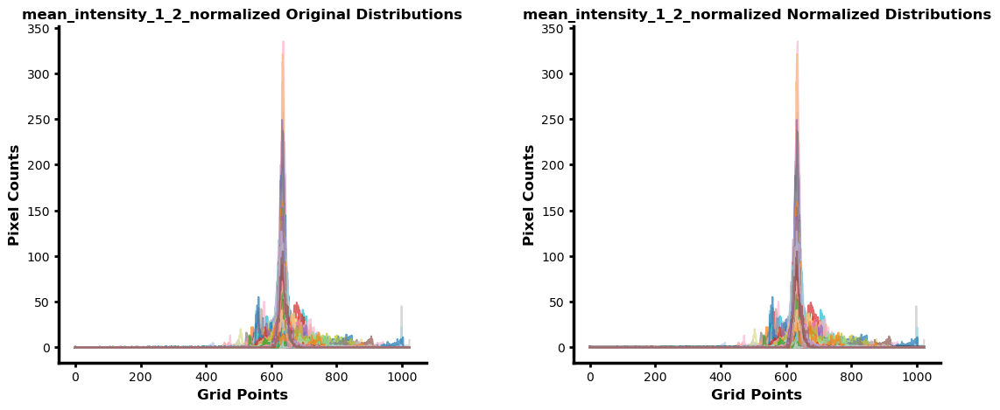


-------------------- Processing marker 'mean_intensity_1_3_normalized' --------------------
☑️ No reference provided → will select by proximity
☑️ No landmarks → automatic alignment to mean, selecting 'TMA6_78' by histogram proximity 

✨ Computed shifts: [-1, 0, -1, 0, 1, 0, 1, 1, -1, 0, 2, -1, 0, 1, -1, 0, 0, -1, 0, 0, -1, 0, 18, 0, -1, 1, -1, -1, -2, 0, 0, 0, 0, 2, -1, 0, 0, 0, -1, 0, 0, -1, -1, -1, -1, 1, 0, 1, 1, 1, 2, 0, 0, -1, 0, 0, 0, 0, 1, 0, -1, 0, 0, 1, -1, 1, 0, 0, -1, 0, 0, 0, 0, 0, 0, 1, -4, 0, 0, 0, 0, 0, 2, 1, 0, -1, 0, 0, 0, 0, 0, 1, 0, -2, 0, 0, 0, -1, 0, 0, 0, 0, -2, 3, 1, 0, 0, 1, 0, 0, 1, 0, -1, 1, 0, -2, -1, -1, 0, 0, 0, -2, -1, -1, 1, 1, 0, 0, 1, 2, 0, 0, 1, -2, 0, 0, 0, 1, 0, -1, 0, 0, 0, 0, 0, 0, 1, 0, 3, 1, 0, 1, 0, 0, 0, 2, 1, 2, -1, 0, 0, 0, -1, 1, 0, 0, 0, -2, 1, 0, -1, 0, 1, 0, 0, 0, -2, 0, 2, 1, 2, -1, 1, 0, 0, 4, 1, 0, 0, -3, 0, 0, -3, 0, 0, 1, 1, 1, 0, 0, 0, 0, -1, 2, 0, 0, -1, 0, 1, 1, -1, 1, -3, 0, 0, 2, 0, 0, 0, 0, -2, -2, 1, 1, 0, -1, 0, 0, 0, 0, 1,

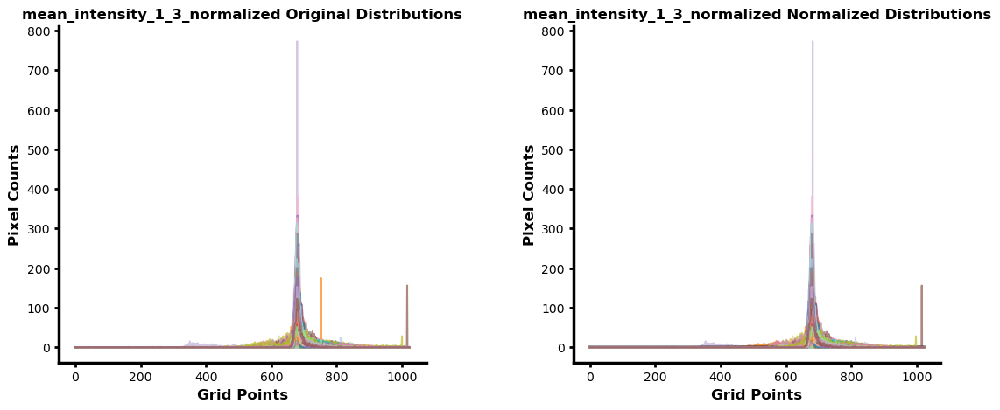


-------------------- Processing marker 'mean_intensity_2_1_normalized' --------------------
☑️ No reference provided → will select by proximity
☑️ No landmarks → automatic alignment to mean, selecting 'TMA8_38' by histogram proximity 

✨ Computed shifts: [0, 0, 4, 6, 0, 3, 3, 5, -1, 6, 0, 0, 3, 2, 1, 1, 2, -2, -3, -1, 5, 2, 0, -3, 0, 5, 0, -1, 1, 1, 2, 4, 2, 0, 1, 2, 2, 0, -2, -4, 4, -2, 1, 0, 0, 0, 0, 2, 1, 12, 1, -2, 0, 3, 0, -1, 0, -2, 2, 4, 1, 3, -1, 6, 4, -3, 0, -2, 0, -3, 0, 0, 0, 3, 0, 3, 10, 0, 1, 0, 1, 3, 3, 2, 1, 0, 3, 2, 5, -1, -2, 3, 1, 5, -4, 0, -2, 2, -1, 6, 2, 1, 1, 2, 2, 0, -1, 4, 2, 2, 0, 1, 1, 2, -1, 1, 0, 0, 4, 2, 0, 0, 0, 3, 0, -1, 6, -2, 1, 0, -4, -4, -3, -1, -1, 6, 16, 2, -3, 5, 4, 0, 0, -4, -2, -1, 7, -3, 2, 0, 3, 0, -2, -2, 6, 5, 5, -1, 1, 0, -1, -1, 6, 0, -1, 0, 15, 6, 0, 0, -3, 0, -3, 2, 2, 7, -3, 4, 3, 1, 0, 0, 5, 0, 1, 4, 0, 2, 3, 0, 2, 0, -3, -3, 2, 0, 4, 3, 0, 0, -4, -2, 2, 1, 3, 0, 4, 2, 3, 0, 1, 0, -2, 0, 1, 0, 0, 3, 0, 0, 5, 0, 2, 2, 1, 1, -1, 4, 2, 4,

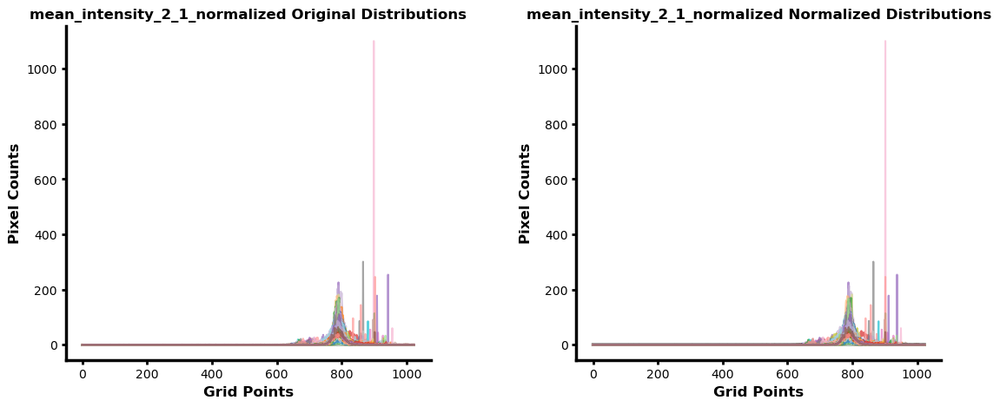


-------------------- Processing marker 'mean_intensity_2_2_normalized' --------------------
☑️ No reference provided → will select by proximity
☑️ No landmarks → automatic alignment to mean, selecting 'TMA6_65' by histogram proximity 

✨ Computed shifts: [-4, 1, 10, 6, 6, 1, 0, 1, -2, 0, 3, -1, 1, -2, -1, 3, -3, -2, -1, -1, 5, 3, 1, -2, -2, 6, 1, 3, 6, -2, 1, 1, 0, -1, 0, 5, 0, 3, -2, -1, 2, -3, -1, 0, -3, 0, 1, -2, -2, 6, -2, -1, -1, 2, -1, -2, -3, -2, 0, -1, -1, 2, 0, 1, 0, 0, 0, 0, 4, 5, 1, -1, -3, 0, -2, -2, 5, -5, 3, -1, -4, -2, 3, 1, 0, 1, 1, 0, 0, -1, 0, 1, 0, 6, 3, 3, 2, -2, -1, -2, 4, -2, 6, -5, 2, -2, 7, -2, -4, 7, 3, 3, -3, -3, -2, -2, -1, 3, 1, 2, -3, 1, 0, -1, 3, 2, 3, -2, -3, 3, 0, -6, 1, 1, -1, 6, -8, -3, -1, 1, 1, -2, -2, -2, -3, -1, 5, 5, 2, -1, -1, 1, -1, -2, 0, -1, 1, -4, -2, -3, -1, -3, 4, -1, -2, -3, 11, 7, 2, 0, 1, 5, 0, 1, 0, 6, 1, -1, 3, -1, -1, -1, 3, 2, 3, 5, 6, 1, 1, -2, 0, -4, -2, -1, 0, -2, 1, 0, -2, -2, 3, -1, 4, -4, -3, 0, 3, 2, 0, -2, -3, 0, 5, -1, -5, 

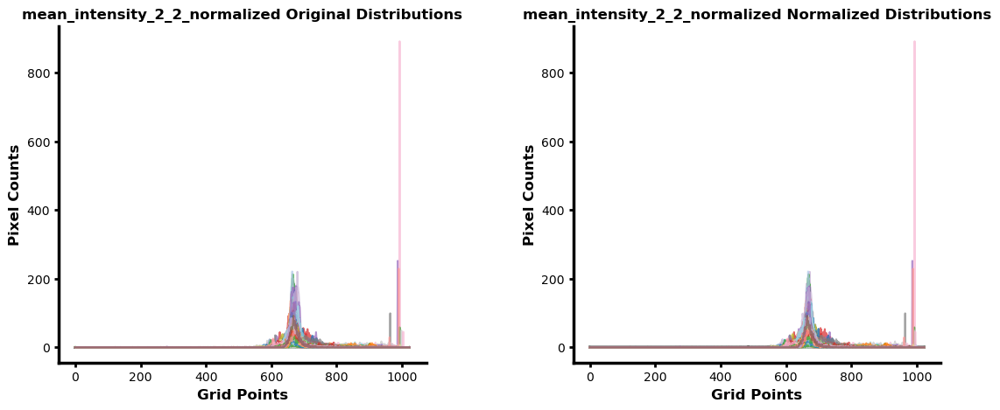


-------------------- Processing marker 'mean_intensity_2_3_normalized' --------------------
☑️ No reference provided → will select by proximity
☑️ No landmarks → automatic alignment to mean, selecting 'TMA12_47' by histogram proximity 

✨ Computed shifts: [0, 0, 1, 0, 1, -1, 1, 1, 1, 0, 0, -1, 0, 0, 0, 0, 0, 1, 0, 0, 0, 1, 0, 0, -1, 0, 0, 0, -1, -1, 0, -1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, -2, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, -1, 1, 0, 0, 0, 0, -1, 0, 0, -1, 0, 0, 0, 0, 0, -1, 0, 0, 0, -1, 0, 0, 0, 2, 1, 0, 0, -1, 0, 0, 0, 0, 0, -1, 0, -1, 0, 0, -1, 0, 0, 0, 1, 0, 1, 0, 0, 0, -1, 0, 1, 1, 1, 0, 0, 0, 0, -1, 1, 0, 1, -1, 1, 0, 0, 1, 0, 0, -1, 0, 0, 0, 0, 0, 0, -1, -1, 0, 0, 0, 0, 0, -1, 0, 0, 0, 0, 0, 0, 0, 0, -1, 0, 1, 1, 0, 0, 1, 0, 0, 0, 0, 0, 0, -1, -1, 1, 1, 0, -1, 0, -2, 1, 0, 0, 0, 1, 0, 0, 1, 0, 0, -1, 0, 0, 0, 0, 1, 0, 0, 0, -1, 0, -1, 0, 1, -1, -1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 1, -1, 1, 0, 0, -1, 0, 0, 0, 1, 0, 0, 1, 0, 0, 0, 0, -1, 1, 1, 0, 0, 0

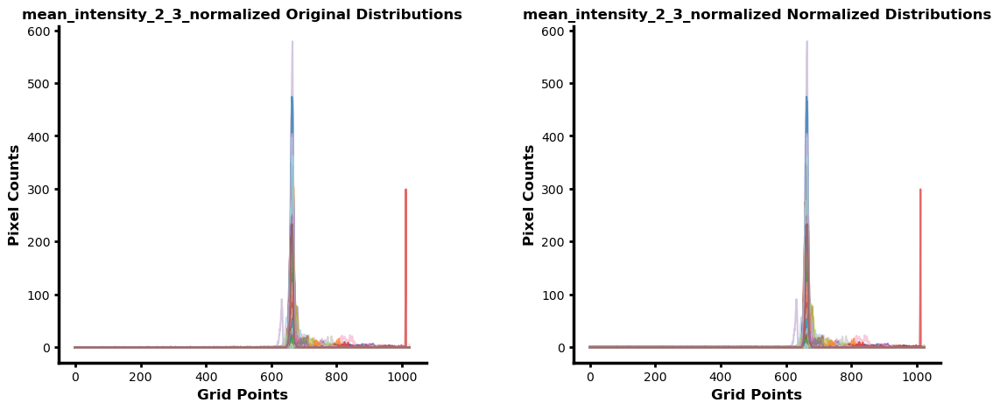


-------------------- Processing marker 'mean_intensity_3_1_normalized' --------------------
☑️ No reference provided → will select by proximity
☑️ No landmarks → automatic alignment to mean, selecting 'TMA2_81' by histogram proximity 

✨ Computed shifts: [3, 2, 1, 9, 4, 1, 14, 5, 4, 6, 1, 3, 1, 15, 4, 2, 3, -2, 0, 3, 6, 6, 1, 6, 4, 3, -2, -1, 2, -1, 0, -4, 0, 4, 0, 4, -4, 3, -4, -4, -1, 6, -3, 1, 1, -4, -1, 3, 1, 0, -1, 7, 0, 3, 2, -2, 4, -3, 5, 2, 3, -2, 1, -2, 1, -1, 3, 1, 4, 3, 6, -1, 7, -6, 0, 3, 0, 4, 0, 2, 3, -1, 2, 1, 1, 4, -5, -4, -1, -1, -1, 2, 4, 9, 2, 0, -2, 4, 2, -1, 8, 1, 2, 2, 5, -1, -1, 2, -1, 5, -4, 0, 0, 4, -2, 1, -2, 5, -2, -3, 19, 2, -1, -1, 2, 6, 4, 2, 1, -2, 14, 2, -23, -1, 1, 2, 2, 0, 4, 6, 1, -4, -3, 0, 3, 1, -2, -3, 9, -1, 2, -3, 1, 3, 3, 9, 5, -2, 3, 4, -1, -1, -10, 4, -1, -3, 5, 7, 0, 5, -1, 9, -4, 4, 4, 11, 3, 2, 0, 0, 3, 2, 7, 7, -1, 0, -1, -3, 2, 0, 4, 3, 0, -1, 1, 1, 3, -1, -1, 2, 1, 3, -6, 2, -2, 1, 3, -3, 2, 3, 1, 1, 1, 0, 0, -1, 2, 7, -4, 4, 1, 1, 8, 0

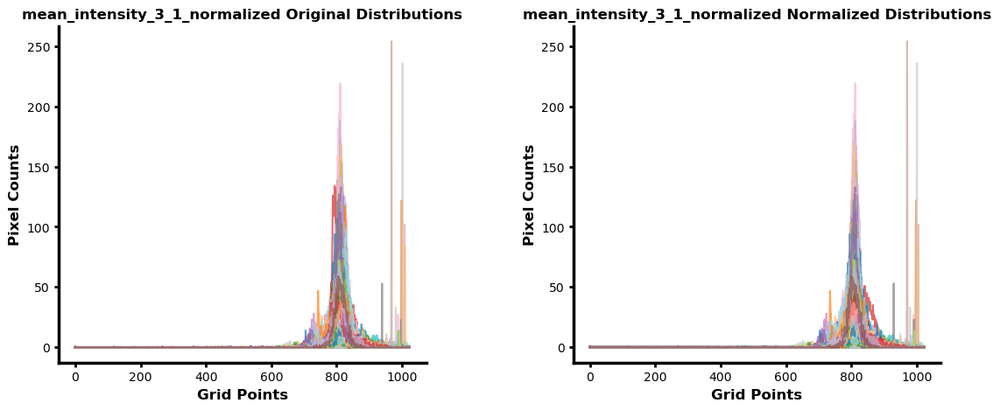


-------------------- Processing marker 'mean_intensity_3_2_normalized' --------------------
☑️ No reference provided → will select by proximity
☑️ No landmarks → automatic alignment to mean, selecting 'TMA7_21' by histogram proximity 

✨ Computed shifts: [4, 0, -1, 5, 4, 9, 21, -1, -3, -4, 4, -1, -3, 7, 2, 0, 2, 1, -2, -6, 8, 1, -6, 1, 2, 6, 1, 2, 2, 0, -1, 0, 4, 4, 0, -5, 1, 0, -5, -5, 3, 0, -4, 3, -4, 2, -5, 4, -3, -2, -3, 4, -2, 4, -4, -1, 2, -2, -1, 0, -1, -1, -1, -1, 2, 2, -1, 1, -1, -1, 0, 0, -3, 1, -2, 0, 0, 8, -2, 5, -2, 3, 1, -1, -1, 1, -1, -1, -3, -6, 2, 0, -2, 2, 4, 2, 4, -3, -2, -1, 2, -1, -1, 0, 1, -2, -2, 1, -1, 6, 0, 1, -4, 5, -3, -1, -3, 3, 1, -5, 1, 4, 1, -5, -3, 3, 0, -2, 1, 3, 14, 1, -7, -3, 1, 3, -4, -1, 1, 2, 1, -1, -3, 1, -2, 4, 5, -3, 6, -4, -3, 3, -1, 4, 1, 1, 4, -2, -1, 0, 3, 2, -3, 4, -4, -5, 4, 0, 0, 2, 3, 6, 8, 1, 0, 0, 0, 1, -4, -6, -3, 2, 2, 3, -3, 5, 0, 1, 4, 4, 4, -3, -1, -1, 0, -1, -2, 2, -2, -2, -3, -1, -1, 1, -1, 2, 5, -1, 0, -8, -1, 1, 3, 1, -2, 4, 

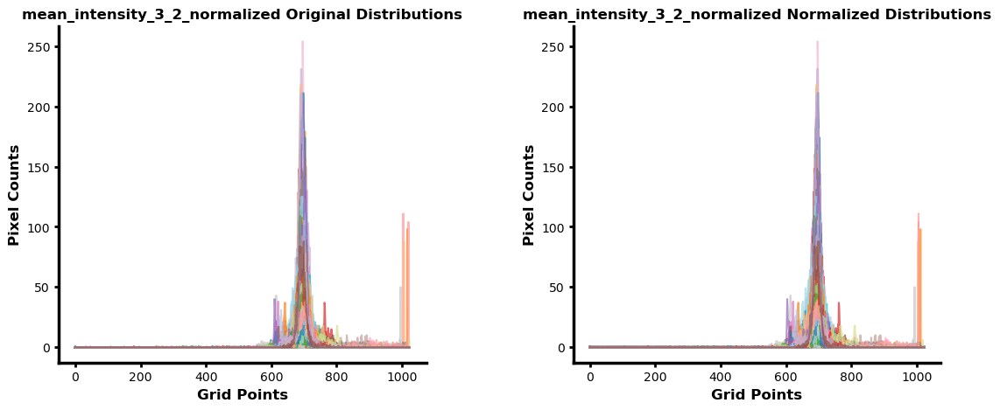


-------------------- Processing marker 'mean_intensity_3_3_normalized' --------------------
☑️ No reference provided → will select by proximity
☑️ No landmarks → automatic alignment to mean, selecting 'TMA9_58' by histogram proximity 

✨ Computed shifts: [0, 0, -3, 1, -1, -5, -4, -4, 0, -1, 0, 0, 0, -2, 0, -8, -4, 0, 6, 0, 0, 3, 0, 11, -2, 5, 1, 0, -1, 1, -1, 1, 1, 2, 0, -1, 1, 0, 2, 1, -2, -5, 0, 1, 1, 0, 3, 1, 1, -1, 0, -5, 1, 0, 1, 1, 6, 1, 0, -1, 0, 1, -1, 1, 1, -1, 1, 0, 0, -1, 0, 1, -2, 1, -1, 2, 0, 0, 0, 1, 1, 0, 1, 1, -1, 1, 2, 0, -1, 1, 1, 2, 1, -2, 1, -2, 0, -2, 4, 2, -3, -1, 1, 0, 0, 1, -2, 1, 0, -1, 0, 1, -2, 1, 1, -1, 0, -1, -1, 0, 1, 0, 2, -2, 1, 1, 1, 0, 1, -2, 0, 9, -1, -6, 3, 1, -1, 1, 0, 1, 87, 0, 1, -11, 0, 5, -1, 0, -1, -1, 1, 0, 1, -2, -1, 0, 1, 1, -1, -1, 0, 8, 0, 1, 0, 0, -3, -1, 1, 1, 21, 0, -1, 10, 1, 0, 1, -2, 1, 2, 1, -1, 0, 0, 2, 0, 0, 1, -3, 1, -1, -2, 1, 0, -1, 0, 1, 1, -2, -2, 0, 3, 1, -2, 0, 4, -1, 1, 1, 1, -1, 1, 1, 1, 2, -2, 0, 1, 0, 1, 1, 0, 0, 0, 0,

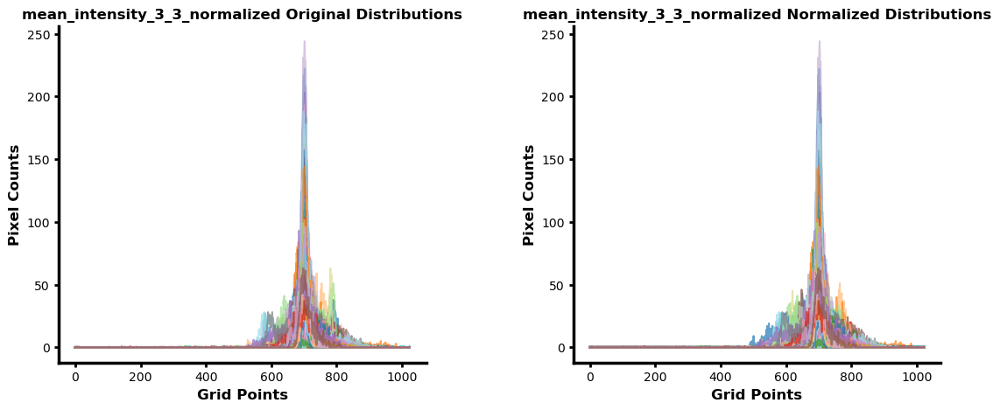


-------------------- Processing marker 'mean_intensity_4_1_normalized' --------------------
☑️ No reference provided → will select by proximity
☑️ No landmarks → automatic alignment to mean, selecting 'TMA9_15' by histogram proximity 

✨ Computed shifts: [0, -4, -5, -6, -5, -6, -1, 1, -1, -5, -3, -1, -5, 2, -4, -2, -5, 2, -4, 1, -3, -1, -4, -5, -1, 2, 2, -2, 0, -3, -5, -11, -5, -3, -2, -2, -3, -4, -6, 0, -4, -2, 0, -2, -9, -7, -8, -4, 2, -6, -1, -5, -3, -8, -3, -5, -1, -7, 1, -4, 0, -3, 16, 0, -5, 0, 1, -3, -3, -1, 0, 2, 0, -4, -3, 2, -1, -8, -6, 0, 3, -5, 0, 0, -5, -4, -11, -4, -2, -5, 0, -6, -5, 6, 2, -5, -7, -4, -1, 0, -6, 5, 2, -5, 2, -3, -1, -2, -4, 0, 2, 2, -1, -5, -6, -3, -2, 0, 2, 0, 3, -1, 0, 1, -1, -3, 0, -4, 0, 0, -6, -1, -4, -3, -2, -5, -5, -7, -6, -2, -6, 0, -5, 0, 4, -1, -5, -3, -7, -3, 1, 1, -9, -2, 0, 0, 2, -7, -3, -1, 0, -3, -15, -6, -3, -2, 0, 3, 2, 0, -3, 7, 0, -3, -5, -1, 3, -5, 1, -7, -7, 3, 1, 0, 0, -1, 2, 0, -1, -1, 0, 3, 1, 4, -7, -2, -8, -1, 0, 0, -5, -4, -6, 

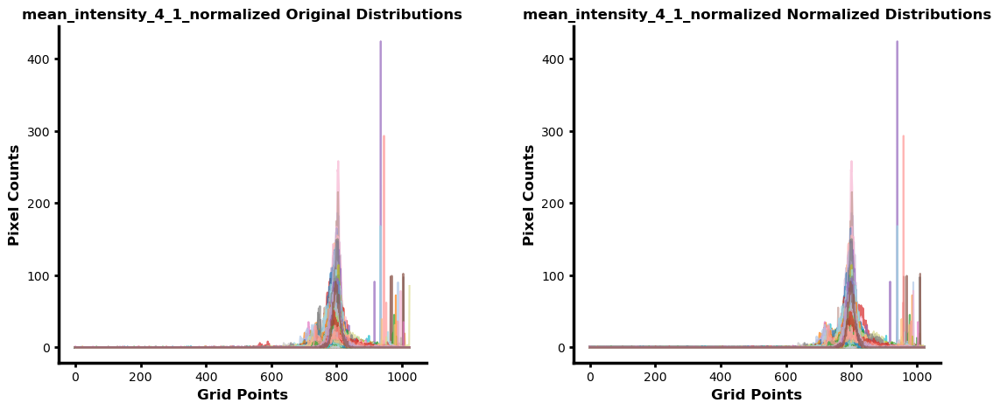


-------------------- Processing marker 'mean_intensity_4_2_normalized' --------------------
☑️ No reference provided → will select by proximity
☑️ No landmarks → automatic alignment to mean, selecting 'TMA7_91' by histogram proximity 

✨ Computed shifts: [-3, 4, 0, 1, 0, -1, 0, -4, 0, 1, -5, 1, 1, 0, 3, 1, 6, 0, 0, 2, 0, 2, 2, 4, 0, 1, 2, -1, 9, 2, 2, 0, 8, 2, 2, 0, 2, 0, 0, -1, 5, 0, -2, 1, 1, -4, 3, 2, 1, 2, 1, 3, 1, 0, 1, 1, 2, -1, 5, 1, -1, 2, -4, 5, 1, 1, 1, 4, 0, 5, 2, 0, 2, 0, -3, 1, 2, 3, 1, 3, 0, 1, 1, 1, 4, 3, 1, 1, 1, 1, 0, 3, 3, -1, 0, 2, 1, 0, 0, 0, 0, 2, 0, -1, 3, 4, 1, -4, 1, 0, 1, -2, 0, 2, 0, -1, 0, -3, 0, 2, 1, 3, 0, 2, 2, 0, 5, -2, 2, 0, -3, 0, 0, 0, 2, 4, 4, 0, 14, -4, 16, 1, 1, 1, 0, 1, 4, 0, 6, 1, 2, -2, 5, 5, -1, 3, 1, 1, 0, -2, 1, -3, 7, 4, 1, -1, 1, 0, -1, 0, 0, 2, 1, 0, 0, 3, 0, -2, -2, -4, 3, 2, 1, -2, -1, 1, -1, 1, 2, 0, 0, 1, 0, 2, 1, 1, 3, 5, 1, 3, 2, 0, 0, 0, 1, -1, 0, 27, 2, 0, 42, 1, 1, 1, 0, 0, 0, 2, 0, 1, 3, 3, 3, 5, 0, -1, 2, 1, 1, 1, 1, 2, 5, -1, 0

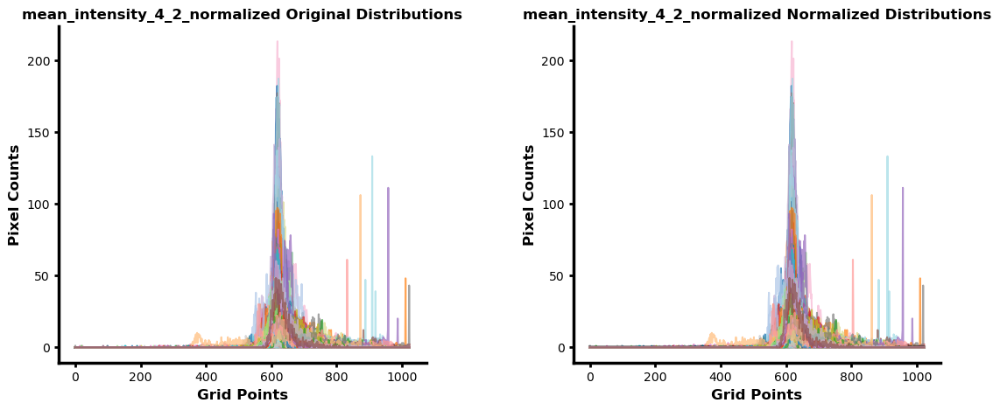


-------------------- Processing marker 'mean_intensity_4_3_normalized' --------------------
☑️ No reference provided → will select by proximity
☑️ No landmarks → automatic alignment to mean, selecting 'TMA6_54' by histogram proximity 

✨ Computed shifts: [0, 0, 0, 0, -1, -1, 0, 0, 1, 0, 1, -1, 0, 0, -1, -1, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, -1, -1, 0, -1, 0, 0, 0, 0, 0, 1, -1, -1, -1, 2, 0, 0, 0, -1, 0, 0, 0, 0, 0, 0, 0, 1, 0, -1, 0, 0, 0, 0, 0, 0, -1, 0, 0, -1, 0, 0, 0, -1, 1, 0, 0, 1, 0, 0, -1, 1, 0, 0, 0, 0, 0, 0, -1, 0, 0, 0, -1, -1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, -1, -1, 0, 0, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 1, 1, 0, -1, 0, -1, 0, 1, 0, 0, -1, -1, 0, 0, -1, 0, 1, 0, 0, 0, 0, 1, 0, 0, -1, -1, 0, 0, 0, 0, 0, 1, -1, 1, 0, 0, 0, 0, 0, 0, 0, -1, -1, 0, 0, 1, 0, -1, 0, 0, -1, -1, 0, 0, 0, 0, 0, -2, -1, 1, 0, -1, 0, 0, 0, 0, 0, -1, 0, -1, -1, 0, 0, 0, 0, 0, 0, 0, -1, 0, -1, 0, 0, 0, 2, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, -1, 1, 0, -1, 2, 1, 0, 0, 0, 0, -1, 0, 1, 1, 0, 0, 0

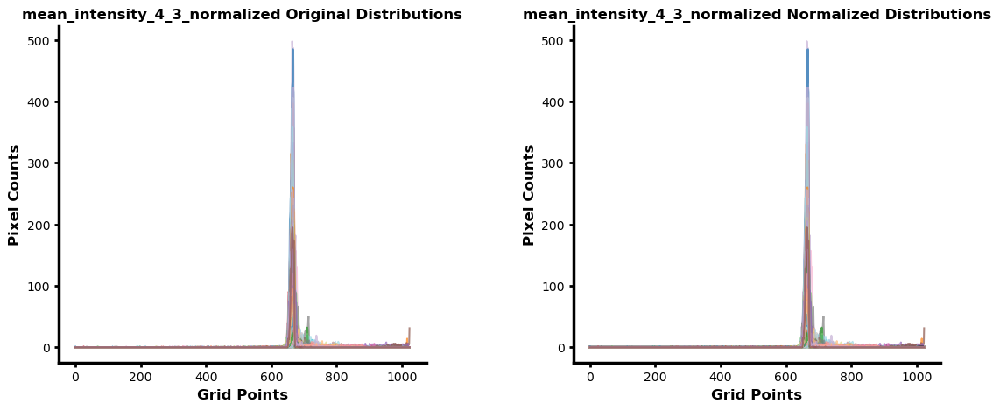


-------------------- Processing marker 'mean_intensity_5_1_normalized' --------------------
☑️ No reference provided → will select by proximity
☑️ No landmarks → automatic alignment to mean, selecting 'TMA13_95' by histogram proximity 

✨ Computed shifts: [8, 2, -4, 26, 4, 11, 13, 10, 5, 14, 11, 7, 4, 20, 3, 37, 10, -9, 5, 0, 9, 20, 3, 14, 18, 9, 15, -1, 12, 2, 11, -2, 7, 5, 2, 6, 0, 4, 2, -3, 4, 5, -3, 0, 3, 1, 7, -2, 2, 3, 11, 18, 10, 10, -8, 2, -7, -6, 1, 7, 6, 9, -17, -3, -1, -15, 5, 21, 10, 7, 6, -9, 3, 8, 2, 0, -7, 11, 6, 2, -6, 6, -2, 1, -7, 2, -19, 2, 0, -4, 1, 12, 10, -1, 6, 5, 0, -9, 9, -4, -2, 7, -2, 12, 2, -7, 28, 0, 5, 2, 3, 10, 2, 1, -6, 2, 8, 2, 5, 0, 7, 5, 9, 1, -3, 12, -8, 7, 2, 2, -4, -2, 9, -4, 6, 0, 1, 0, -2, 11, 55, -2, 2, -22, 6, 1, -1, 2, 15, 3, 1, 14, 8, 24, -7, 17, 3, -1, -22, -1, 1, 7, 3, 3, -4, -3, 2, 16, 7, 3, -8, 36, -4, -4, 16, 12, 1, 26, 10, 7, 20, 3, 1, 16, 4, 15, 14, 1, 8, -2, 12, 24, 0, -2, 3, 3, -2, 10, 6, 3, -1, 4, 3, 16, -3, 1, 10, -6, -9, -5, 6, -

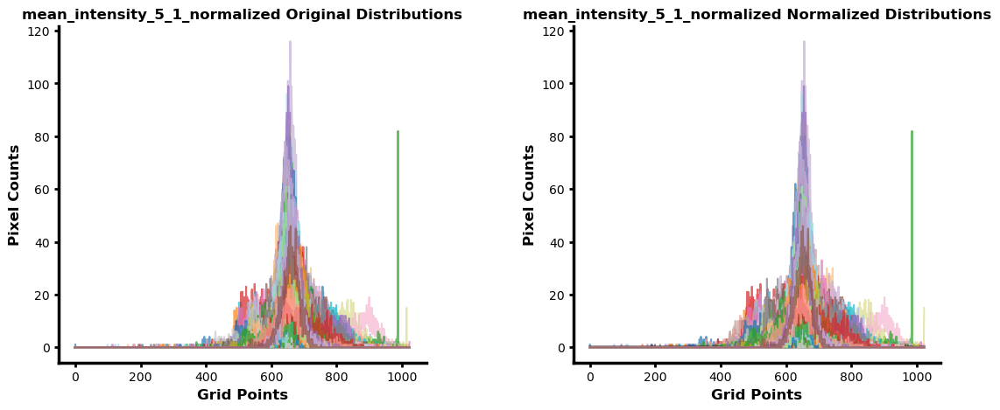


-------------------- Processing marker 'mean_intensity_5_2_normalized' --------------------
☑️ No reference provided → will select by proximity
☑️ No landmarks → automatic alignment to mean, selecting 'TMA5_14' by histogram proximity 

✨ Computed shifts: [1, -1, 0, -6, -3, -3, 0, 1, 1, 0, -8, -3, 4, 3, 1, 4, 10, -1, 1, 2, -2, -7, 5, -14, 0, -2, -2, 1, 1, -3, -6, 0, 2, -3, 2, -6, 2, 3, 4, 0, 1, -1, 3, -1, -1, -12, -1, 0, -3, 1, 1, -3, 2, -5, -1, -2, -4, -1, -2, -1, -3, 5, -35, 5, 0, 3, -3, 0, -2, 2, -3, 3, -4, 1, -1, 1, -1, -6, -4, -1, -1, -6, -3, 1, -2, -3, 6, 3, -3, 3, 1, -7, -8, -3, 0, -7, -7, 6, -6, 5, -1, -2, 4, 3, -6, -3, 0, 0, -4, 5, 0, 3, -1, -7, -7, -1, 0, 6, -1, 1, -2, 2, 1, 3, -3, 0, -1, 3, 2, 5, -2, -5, 2, 1, 1, 0, -4, 5, -15, -4, 1, -2, -3, -2, 3, 0, 0, -1, -1, 6, -12, 3, -3, 2, 2, -7, -6, -3, -23, -3, 4, 3, 0, 3, 0, 2, -35, -1, -13, 0, 1, 1, -8, -1, -7, -1, 0, 3, -4, -2, -6, -1, 0, 3, 4, -2, -1, -1, 3, -5, 0, 2, 0, 0, 1, 6, -4, -2, 2, -4, 2, 0, -4, 2, 0, 1, -4, -2, -6, 3,

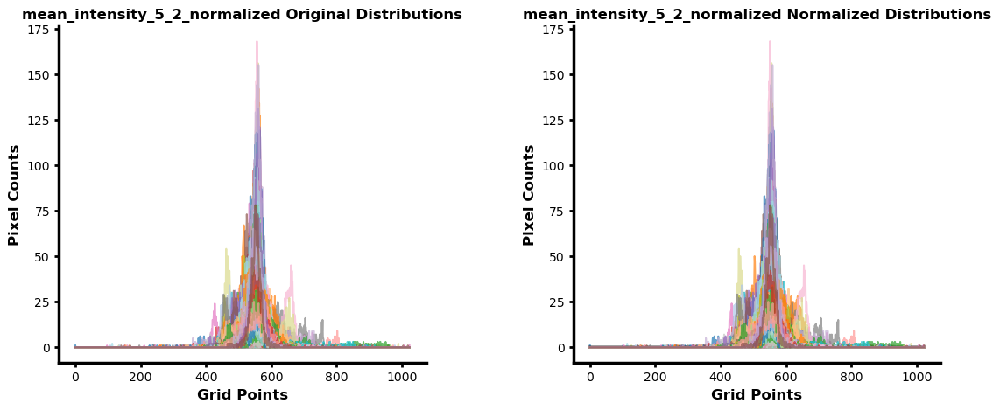


-------------------- Processing marker 'mean_intensity_5_3_normalized' --------------------
☑️ No reference provided → will select by proximity
☑️ No landmarks → automatic alignment to mean, selecting 'TMA6_9' by histogram proximity 

✨ Computed shifts: [0, 1, 0, -1, -1, -3, -1, 0, 0, -3, -2, 0, 0, -1, -1, -1, 0, 0, -1, -1, -1, 1, 0, 0, -2, -1, 0, -1, 0, -2, -1, -2, 0, -1, -1, -2, 0, 1, 0, -1, 0, 0, 0, 0, -2, -1, -1, 0, 0, -1, -1, -2, 0, -2, -1, 0, 0, -1, 0, -2, -1, -3, 0, 0, -1, -2, 0, -1, -1, -3, 0, -1, 0, 0, 0, 1, 1, 0, 0, -1, -1, 1, -1, 0, 0, -1, 0, 0, 0, 0, -1, -1, 0, 1, -1, -1, 1, 0, -2, 0, -1, -1, 0, 0, -1, -1, -1, 0, 0, -1, 0, 0, 0, 0, -2, 0, 0, 0, -1, 0, 0, 0, -2, -1, 0, 0, 0, 0, 0, 2, -2, 1, 0, 0, 1, -1, -3, 0, 0, -1, -1, 0, 0, 0, -1, 0, 0, -1, 0, 0, -1, 0, 0, 0, -1, -1, -3, -1, 0, 0, 0, 0, 0, -1, -1, 0, -8, -1, -3, 0, 0, -1, 0, -2, 0, 0, -2, -2, 0, -1, -1, -1, 0, -1, 0, 0, 0, 0, -2, -2, 0, 0, -2, -1, -1, -1, -1, 0, -1, -1, 0, -1, 0, -3, -1, 0, 0, 1, 0, -1, -3, 0, -2, 0, 0, 

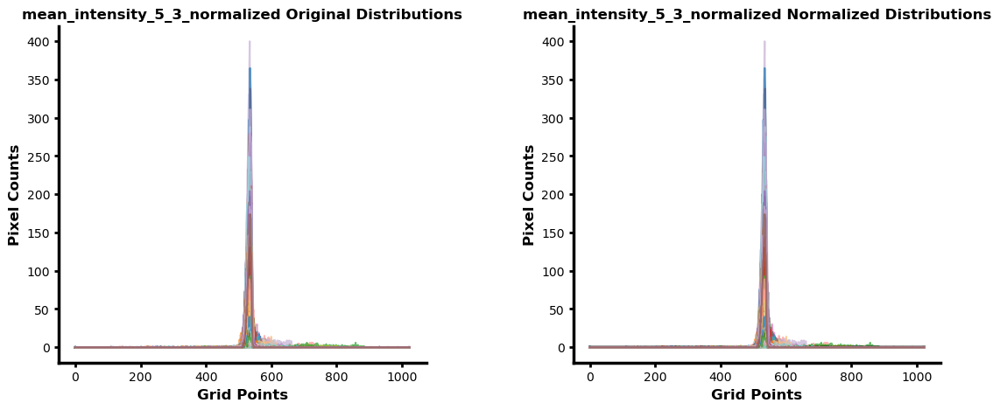

In [12]:
shifts_map, chosen_references, implied_landmarks_map = automatic_registration(
    histogram_data      = histograms,
    all_markers         = adata.var['marker_name'].tolist(),
    selected_markers    = adata.var['marker_name'].tolist(),
    sample_ids          = adata.obs['sample_id'].unique().tolist(),
    reference_samples   = None,
    landmark_map        = landmark,
    num_bins            = 1024,
    dpi                 = 100,
    x_limits            = None
)

In [13]:
generate_normalized_feature(
    feature_input            = adata,
    sample_ids               = None,
    markers                  = None,
    intensity_ranges         = intensity_ranges,
    shifts_map               = shifts_map,
    chosen_references        = chosen_references,
    num_bins                 = 1024, 
    dpi                      = 100,
    plot_dist                = False, 
    plot_single_cell_corr    = False, 
    gmm_analysis             = False,
    save_normalized_features = True
)

##############################Performing feature normalization##############################



Samples:   0%|                                 | 2/1071 [00:00<01:40, 10.68it/s]

******************************  Normalizing TMA9_15 ******************************
⏳ mean_intensity ...
⏳ Normalizing mean_intensity | reference=TMA9_13 | scale factor=1.1356913784781335
⏳ mean_intensity_0_1 ...
⏳ Normalizing mean_intensity_0_1 | reference=TMA11_78 | scale factor=1.1751370396714957
⏳ mean_intensity_0_2 ...
⏳ Normalizing mean_intensity_0_2 | reference=TMA11_87 | scale factor=0.5638082808814171
⏳ mean_intensity_0_3 ...
⏳ Normalizing mean_intensity_0_3 | reference=TMA0_24 | scale factor=0.8849997293768636
⏳ mean_intensity_1_1 ...
⏳ Normalizing mean_intensity_1_1 | reference=TMA14_89 | scale factor=0.9557397489217372
⏳ mean_intensity_1_2 ...
⏳ Normalizing mean_intensity_1_2 | reference=TMA11_27 | scale factor=0.7229830794873583
⏳ mean_intensity_1_3 ...
⏳ Normalizing mean_intensity_1_3 | reference=TMA0_31 | scale factor=0.9282742743317228
⏳ mean_intensity_2_1 ...
⏳ Normalizing mean_intensity_2_1 | reference=TMA6_37 | scale factor=1.127727641110442
⏳ mean_intensity_2_2 ...
⏳

Samples:   0%|                                 | 4/1071 [00:00<01:39, 10.77it/s]

******************************  Normalizing TMA14_75 ******************************
⏳ mean_intensity ...
⏳ Normalizing mean_intensity | reference=TMA9_13 | scale factor=1.1019765586253774
⏳ mean_intensity_0_1 ...
⏳ Normalizing mean_intensity_0_1 | reference=TMA11_78 | scale factor=0.7610070262809256
⏳ mean_intensity_0_2 ...
⏳ Normalizing mean_intensity_0_2 | reference=TMA11_87 | scale factor=0.7634215272389865
⏳ mean_intensity_0_3 ...
⏳ Normalizing mean_intensity_0_3 | reference=TMA0_24 | scale factor=0.5203087491423053
⏳ mean_intensity_1_1 ...
⏳ Normalizing mean_intensity_1_1 | reference=TMA14_89 | scale factor=1.0
⏳ mean_intensity_1_2 ...
⏳ Normalizing mean_intensity_1_2 | reference=TMA11_27 | scale factor=0.8864947414882907
⏳ mean_intensity_1_3 ...
⏳ Normalizing mean_intensity_1_3 | reference=TMA0_31 | scale factor=1.0093469165747435
⏳ mean_intensity_2_1 ...
⏳ Normalizing mean_intensity_2_1 | reference=TMA6_37 | scale factor=0.894976195873022
⏳ mean_intensity_2_2 ...
⏳ Normalizing m

...

******************************  Normalizing TMA9_95 ******************************
⏳ mean_intensity ...
⏳ Normalizing mean_intensity | reference=TMA9_13 | scale factor=0.7831446758935602
⏳ mean_intensity_0_1 ...
⏳ Normalizing mean_intensity_0_1 | reference=TMA11_78 | scale factor=0.951555892604047
⏳ mean_intensity_0_2 ...
⏳ Normalizing mean_intensity_0_2 | reference=TMA11_87 | scale factor=0.5967777582572056
⏳ mean_intensity_0_3 ...
⏳ Normalizing mean_intensity_0_3 | reference=TMA0_24 | scale factor=1.5213837990893306
⏳ mean_intensity_1_1 ...
⏳ Normalizing mean_intensity_1_1 | reference=TMA14_89 | scale factor=0.9557397489217372
⏳ mean_intensity_1_2 ...
⏳ Normalizing mean_intensity_1_2 | reference=TMA11_27 | scale factor=0.7572733714483338
⏳ mean_intensity_1_3 ...
⏳ Normalizing mean_intensity_1_3 | reference=TMA0_31 | scale factor=0.8537135391568585
⏳ mean_intensity_2_1 ...
⏳ Normalizing mean_intensity_2_1 | reference=TMA6_37 | scale factor=1.271769632524522
⏳ mean_intensity_2_2 ...
⏳ 

Samples: 100%|█████████████████████████████▉| 1070/1071 [01:42<00:00,  6.74it/s]

******************************  Normalizing TMA3_21 ******************************
⏳ mean_intensity ...
⏳ Normalizing mean_intensity | reference=TMA9_13 | scale factor=1.5558113373120424
⏳ mean_intensity_0_1 ...
⏳ Normalizing mean_intensity_0_1 | reference=TMA11_78 | scale factor=0.6839469513539888
⏳ mean_intensity_0_2 ...
⏳ Normalizing mean_intensity_0_2 | reference=TMA11_87 | scale factor=0.9139479591367854
⏳ mean_intensity_0_3 ...
⏳ Normalizing mean_intensity_0_3 | reference=TMA0_24 | scale factor=0.2308435023269081
⏳ mean_intensity_1_1 ...
⏳ Normalizing mean_intensity_1_1 | reference=TMA14_89 | scale factor=0.7621455028368254
⏳ mean_intensity_1_2 ...
⏳ Normalizing mean_intensity_1_2 | reference=TMA11_27 | scale factor=0.9636079138663721
⏳ mean_intensity_1_3 ...
⏳ Normalizing mean_intensity_1_3 | reference=TMA0_31 | scale factor=1.0
⏳ mean_intensity_2_1 ...
⏳ Normalizing mean_intensity_2_1 | reference=TMA6_37 | scale factor=0.7647939089826288
⏳ mean_intensity_2_2 ...
⏳ Normalizing m

Samples: 100%|██████████████████████████████| 1071/1071 [01:42<00:00, 10.42it/s]


✅ Saved normalized data to adata.layers['normalized'].
✅ Wrote AnnData to 'Anndata_Normalized.h5ad'.
🎉 Feature normalization complete!


Markers:   0%|                                           | 0/38 [00:00<?, ?it/s]

✅ Processing TMA0_3 for marker mean_intensity......
✅ Processing TMA0_4 for marker mean_intensity......
✅ Processing TMA0_5 for marker mean_intensity......
✅ Processing TMA0_6 for marker mean_intensity......
✅ Processing TMA0_8 for marker mean_intensity......
✅ Processing TMA0_9 for marker mean_intensity......
✅ Processing TMA0_11 for marker mean_intensity......
✅ Processing TMA0_12 for marker mean_intensity......
✅ Processing TMA0_13 for marker mean_intensity......
✅ Processing TMA0_14 for marker mean_intensity......
✅ Processing TMA0_15 for marker mean_intensity......
✅ Processing TMA0_16 for marker mean_intensity......
✅ Processing TMA0_17 for marker mean_intensity......
✅ Processing TMA0_18 for marker mean_intensity......
✅ Processing TMA0_19 for marker mean_intensity......
✅ Processing TMA0_20 for marker mean_intensity......
✅ Processing TMA0_21 for marker mean_intensity......
✅ Processing TMA0_22 for marker mean_intensity......
✅ Processing TMA0_23 for marker mean_intensity......

Markers:   3%|▉                                  | 1/38 [00:09<06:04,  9.84s/it]

✅ Processing TMA0_3 for marker mean_intensity_0_1......
✅ Processing TMA0_4 for marker mean_intensity_0_1......
✅ Processing TMA0_5 for marker mean_intensity_0_1......
✅ Processing TMA0_6 for marker mean_intensity_0_1......
✅ Processing TMA0_8 for marker mean_intensity_0_1......
✅ Processing TMA0_9 for marker mean_intensity_0_1......
✅ Processing TMA0_11 for marker mean_intensity_0_1......
✅ Processing TMA0_12 for marker mean_intensity_0_1......
✅ Processing TMA0_13 for marker mean_intensity_0_1......
✅ Processing TMA0_14 for marker mean_intensity_0_1......
✅ Processing TMA0_15 for marker mean_intensity_0_1......
✅ Processing TMA0_16 for marker mean_intensity_0_1......
✅ Processing TMA0_17 for marker mean_intensity_0_1......
✅ Processing TMA0_18 for marker mean_intensity_0_1......
✅ Processing TMA0_19 for marker mean_intensity_0_1......
✅ Processing TMA0_20 for marker mean_intensity_0_1......
✅ Processing TMA0_21 for marker mean_intensity_0_1......
✅ Processing TMA0_22 for marker mean_

Markers:   5%|█▊                                 | 2/38 [00:24<07:30, 12.53s/it]

...

✅ Processing TMA0_3 for marker mean_intensity_5_2_normalized......
✅ Processing TMA0_4 for marker mean_intensity_5_2_normalized......
✅ Processing TMA0_5 for marker mean_intensity_5_2_normalized......
✅ Processing TMA0_6 for marker mean_intensity_5_2_normalized......
✅ Processing TMA0_8 for marker mean_intensity_5_2_normalized......
✅ Processing TMA0_9 for marker mean_intensity_5_2_normalized......
✅ Processing TMA0_11 for marker mean_intensity_5_2_normalized......
✅ Processing TMA0_12 for marker mean_intensity_5_2_normalized......
✅ Processing TMA0_13 for marker mean_intensity_5_2_normalized......
✅ Processing TMA0_14 for marker mean_intensity_5_2_normalized......
✅ Processing TMA0_15 for marker mean_intensity_5_2_normalized......
✅ Processing TMA0_16 for marker mean_intensity_5_2_normalized......
✅ Processing TMA0_17 for marker mean_intensity_5_2_normalized......
✅ Processing TMA0_18 for marker mean_intensity_5_2_normalized......
✅ Processing TMA0_19 for marker mean_intensity_5_2_nor

Markers:  97%|█████████████████████████████████ | 37/38 [08:55<00:14, 14.48s/it]

✅ Processing TMA0_3 for marker mean_intensity_5_3_normalized......
✅ Processing TMA0_4 for marker mean_intensity_5_3_normalized......
✅ Processing TMA0_5 for marker mean_intensity_5_3_normalized......
✅ Processing TMA0_6 for marker mean_intensity_5_3_normalized......
✅ Processing TMA0_8 for marker mean_intensity_5_3_normalized......
✅ Processing TMA0_9 for marker mean_intensity_5_3_normalized......
✅ Processing TMA0_11 for marker mean_intensity_5_3_normalized......
✅ Processing TMA0_12 for marker mean_intensity_5_3_normalized......
✅ Processing TMA0_13 for marker mean_intensity_5_3_normalized......
✅ Processing TMA0_14 for marker mean_intensity_5_3_normalized......
✅ Processing TMA0_15 for marker mean_intensity_5_3_normalized......
✅ Processing TMA0_16 for marker mean_intensity_5_3_normalized......
✅ Processing TMA0_17 for marker mean_intensity_5_3_normalized......
✅ Processing TMA0_18 for marker mean_intensity_5_3_normalized......
✅ Processing TMA0_19 for marker mean_intensity_5_3_nor

Markers: 100%|██████████████████████████████████| 38/38 [09:08<00:00, 14.44s/it]


✅ Saved summary figure to: adata_feature_distributions_normalized.svg


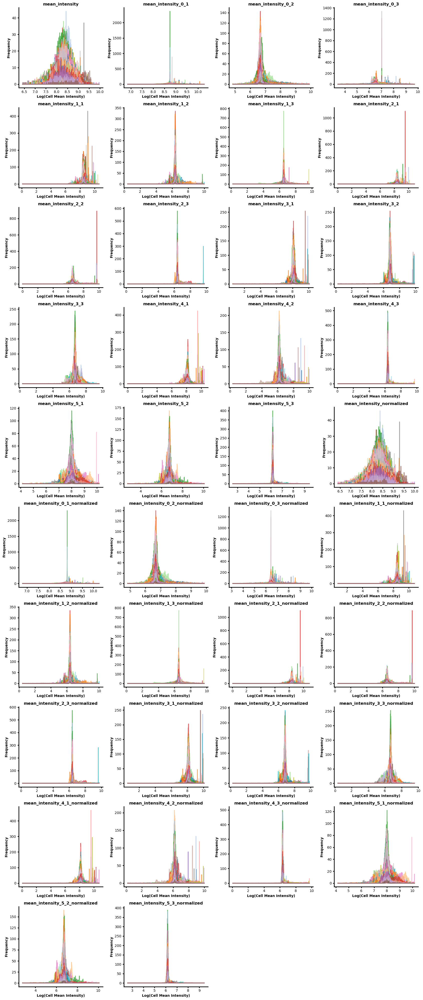

In [14]:
intensity_ranges, histograms, gmm_models = process_sample_distributions(
    feature_input       = adata,
    use_normalized      = True,
    num_bins            = 1024,
    plots_per_row       = 4,
    dpi                 = 100,
    xlims               = None,
    ylims               = None,
    output_figure_path  = "adata_feature_distributions_normalized.svg",
    verbose=True
) 